# Thực hành Bài 08 — Deep Q-Learning trên CartPole, Lunar Lander và Flappy Bird

Học phần Học tăng cường · Học kỳ 1, năm học 2026–2027.

Ở Bài 07, giá trị hành động được xấp xỉ bằng hàm tuyến tính $\hat q(s,a,w)=x(s,a)^\top w$, với $x(s,a)$ là vector đặc trưng chọn bằng tay và $w$ là vector trọng số: notebook Flappy Bird của Bài 07 dựng bốn đại lượng dẫn xuất và cơ sở Fourier $256$ chiều, rồi đạt trung bình $28{,}9$ ống với Q-learning tuyến tính và $38{,}0$ ống với Sarsa tuyến tính trên $100$ lượt đánh giá (cùng tập hạt giống (seed) `TEST_SEED` với notebook này). Bài 08 thay đặc trưng chọn tay bằng một mạng nơ-ron $\mathbf q_\theta(o)\in\mathbb R^{\lvert\mathcal A\rvert}$ nhận thẳng quan sát, và thay cập nhật từng mẫu chuyển bằng Thuật toán 08.13, mạng Q sâu (Deep Q-Network, DQN): bộ nhớ phát lại (experience replay), mạng mục tiêu (target network), hàm mất mát trên mini-batch và hai bộ đếm $t$, $k_{\mathrm{opt}}$. Notebook cài đặt đúng thuật toán đó bằng PyTorch rồi chạy trên ba môi trường của Gymnasium: `CartPole-v1`, `LunarLander-v3` (hành động rời rạc, không gió) và `FlappyBird-v0` với quan sát $12$ chiều.

**Mục tiêu.** Sau bài thực hành, người học có thể:

1. cài đặt mạng giá trị hành động, bộ nhớ phát lại dạng bộ đệm vòng và mục tiêu hồi quy $y_i=R_i+\gamma(1-Z_i)\max_{a'}Q_{\theta^-}(O'_i,a')$, kiểm tra từng phép tính bằng số liệu của Bài tập 08.1;
2. cài đặt vòng huấn luyện của Thuật toán 08.13 với hai bộ đếm và kiểm tra lịch tối ưu, lịch đồng bộ bằng Ví dụ 08.15;
3. huấn luyện DQN trên ba môi trường, đánh giá chính sách tham lam trên $100$ lượt riêng với trung bình, độ lệch chuẩn, sai số chuẩn và so sánh ghép cặp với chính sách tham chiếu;
4. trực quan hóa chính sách tham chiếu và chính sách học được bằng trình phát hoạt hình, dải ảnh tĩnh và đường học;
5. đọc kết quả của thí nghiệm loại bỏ (ablation) mạng mục tiêu và bộ nhớ phát lại, đối chiếu với Nhận xét 08.19–08.21 và bộ ba bất ổn.

**Tiên quyết.** Ghi chú Bài 08: phần 2 (Định nghĩa 08.1, 08.3, 08.4, 08.6), phần 3 (Định nghĩa 08.7), phần 4 (Định nghĩa 08.10, 08.12, Thuật toán 08.13, Nhận xét 08.14), phần 5 (Định nghĩa 08.18, Adam), phần 6 (Nhận xét 08.19–08.21). Các notebook thực hành Bài 04 (CartPole) và Bài 07 (Lunar Lander, Flappy Bird): notebook này dùng lại hai chính sách tham chiếu và cách đánh giá của chúng. Python, NumPy và các thao tác cơ bản của PyTorch (tensor, `nn.Module`, `backward`).

**Bảng ký hiệu** (thống nhất với ghi chú Bài 08):

| Ký hiệu | Ý nghĩa | Biến trong mã, kích thước |
|---|---|---|
| $O_t$, $n$ | quan sát đưa vào mạng ở bước $t$; số chiều của quan sát ($4$, $8$, $12$) | `o`, cỡ `(n,)` |
| $A_t\in\mathcal A$, $\lvert\mathcal A\rvert$ | hành động; số hành động ($2$, $4$, $2$) | `a`; `n_act` |
| $R_{t+1}$ | phần thưởng nhận sau $A_t$ | `r` |
| $Z_{t+1}$, $U_{t+1}$ | cờ kết thúc của MDP; cờ cắt ngắn ngoài mô hình | `term`, `trunc` của `env.step` |
| $\theta$, $\theta^-$ | tham số mạng trực tuyến; tham số mạng mục tiêu | `q_net`, `tgt_net` |
| $\mathbf q_\theta(o)$, $Q_\theta(o,a)$ | vector giá trị hành động; thành phần của hành động $a$ | `q_net(O)`, cỡ `(b, n_act)` |
| $\mathcal D$, $N$ | bộ nhớ phát lại; dung lượng | `Replay`, `cfg["N"]` |
| $b$, $i$ | cỡ mini-batch; chỉ số mẫu trong mini-batch | `cfg["b"]` |
| $(O_i,A_i,R_i,O'_i,Z_i,U_i)$ | mẫu chuyển sáu thành phần | `O, A, R, O2, Z, U`, cỡ `(b,n)`, `(b,)`, `(b,)`, `(b,n)`, `(b,)`, `(b,)` |
| $q_i$, $y_i$, $\delta_i$ | dự đoán $Q_\theta(O_i,A_i)$; mục tiêu hồi quy; sai số sai phân thời gian (temporal difference, TD) $y_i-q_i$ | `q`, `y`, cỡ `(b,)` |
| $L_B(\theta)$ | hàm mất mát trên mini-batch, $\tfrac1b\sum_i(y_i-q_i)^2$ | `L`, vô hướng |
| $\operatorname{sg}$ | phép dừng gradient (stop-gradient) | khối `torch.no_grad()` |
| $t$, $k_{\mathrm{opt}}$ | bộ đếm bước môi trường; bộ đếm bước tối ưu | `t`, `k_opt` |
| $N_{\mathrm{start}}$, $F$, $C$, $T$ | số mẫu trước bước tối ưu đầu; số bước môi trường giữa hai bước tối ưu; số bước tối ưu giữa hai lần đồng bộ; ngân sách bước môi trường | `cfg["N_start"]`, `cfg["F"]`, `cfg["C"]`, `cfg["T"]` |
| $\epsilon_{\mathrm{exp}}$, $\rho$ | xác suất thăm dò của hành vi; phần của $T$ trong đó $\epsilon_{\mathrm{exp}}$ giảm tuyến tính | `linear_eps(t, ...)`; `cfg["eps_frac"]` |
| $\eta$ | tốc độ học của bộ tối ưu Adam | `cfg["lr"]` |
| $\gamma$ | hệ số chiết khấu, $0{,}99$ | `GAMMA` |
| $G_t$, $G_0$ | lợi tức chiết khấu tính từ bước $t$ của một lượt; từ đầu lượt | `G0` |
| $N_{\mathrm{ev}}$, SE | số lượt của một phép đánh giá; sai số chuẩn của trung bình | `N_TEST`, `N_VALID`; `se` |
| $L$ | độ dài (số bước) của một lượt đã ghi | `len(ep["actions"])` |
| $\pi_1$, $\pi_2$ | hai chính sách trong một phép so sánh ghép cặp | `res_a`, `res_b` |
| lượt | một episode: từ `reset` tới khi $Z=1$ hoặc $U=1$ | (khái niệm) |
| ô mã | một ô chứa mã Python của notebook | (khái niệm) |

Mạng trực tuyến (online network) là mạng có tham số $\theta$ được cập nhật ở mỗi bước tối ưu; mạng mục tiêu giữ $\theta^-$ cố định giữa hai lần đồng bộ (Định nghĩa 08.3).

**Cách dùng.** Chạy các ô mã theo thứ tự từ trên xuống; ô cài đặt ở mục 1 tự cài các gói cần thiết, nên notebook chạy được trên Jupyter cục bộ hoặc Google Colab mà không cần tệp nào khác. Mọi phép ngẫu nhiên dùng hạt giống cố định. Trên cùng máy, cùng phiên bản gói và cùng số luồng CPU, chạy lại cho cùng số liệu; với phiên bản PyTorch hoặc số luồng khác, phép cộng dấu phẩy động đổi thứ tự và số liệu huấn luyện lệch theo. Vì vậy các đoạn **Đọc kết quả** dựa trên bảng nhiều hạt giống ở mục 10–11 (chạy khi soạn), không dựa trên con số của một lần chạy trong notebook.

Khi soạn, mục 1–14 chạy khoảng $10$ phút trên CPU hai luồng, cộng $1$–$2$ phút cài gói khi chạy trong một môi trường Python mới, và mục 15 (biến thể của DQN) thêm khoảng $4$ phút; một lần chạy kiểm thử độc lập của mục 1–14 mất khoảng $13$ phút tính cả cài gói. Tổng thời gian tính toán in ở cuối mục 13 và cuối mục 15; phần lớn thời gian là ba lần huấn luyện ở mục 7–9 và hai lần huấn luyện của mục 11. Trên Colab có thể lâu hơn. Không cần GPU. Đặt `LONG_BUDGET = True` ở mục 1 để chạy Flappy Bird với ngân sách $T$ lớn hơn (thêm khoảng $2$ phút). Các mục **Câu hỏi:** có lời giải thu gọn.

## 1. Cài đặt và chuẩn bị

Ô mã dưới cài Gymnasium kèm phần mở rộng `box2d` (bộ mô phỏng vật lý của Lunar Lander), gói `flappy-bird-gymnasium`, NumPy và Matplotlib, rồi cài PyTorch bản CPU nếu môi trường chưa có. Colab có sẵn PyTorch nên bỏ qua bước này; trên máy cục bộ, bản CPU nhẹ hơn nhiều so với bản mặc định kèm thư viện CUDA.

`pip` có thể in dòng *Note: you may need to restart the kernel to use updated packages*. Khi ô cài đặt được chạy trước mọi lệnh `import`, không cần khởi động lại. Nếu trước đó đã `import` một bản cũ của gói vừa được nâng cấp, cần khởi động lại kernel rồi chạy lại từ đầu. `pip` có thể báo xung đột giữa `pygame` và `pygame-ce` (gặp trên Colab và cả trên máy cục bộ: phần mở rộng `box2d` của Gymnasium 1.4 cài `pygame-ce`, còn `flappy-bird-gymnasium` cài `pygame`); notebook không gọi `render`, nên có thể bỏ qua cảnh báo này.

In [1]:
%pip install -q "gymnasium[box2d]>=1.0" "flappy-bird-gymnasium>=0.4" numpy matplotlib
import importlib.util
if importlib.util.find_spec("torch") is None:       # Colab có sẵn torch; máy cục bộ chưa có thì cài bản CPU
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Ô mã dưới nhập các gói, in phiên bản và đặt các hằng số dùng chung. Bốn tập hạt giống tách rời nhau: lượt huấn luyện thứ $k$ dùng `TRAIN_SEED + k`; mốc kiểm định trong lúc huấn luyện dùng `VALID_SEED + i`, $i<10$; đánh giá cuối dùng `TEST_SEED + i`, $i<100$; `AGENT_SEED` khởi tạo $\theta$, phép thăm dò và phép rút mini-batch. `torch.set_num_threads(2)` khớp với hai lõi CPU của Colab và với lần chạy khi soạn.

In [2]:
import copy, hashlib, inspect, json, time
from importlib.metadata import version

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import patches
import gymnasium as gym
import flappy_bird_gymnasium  # noqa: F401  (đăng ký môi trường FlappyBird-v0)
from gymnasium.envs.box2d import lunar_lander as ll
import torch
import torch.nn as nn
from IPython.display import HTML, display

T_START = time.time()                      # đo tổng thời gian chạy notebook
torch.set_num_threads(2)                   # số luồng CPU; số liệu huấn luyện phụ thuộc giá trị này
print("gymnasium", gym.__version__, "| flappy-bird-gymnasium", version("flappy-bird-gymnasium"),
      "| torch", torch.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

GAMMA = 0.99            # hệ số chiết khấu gamma
TRAIN_SEED = 120_000    # lượt huấn luyện thứ k: reset(seed=TRAIN_SEED + k)
VALID_SEED = 40_000     # 10 lượt kiểm định ở mỗi mốc trong lúc huấn luyện
TEST_SEED = 30_000      # 100 lượt đánh giá cuối, dùng chung cho mọi chính sách
AGENT_SEED = 1          # khởi tạo theta, thăm dò và rút mini-batch
N_TEST, N_VALID = 100, 10
LONG_BUDGET = False     # True: Flappy Bird huấn luyện T = 500 000 bước thay cho 300 000

gymnasium 1.4.0 | flappy-bird-gymnasium 0.4.0 | torch 2.14.1+cpu | numpy 2.5.4 | matplotlib 3.11.2


## 2. Ba môi trường

**Vấn đề.** Thuật toán 08.13 cần ở mỗi bước môi trường ba thứ: quan sát $O_{t+1}$ dưới dạng vector số thực, phần thưởng $R_{t+1}$ và hai cờ $Z_{t+1}$, $U_{t+1}$ tách riêng. Trước khi huấn luyện, cần biết mỗi môi trường trả các đại lượng đó ra sao.

| Môi trường | Quan sát $O_t$ | $\lvert\mathcal A\rvert$ | Phần thưởng | $Z=1$ khi | $U=1$ khi |
|---|---|---|---|---|---|
| `CartPole-v1` | $(x,\dot x,\phi,\dot\phi)$, $n=4$ | $2$: đẩy trái, đẩy phải | $+1$ mỗi bước | $\lvert\phi\rvert>12^\circ$ hoặc $\lvert x\rvert>2{,}4$ | lượt đạt $500$ bước |
| `LunarLander-v3` | vị trí, vận tốc, góc, vận tốc góc, hai cờ chân chạm đất, $n=8$ | $4$: không bật, động cơ trái, động cơ chính, động cơ phải | độ tăng của hàm định hình trừ nhiên liệu; $-100$ khi rơi, $+100$ khi nằm yên | thân tàu chạm đất, ra khỏi khung hình hoặc nằm yên | lượt đạt $1000$ bước |
| `FlappyBird-v0` | ba ống (tọa độ ngang, đỉnh khe, đáy khe), độ cao, vận tốc dọc và góc của chim, $n=12$ | $2$: không làm gì, vỗ cánh | $+0{,}1$ mỗi bước sống, $+1$ khi qua ống, $-0{,}5$ khi chạm mép trên, $-1$ khi chết | chim chạm ống hoặc mặt đất | chim đã qua $50$ ống (`score_limit=50`) |

Mệnh đề 08.8 (mục tiêu một bước không phụ thuộc hành vi đã sinh mẫu) dựa trên hai giả thiết: quan sát đủ Markov (Nhận xét 08.2) và động lực của môi trường không đổi theo thời gian. Cả ba môi trường có động lực không đổi. Mức độ thỏa giả thiết thứ nhất, đọc từ mã nguồn của môi trường:

| Môi trường | Quan sát đủ Markov? |
|---|---|
| `CartPole-v1` | Có: bốn biến là toàn bộ trạng thái mà mô phỏng dùng để tính bước kế tiếp. |
| `LunarLander-v3` | Không chặt: quan sát không chứa độ cao địa hình (rút ngẫu nhiên ở mỗi `reset`) và chỉ cho biết hai chân có chạm đất hay không, không cho góc và vận tốc của khớp chân. Bãi đáp luôn phẳng và nằm giữa khung hình, nên khi tàu hạ trên bãi, phần thiếu này ảnh hưởng ít; khi tàu chạm đất ngoài bãi, hai lượt có cùng quan sát có thể có kết cục khác nhau. |
| `FlappyBird-v0` | Gần đúng: quan sát chứa vị trí, vận tốc dọc, góc của chim và ba ống. Ống đã sinh nhưng còn ngoài màn hình được báo bằng giá trị cố định $(1,0,1)$, nên độ cao khe của nó chưa quan sát được; độ cao này được rút ngẫu nhiên khi sinh ống (`_get_random_pipe`) và chưa từng xuất hiện trong lịch sử, nên lịch sử cũng không cho thêm thông tin về nó. |

Mô tả chi tiết quan sát và phần thưởng của ba môi trường có trong các notebook Bài 04 (CartPole) và Bài 07 (Lunar Lander, Flappy Bird). Flappy Bird không có giới hạn số bước; tham số `score_limit=50` dừng lượt khi chim đã qua $50$ ống, và mã nguồn trả điều kiện này ở vị trí cờ cắt ngắn (ô mã dưới in dòng tương ứng). Lượt dừng ở $50$ ống không phải trạng thái kết thúc của bài toán, nên mẫu chuyển đó có $Z=0$, $U=1$ và mục tiêu vẫn bootstrap (Định nghĩa 08.6, Ví dụ 08.8).

**Quan sát cuối của lượt.** Notebook dùng một môi trường đơn tạo bằng `gym.make`, không dùng môi trường vector. Môi trường đơn không tự đặt lại: ở bước cuối của lượt, `step` trả đúng quan sát cuối, và chương trình chỉ gọi `reset` sau khi đã lưu mẫu chuyển (bước 3–4 của Thuật toán 08.13). Môi trường vector của Gymnasium 1.x tự đặt lại theo chế độ `NEXT_STEP`: lần gọi `step` kế tiếp sau bước cuối trả quan sát đầu lượt mới; khi dùng loại môi trường này, cần đọc kỹ tài liệu để không lưu nhầm quan sát.

In [3]:
ENV_IDS = ["CartPole-v1", "LunarLander-v3", "FlappyBird-v0"]
KIND = {"CartPole-v1": "cartpole", "LunarLander-v3": "lunar", "FlappyBird-v0": "flappy"}


def make_env(env_id):
    # Môi trường đơn (không tự đặt lại); Lunar Lander: hành động rời rạc, không gió; Flappy Bird: quan sát 12 chiều
    if env_id == "CartPole-v1":
        return gym.make("CartPole-v1")
    if env_id == "LunarLander-v3":
        return gym.make("LunarLander-v3", continuous=False, enable_wind=False)
    return gym.make("FlappyBird-v0", use_lidar=False, score_limit=50)


for env_id in ENV_IDS:
    env = make_env(env_id)
    o, _ = env.reset(seed=0)
    print(f"{env_id:<15} quan sát {env.observation_space.shape}, kiểu {o.dtype} | |A| = {env.action_space.n} | "
          f"giới hạn số bước: {env.spec.max_episode_steps}")

# Flappy Bird: dòng cuối của step trả (quan sát, phần thưởng, kết thúc, cắt ngắn, info)
src = inspect.getsource(type(make_env("FlappyBird-v0").unwrapped).step)
print("Flappy Bird, đối số thứ tư (cờ cắt ngắn) trả về:", [ln.strip() for ln in src.splitlines() if "score_limit" in ln][0])

CartPole-v1     quan sát (4,), kiểu float32 | |A| = 2 | giới hạn số bước: 500
LunarLander-v3  quan sát (8,), kiểu float32 | |A| = 4 | giới hạn số bước: 1000
FlappyBird-v0   quan sát (12,), kiểu float64 | |A| = 2 | giới hạn số bước: None
Flappy Bird, đối số thứ tư (cờ cắt ngắn) trả về: (self._score_limit is not None) and (self._score >= self._score_limit),


Ô mã dưới chạy một lượt CartPole với luật "góc cộng vận tốc góc" (mục 3) cho tới khi lượt bị cắt ngắn ở bước $500$, rồi kiểm tra ba điều: bước cuối có $Z=0$, $U=1$; vị trí xe trong quan sát trả về ở bước cuối cách vị trí ở bước trước chưa tới $0{,}05$; vị trí đó nằm ngoài $[-0{,}05;0{,}05]$, khoảng chứa mọi thành phần của trạng thái đầu lượt (mã nguồn `CartPoleEnv.reset`). Hai điều sau cho thấy quan sát trả về là quan sát cuối thật của lượt, chưa bị thay bằng quan sát đầu lượt mới.

In [4]:
env = make_env("CartPole-v1")
o, _ = env.reset(seed=TEST_SEED)
steps = 0
while True:
    o_prev = o
    o, r, term, trunc, info = env.step(int(o[2] + 0.5 * o[3] > 0))   # luật góc cộng vận tốc góc
    steps += 1
    if term or trunc:
        break
print(f"dừng ở bước {steps}: Z = {term}, U = {trunc}")
print("quan sát trước bước cuối:", np.round(o_prev, 4))
print("quan sát cuối trả về    :", np.round(o, 4), "| info:", info)
assert steps == 500 and trunc and not term                      # lượt bị cắt ngắn, MDP chưa kết thúc
assert abs(o[0] - o_prev[0]) < 0.05 and abs(o[0]) > 0.05      # vị trí xe nối tiếp bước trước, ngoài miền trạng thái đầu

dừng ở bước 500: Z = False, U = True
quan sát trước bước cuối: [-1.69   -0.1707  0.0054 -0.0029]
quan sát cuối trả về    : [-1.6934  0.0244  0.0054 -0.2939] | info: {}


Đến đây, mỗi môi trường trả đúng sáu thành phần mà bước 3 của Thuật toán 08.13 cần lưu, kể cả quan sát cuối của lượt. Còn thiếu một thước đo để biết một chính sách tốt tới đâu và hai chính sách khác nhau thật hay chỉ do nhiễu; mục 3 dựng thước đo đó cùng các chính sách tham chiếu làm mốc so sánh.

## 3. Đánh giá qua nhiều lượt và chính sách tham chiếu

**Vấn đề.** Đầu ra của Thuật toán 08.13 là chính sách tham lam $\pi(o)\in\arg\max_aQ_\theta(o,a)$. Lợi tức của các lượt huấn luyện do hành vi $\epsilon_{\mathrm{exp}}$-tham lam sinh ra và trộn nhiều phiên bản của $\theta$, nên không đo chất lượng của chính sách đầu ra (ghi chú Bài 08, mục "Vòng huấn luyện DQN"). Cần chạy chính sách tham lam trên các lượt riêng và so với chính sách khác trên cùng các lượt đó.

**Thước đo.** Hàm `evaluate_policy` chạy $N_{\mathrm{ev}}$ lượt; lượt thứ $i$ dùng hạt giống `seed + i` cho cả `reset` lẫn bộ sinh số ngẫu nhiên của chính sách. Với các giá trị $g_1,\dots,g_{N_{\mathrm{ev}}}$ của một đại lượng (tổng thưởng không chiết khấu, hoặc số ống ở Flappy Bird),

$$\bar g=\frac1{N_{\mathrm{ev}}}\sum_{i=1}^{N_{\mathrm{ev}}}g_i,\qquad \mathrm{sd}=\sqrt{\frac1{N_{\mathrm{ev}}-1}\sum_{i=1}^{N_{\mathrm{ev}}}(g_i-\bar g)^2},\qquad \mathrm{SE}=\frac{\mathrm{sd}}{\sqrt{N_{\mathrm{ev}}}}.$$

Hai chính sách $\pi_1$, $\pi_2$ đánh giá trên cùng dãy hạt giống tạo $N_{\mathrm{ev}}$ cặp; `paired_difference` báo $\bar d\pm1{,}96\,\mathrm{SE}(d)$ với $d_i=g^{\pi_1}_i-g^{\pi_2}_i$, khoảng tin cậy xấp xỉ $95\%$ của hiệu kỳ vọng. Với $N_{\mathrm{ev}}=100$, phân vị Student $t_{0{,}975;\,99}=1{,}984$ chỉ khác $1{,}96$ khoảng $1\%$, nên khoảng theo phân phối chuẩn đủ dùng ở đây. Hàm cũng ghi $G_0=\sum_t\gamma^tR_{t+1}$, độ dài lượt và tỉ lệ lượt bị cắt ngắn.

**Chính sách tham chiếu.** Mọi chính sách có giao diện `policy(obs, rng) -> hành động`.

- CartPole: chọn ngẫu nhiên đều; luật theo dấu góc của notebook Bài 04 (đẩy về phía cột nghiêng, chỉ dùng $\phi$); luật góc cộng vận tốc góc, đẩy phải khi $\phi+0{,}5\,\dot\phi>0$. Luật thứ ba được thêm vào để có một mốc dùng cả $\dot\phi$; khi soạn đã thử hệ số $0{,}25$; $0{,}5$; $1$ và được $500$; $500$; $482{,}6$ trên `TEST_SEED`.
- Lunar Lander: chọn ngẫu nhiên đều; bộ điều khiển viết tay của Gymnasium (hàm `heuristic` trong mã nguồn, tên hiển thị "điều khiển viết tay"), tính góc nghiêng và độ cao mục tiêu theo vị trí rồi bật động cơ theo phần cần hiệu chỉnh lớn hơn.
- Flappy Bird: vỗ cánh với xác suất $0{,}08$; luật tay của notebook Bài 07 (vỗ cánh khi tâm chim thấp hơn tâm khe của ống kế tiếp quá ngưỡng $0{,}02$, tính theo chiều cao màn hình, và chim đang rơi). Ngưỡng $0{,}02$ được giữ nguyên từ Bài 07, không chỉnh lại cho phép so sánh với DQN; ô mã in thêm kết quả của bốn ngưỡng để thấy luật tay tốt nhất mạnh tới đâu, cùng kết quả của chính sách chọn đều giữa hai hành động.

In [5]:
# ---- chính sách tham chiếu
def uniform_policy(n_act):
    return lambda o, rng: int(rng.integers(n_act))           # chọn đều trong A


def cartpole_angle(o, rng=None):
    return int(o[2] >= 0)                                      # theo dấu góc phi (Bài 04)


def cartpole_angle_vel(o, rng=None, c=0.5):
    return int(o[2] + c * o[3] > 0)                            # phi + c * phi_dot > 0: đẩy phải


def make_lander_heuristic(env):
    core = env.unwrapped
    return lambda o, rng: int(ll.heuristic(core, o))           # bộ điều khiển viết tay của Gymnasium, tất định


FB_W, FB_H = 288.0, 512.0                                      # kích thước màn hình Flappy Bird (điểm ảnh)
FB_PLAYER_X, FB_PIPE_W, FB_PLAYER_H = int(FB_W * 0.2) / FB_W, 52 / FB_W, 24 / FB_H


def flappy_random(o, rng, p=0.08):
    return int(rng.random() < p)                               # vỗ cánh với xác suất p


def flappy_rule(o, rng=None, thr=0.02):
    # ống kế tiếp: ống đầu tiên có mép phải còn ở phía trước mép trái của chim (Bài 07)
    k = next(j for j in range(3) if o[3 * j] + FB_PIPE_W > FB_PLAYER_X or j == 2)
    dy = o[9] + FB_PLAYER_H / 2 - 0.5 * (o[3 * k + 1] + o[3 * k + 2])   # tâm chim - tâm khe (dương: chim thấp hơn)
    return int(dy > thr and o[10] > 0)                         # vỗ khi thấp hơn tâm khe và đang rơi


# ---- đánh giá qua nhiều lượt
def evaluate_policy(env, policy, n_episodes, seed, gamma=GAMMA):
    out = dict(total=[], G0=[], length=[], term=[], trunc=[], score=[], seeds=[])
    for i in range(n_episodes):
        rng = np.random.default_rng(seed + i)                  # cùng hạt giống cho reset và cho chính sách
        o, _ = env.reset(seed=seed + i)
        rs, info = [], {}
        while True:
            o, r, term, trunc, info = env.step(policy(o, rng))
            rs.append(r)
            if term or trunc:
                break
        rs = np.array(rs)
        out["total"].append(rs.sum()); out["G0"].append(float(np.sum(rs * gamma ** np.arange(len(rs)))))
        out["length"].append(len(rs)); out["term"].append(term); out["trunc"].append(trunc)
        out["score"].append(info.get("score", np.nan)); out["seeds"].append(seed + i)
    return {k: np.array(v) for k, v in out.items()}


def summarize(name, res, flappy=False):
    n = len(res["total"]); se = lambda v: v.std(ddof=1) / np.sqrt(n)
    g = res["score"] if flappy else res["total"]
    unit = "ống" if flappy else "tổng thưởng"
    print(f"{name:<26} {unit} {g.mean():8.2f} ± {se(g):5.2f} (sd {g.std(ddof=1):6.2f}) | G_0 {res['G0'].mean():7.2f} | "
          f"dài {res['length'].mean():6.0f} | cắt ngắn {res['trunc'].mean():4.0%}")


def paired_difference(res_a, res_b, key="total"):
    assert np.array_equal(res_a["seeds"], res_b["seeds"])     # ghép cặp chỉ hợp lệ trên cùng dãy hạt giống
    d = res_a[key] - res_b[key]
    return d.mean(), 1.96 * d.std(ddof=1) / np.sqrt(len(d))

In [6]:
envs = {env_id: make_env(env_id) for env_id in ENV_IDS}       # một môi trường đánh giá cho mỗi bài toán
REF_POLICIES = {
    "CartPole-v1": {"ngẫu nhiên": uniform_policy(2), "theo dấu góc": cartpole_angle, "góc + vận tốc góc": cartpole_angle_vel},
    "LunarLander-v3": {"ngẫu nhiên": uniform_policy(4), "điều khiển viết tay": make_lander_heuristic(envs["LunarLander-v3"])},
    "FlappyBird-v0": {"ngẫu nhiên p=0,08": flappy_random, "luật tay": flappy_rule},
}
results_ref = {}
t0 = time.time()
for env_id, pols in REF_POLICIES.items():
    print(f"--- {env_id}: {N_TEST} lượt TEST_SEED, trung bình ± SE")
    results_ref[env_id] = {name: evaluate_policy(envs[env_id], p, N_TEST, TEST_SEED) for name, p in pols.items()}
    for name, res in results_ref[env_id].items():
        summarize(name, res, flappy=(env_id == "FlappyBird-v0"))
print(f"({time.time() - t0:.0f} giây)")
m, h = paired_difference(results_ref["LunarLander-v3"]["điều khiển viết tay"], results_ref["LunarLander-v3"]["ngẫu nhiên"])
print(f"Lunar Lander, điều khiển viết tay - ngẫu nhiên (tổng thưởng): {m:.1f} ± {h:.1f} (khoảng 95%, ghép cặp)")

# Flappy Bird: bốn ngưỡng của luật tay và chính sách chọn đều (vỗ cánh với xác suất 0,5)
env_fb = envs["FlappyBird-v0"]
for thr in [0.0, 0.01, 0.02, 0.04]:
    r = evaluate_policy(env_fb, lambda o, rng, thr=thr: flappy_rule(o, rng, thr), N_TEST, TEST_SEED)
    print(f"luật tay, ngưỡng {thr:.2f}: {r['score'].mean():6.2f} ± {r['score'].std(ddof=1) / np.sqrt(N_TEST):.2f} ống")
res_uniform_fb = evaluate_policy(env_fb, uniform_policy(2), N_TEST, TEST_SEED)
print(f"chọn đều (p = 0,5): {res_uniform_fb['score'].mean():.2f} ống, tổng thưởng {res_uniform_fb['total'].mean():.2f}, "
      f"dài trung bình {res_uniform_fb['length'].mean():.1f} bước")

--- CartPole-v1: 100 lượt TEST_SEED, trung bình ± SE


ngẫu nhiên                 tổng thưởng    22.95 ±  1.16 (sd  11.62) | G_0   20.09 | dài     23 | cắt ngắn   0%
theo dấu góc               tổng thưởng    41.89 ±  0.82 (sd   8.20) | G_0   34.14 | dài     42 | cắt ngắn   0%
góc + vận tốc góc          tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
--- LunarLander-v3: 100 lượt TEST_SEED, trung bình ± SE


ngẫu nhiên                 tổng thưởng  -194.82 ± 12.30 (sd 123.00) | G_0  -98.93 | dài    101 | cắt ngắn   1%
điều khiển viết tay        tổng thưởng   236.89 ± 10.07 (sd 100.66) | G_0   68.79 | dài    267 | cắt ngắn   4%
--- FlappyBird-v0: 100 lượt TEST_SEED, trung bình ± SE


ngẫu nhiên p=0,08          ống     0.03 ±  0.02 (sd   0.17) | G_0    3.11 | dài     49 | cắt ngắn   0%
luật tay                   ống    34.30 ±  1.30 (sd  12.95) | G_0   11.56 | dài   1334 | cắt ngắn  23%
(5 giây)
Lunar Lander, điều khiển viết tay - ngẫu nhiên (tổng thưởng): 431.7 ± 30.3 (khoảng 95%, ghép cặp)
luật tay, ngưỡng 0.00:   0.96 ± 0.17 ống


luật tay, ngưỡng 0.01:   9.50 ± 1.06 ống


luật tay, ngưỡng 0.02:  34.30 ± 1.30 ống


luật tay, ngưỡng 0.04:  42.48 ± 1.13 ống
chọn đều (p = 0,5): 0.00 ống, tổng thưởng -7.39, dài trung bình 50.0 bước


**Đọc kết quả.** Ba môi trường có ba mức độ khó khác nhau đối với chính sách viết tay. Ở CartPole, luật một dòng $\phi+0{,}5\,\dot\phi>0$ giữ cột đủ $500$ bước ở mọi lượt, nên trên môi trường này DQN chỉ có thể ngang một luật đơn giản, và CartPole dùng để kiểm tra cài đặt; luật theo dấu góc, bỏ qua $\dot\phi$, chỉ giữ được khoảng $42$ bước. Ở Lunar Lander, bộ điều khiển viết tay dùng hiểu biết về vật lý của tàu và đạt trên $200$, ngưỡng mà tài liệu Gymnasium coi là lời giải của một lượt. Ở Flappy Bird, luật tay với ngưỡng $0{,}02$ đạt khoảng $34$ ống, còn ngưỡng $0{,}04$ đạt khoảng $42$ ống: luật tay tốt nhất trong bốn ngưỡng mạnh hơn mốc được dùng ở các mục sau. Chính sách vỗ cánh với xác suất $0{,}08$ gần như luôn chết trước ống đầu tiên.

**Câu hỏi:** Ở Flappy Bird, chọn ngẫu nhiên đều giữa hai hành động (vỗ cánh với xác suất $0{,}5$) cho kết quả thế nào so với vỗ cánh với xác suất $0{,}08$? Liên hệ với giai đoạn đầu của Thuật toán 08.13, khi $\epsilon_{\mathrm{exp}}$ gần $1$.

<details><summary>Lời giải</summary>

Một lần vỗ đặt vận tốc dọc $-9$ điểm ảnh mỗi bước và chim cần khoảng $18$ bước để về độ cao cũ (notebook Bài 07, mục 2). Vỗ với xác suất $0{,}5$ đẩy chim lên mép trên màn hình rồi va vào ống; dòng cuối của output ở trên cho số ống, tổng thưởng và độ dài trung bình của chính sách này trên `TEST_SEED`, so với $0{,}03$ ống của $p=0{,}08$. Với $\epsilon_{\mathrm{exp}}=1$, hành vi của Thuật toán 08.13 chính là chính sách chọn đều, nên các lượt đầu rất ngắn và dữ liệu trong $\mathcal D$ tập trung ở vùng gần mép trên. Mục 9 dùng điều này để giải thích lịch $\epsilon_{\mathrm{exp}}$ của Flappy Bird.
</details>

### 3.1. Trực quan hóa chính sách tham chiếu

Mỗi chính sách được xem theo ba cách, dùng cùng một lượt ghi lại:

- **Trình phát** vẽ trên phần tử `<canvas>` của trình duyệt từ mảng quan sát đã ghi, có nút Phát/Dừng, thanh tua và ô chọn tốc độ ($1\times$ là thời gian thực: $0{,}02$ giây mỗi bước với CartPole và Lunar Lander, $1/30$ giây với Flappy Bird). Mỗi chính sách một ô, các ô chạy cùng bước thời gian; ô của lượt đã dừng giữ khung cuối. Dòng chữ dưới tên chính sách ghi bước và hành động tại bước đó, nên hình đọc được cả khi không phân biệt màu; dòng chữ dưới khung hình ghi bước dừng và lý do dừng của lượt. Lượt dài hơn $1000$ bước (Flappy Bird) được vẽ cách quãng, ví dụ mỗi $2$ bước, để trình phát vẫn đi tới hết lượt; tốc độ $1\times$ vẫn là thời gian thực. Trình phát cần JavaScript (Jupyter, JupyterLab, VS Code, Colab); trên trang xem tĩnh, ô hiện dòng báo cần chạy lại ô mã.
- **Dải ảnh tĩnh** gồm sáu thời điểm cách đều trong lượt, vẽ bằng Matplotlib, hiển thị được cả khi không có JavaScript.
- **Đồ thị theo thời gian** của các biến quyết định kết cục của lượt: góc $\phi$ và vị trí $x$ (CartPole); độ cao và góc nghiêng (Lunar Lander); tâm chim cùng đỉnh và đáy khe của ống kế tiếp (Flappy Bird).

Hàm `record_episode` chạy một lượt với cùng quy ước hạt giống như `evaluate_policy` và lưu `states` cỡ $(L+1,n)$, `actions` cỡ $(L,)$, `rewards` cỡ $(L,)$ với $L$ là độ dài lượt, cùng hai cờ của bước cuối; với Lunar Lander, hàm lưu thêm địa hình và vị trí bãi đáp để vẽ. Lượt ghi lại vì vậy trùng lượt tương ứng trong phép đánh giá. Trong ba ô mã kế tiếp, chỉ hàm `record_episode` ở đầu ô thứ nhất cần đọc; phần còn lại là mã vẽ, và chỉ cần biết `player(episodes)` và `filmstrip(ep)` nhận các lượt do `record_episode` trả về.

In [7]:
W_WORLD, H_WORLD = ll.VIEWPORT_W / ll.SCALE, ll.VIEWPORT_H / ll.SCALE   # khung hình Lunar Lander (m)
LANDER_POLY = np.array(ll.LANDER_POLY, dtype=float) / ll.SCALE           # đa giác thân tàu (m)
FB_GROUND = 404.48                                                        # tọa độ mặt đất Flappy Bird (điểm ảnh)
LANDER_ACTIONS = ["không bật", "đ.cơ trái", "đ.cơ chính", "đ.cơ phải"]


def record_episode(env, policy, seed, kind):
    rng = np.random.default_rng(seed)                       # cùng quy ước hạt giống với evaluate_policy
    obs, _ = env.reset(seed=seed)
    ep = {"seed": seed, "kind": kind}
    if kind == "lunar":                                      # địa hình và bãi đáp, chỉ dùng để vẽ
        u = env.unwrapped
        ep["terrain"] = [list(map(float, p[0])) for p in u.sky_polys] + [list(map(float, u.sky_polys[-1][1]))]
        ep["helipad"] = (float(u.helipad_x1), float(u.helipad_x2), float(u.helipad_y))
    states, actions, rewards, info = [obs], [], [], {}
    while True:
        a = policy(obs, rng)
        obs, r, term, trunc, info = env.step(a)
        states.append(obs); actions.append(a); rewards.append(r)
        if term or trunc:
            break
    ep.update(states=np.array(states, dtype=float), actions=np.array(actions, dtype=int),   # (T+1, n), (T,)
              rewards=np.array(rewards, dtype=float), terminated=bool(term), truncated=bool(trunc),
              score=info.get("score"))
    return ep


def end_reason(ep):
    T = len(ep["actions"])
    if ep["kind"] == "cartpole":
        if ep["truncated"]:
            return f"cắt ngắn ở {T} bước"
        return "|φ| > 12 độ" if abs(ep["states"][-1, 2]) > 0.2095 else "|x| > 2,4"
    if ep["kind"] == "lunar":
        if ep["terminated"]:
            return "nằm yên (+100)" if ep["rewards"][-1] == 100 else "rơi hoặc ra ngoài (-100)"
        return "cắt ngắn 1000 bước"
    return "đạt 50 ống" if ep["truncated"] else f"va chạm, {ep['score']} ống"


def _pack(name, ep, stride):
    # Đóng gói một lượt thành mảng nhỏ cho JavaScript; giữ mỗi `stride` bước và luôn giữ bước cuối
    S, A = ep["states"], ep["actions"]
    L = len(A)                                               # độ dài lượt
    idx = np.unique(np.r_[np.arange(0, L + 1, stride), L])   # các bước được vẽ, gồm 0 và L
    S = S[idx]
    item = {"name": name, "T": len(idx) - 1, "steps": idx.tolist(), "a": A[idx[:-1]].tolist(),
            "reason": f"dừng ở bước {L}: {end_reason(ep)}"}
    if ep["kind"] == "cartpole":
        item.update(x=S[:, 0].round(4).tolist(), th=S[:, 2].round(4).tolist())
    elif ep["kind"] == "lunar":                              # quan sát chuẩn hóa -> tọa độ (m) theo công thức trong step
        hy = ep["helipad"][2]
        item.update(x=(S[:, 0] * W_WORLD / 2 + W_WORLD / 2).round(3).tolist(),
                    y=(S[:, 1] * H_WORLD / 2 + hy + ll.LEG_DOWN / ll.SCALE).round(3).tolist(),
                    phi=S[:, 4].round(3).tolist(), l1=S[:, 6].astype(int).tolist(), l2=S[:, 7].astype(int).tolist(),
                    terrain=np.round(ep["terrain"], 3).tolist(), pad=list(ep["helipad"]))
    else:                                                    # quan sát chuẩn hóa -> điểm ảnh
        sc = np.concatenate([[0], np.cumsum(ep["rewards"] >= 1.0)]).astype(int)[idx]   # số ống đã qua
        item.update(px=np.round(S[:, [0, 3, 6]] * FB_W).astype(int).tolist(),
                    pt=np.round(S[:, [1, 4, 7]] * FB_H).astype(int).tolist(),
                    pb=np.round(S[:, [2, 5, 8]] * FB_H).astype(int).tolist(),
                    y=np.round(S[:, 9] * FB_H).astype(int).tolist(), r=np.round(S[:, 11] * 90).astype(int).tolist(),
                    s=sc.tolist())
    return item


_PLAYER_COUNT = [0]


def player(episodes, max_frames=1000):
    # episodes: {tên: lượt do record_episode trả về}, cùng một môi trường.
    # Lượt dài hơn max_frames bước được vẽ cách quãng (mỗi `stride` bước) để vẫn thấy toàn bộ lượt.
    kind = next(iter(episodes.values()))["kind"]
    L_max = max(len(e["actions"]) for e in episodes.values())
    stride = int(np.ceil(L_max / max_frames))
    dt = {"cartpole": 0.02, "lunar": 1 / ll.FPS, "flappy": 1 / 30}[kind]
    eps = [_pack(n, e, stride) for n, e in episodes.items()]
    world_h = H_WORLD
    if kind == "lunar":                                      # khung đủ cao để tàu không bị cắt ở đầu lượt
        world_h = max(H_WORLD, max(max(e["y"]) for e in eps) + 1.5)
    data = {"kind": kind, "dt": dt, "stride": stride, "eps": eps, "poly": LANDER_POLY.round(4).tolist(),
            "world": [W_WORLD, world_h], "ground": FB_GROUND}
    payload = json.dumps(data, ensure_ascii=False, separators=(",", ":"))
    _PLAYER_COUNT[0] += 1                                     # mỗi lần hiển thị một mã riêng, tất định giữa các lần chạy
    uid = f"pl{_PLAYER_COUNT[0]}_" + hashlib.md5(payload.encode()).hexdigest()[:8]
    html = PLAYER_HTML.replace("__ID__", uid).replace("__DATA__", payload)
    note = "" if stride == 1 else f"; vẽ mỗi {stride} bước để hiển thị trọn lượt dài {L_max} bước"
    print(f"Trình phát: {len(episodes)} lượt, HTML nhúng {len(html) / 1e3:.0f} kB{note}")
    return HTML(html)

In [8]:
# Mẫu HTML của trình phát chung; __ID__ và __DATA__ được thay bằng mã ô và dữ liệu JSON
PLAYER_HTML = r'''
<div id="__ID__" style="font-family: sans-serif; font-size: 13px;">
  <div class="pl-nojs" style="color: #a00;">Trình phát cần JavaScript: tin cậy notebook hoặc chạy lại ô này.</div>
  <div class="pl-panels" style="display: flex; flex-wrap: wrap; gap: 8px;"></div>
  <div style="display: flex; align-items: center; gap: 8px; margin-top: 6px; max-width: 860px;">
    <button class="pl-play" style="font-size: 13px;">Phát</button>
    <input class="pl-slider" type="range" min="0" value="0" style="flex: 1;">
    <span class="pl-label" style="min-width: 150px;"></span>
    <select class="pl-speed" style="font-size: 13px;">
      <option value="0.25">0,25×</option><option value="0.5">0,5×</option>
      <option value="1" selected>1× (thời gian thực)</option><option value="2">2×</option><option value="4">4×</option>
    </select>
  </div>
</div>
<script>
(function () {
  const root = document.getElementById('__ID__'); const D = __DATA__;
  root.querySelector('.pl-nojs').style.display = 'none';
  const SIZE = {cartpole: [400, 150], lunar: [420, 40 + Math.round(D.world[1] * 420 / D.world[0])], flappy: [216, 390]};
  const W = SIZE[D.kind][0], H = SIZE[D.kind][1], dpr = window.devicePixelRatio || 1;
  const stats = [];                                       // dòng chữ dưới khung hình: bước dừng và lý do dừng
  const ctxs = D.eps.map(function (ep) {
    const box = document.createElement('div'); box.style.width = W + 'px'; box.style.maxWidth = '100%';
    const c = document.createElement('canvas'); c.width = W * dpr; c.height = H * dpr;
    c.style.width = W + 'px'; c.style.maxWidth = '100%'; c.style.border = '1px solid #ddd';
    const st = document.createElement('div'); st.style.font = '12px sans-serif'; st.style.minHeight = '32px';
    box.appendChild(c); box.appendChild(st); root.querySelector('.pl-panels').appendChild(box); stats.push(st);
    const ctx = c.getContext('2d'); ctx.scale(dpr, dpr); return ctx;
  });
  const Tmax = Math.max.apply(null, D.eps.map(function (e) { return e.T; }));
  const LONG = D.eps.filter(function (e) { return e.T === Tmax; })[0];   // lượt dài nhất: đổi số khung sang số bước
  const slider = root.querySelector('.pl-slider'), label = root.querySelector('.pl-label');
  const btn = root.querySelector('.pl-play'), speed = root.querySelector('.pl-speed');
  slider.max = Tmax;
  function head(ctx, ep, t, k, txt) {                    // tên chính sách và dòng trạng thái
    ctx.fillStyle = '#000'; ctx.textAlign = 'center';
    ctx.font = 'bold 14px sans-serif'; ctx.fillText(ep.name, W / 2, 15);
    ctx.font = '12px sans-serif';
    ctx.fillText('bước ' + ep.steps[k] + (txt ? ': ' + txt : '') + (t >= ep.T ? ' (đã dừng)' : ''), W / 2, 31);
  }
  function cartpole(ctx, ep, t) {
    const k = Math.min(t, ep.T), view = 3.0, s = W / (2 * view), g = H - 8, X = function (x) { return W / 2 + x * s; };
    ctx.clearRect(0, 0, W, H); head(ctx, ep, t, k, t < ep.T ? (ep.a[k] === 1 ? 'đẩy phải' : 'đẩy trái') : '');
    ctx.strokeStyle = '#000'; ctx.lineWidth = 1; ctx.beginPath(); ctx.moveTo(0, g); ctx.lineTo(W, g); ctx.stroke();
    ctx.setLineDash([3, 3]); ctx.strokeStyle = '#888';     // ngưỡng |x| = 2,4
    [-2.4, 2.4].forEach(function (xv) { ctx.beginPath(); ctx.moveTo(X(xv), g); ctx.lineTo(X(xv), 36); ctx.stroke(); });
    ctx.setLineDash([]);
    const x = ep.x[k], th = ep.th[k], cw = 0.5 * s, ch = 0.3 * s, L = 1.0 * s;
    ctx.fillStyle = '#c6dbef'; ctx.strokeStyle = '#000';
    ctx.fillRect(X(x) - cw / 2, g - ch, cw, ch); ctx.strokeRect(X(x) - cw / 2, g - ch, cw, ch);
    ctx.strokeStyle = '#8c510a'; ctx.lineWidth = 4; ctx.beginPath(); ctx.moveTo(X(x), g - ch);
    ctx.lineTo(X(x) + L * Math.sin(th), g - ch - L * Math.cos(th)); ctx.stroke();
    if (t < ep.T) {                                       // mũi tên hướng lực
      const d = ep.a[k] === 1 ? 1 : -1, y = g - ch / 2, x0 = X(x) + d * cw / 2, x1 = x0 + d * 30;
      ctx.strokeStyle = '#000'; ctx.lineWidth = 2; ctx.beginPath(); ctx.moveTo(x0, y); ctx.lineTo(x1, y);
      ctx.moveTo(x1, y); ctx.lineTo(x1 - d * 7, y - 5); ctx.moveTo(x1, y); ctx.lineTo(x1 - d * 7, y + 5); ctx.stroke();
    }
  }
  const LN = ['không bật', 'động cơ trái', 'động cơ chính', 'động cơ phải'];
  function lunar(ctx, ep, t) {
    const k = Math.min(t, ep.T), TOP = 40, s = W / D.world[0];
    const SX = function (x) { return x * s; }, SY = function (y) { return TOP + (D.world[1] - y) * s; };
    function body(x, y, phi, pts) {
      const c = Math.cos(phi), sn = Math.sin(phi); ctx.beginPath();
      pts.forEach(function (p, i) { const X = SX(x + c * p[0] - sn * p[1]), Y = SY(y + sn * p[0] + c * p[1]);
        if (i === 0) ctx.moveTo(X, Y); else ctx.lineTo(X, Y); }); ctx.closePath();
    }
    ctx.clearRect(0, 0, W, H); head(ctx, ep, t, k, t < ep.T ? LN[ep.a[k]] : '');
    ctx.save(); ctx.beginPath(); ctx.rect(0, TOP, W, H - TOP); ctx.clip();   // không vẽ đè dòng chữ phía trên
    ctx.beginPath(); ctx.moveTo(SX(ep.terrain[0][0]), SY(0));
    ep.terrain.forEach(function (p) { ctx.lineTo(SX(p[0]), SY(p[1])); });
    ctx.lineTo(SX(ep.terrain[ep.terrain.length - 1][0]), SY(0)); ctx.closePath();
    ctx.fillStyle = '#d9d9d9'; ctx.fill(); ctx.strokeStyle = '#555'; ctx.lineWidth = 1; ctx.stroke();
    [ep.pad[0], ep.pad[1]].forEach(function (xf) {         // cờ bãi đáp
      ctx.strokeStyle = '#000'; ctx.beginPath(); ctx.moveTo(SX(xf), SY(ep.pad[2])); ctx.lineTo(SX(xf), SY(ep.pad[2] + 1.6)); ctx.stroke();
      ctx.fillStyle = '#e6c229'; ctx.beginPath(); ctx.moveTo(SX(xf), SY(ep.pad[2] + 1.6));
      ctx.lineTo(SX(xf), SY(ep.pad[2] + 1.2)); ctx.lineTo(SX(xf) + 10, SY(ep.pad[2] + 1.4)); ctx.closePath(); ctx.fill();
    });
    ctx.setLineDash([2, 3]); ctx.strokeStyle = '#4c72b0'; ctx.beginPath();     // quãng đường đã đi
    for (let i = 0; i <= k; i++) { if (i === 0) ctx.moveTo(SX(ep.x[i]), SY(ep.y[i])); else ctx.lineTo(SX(ep.x[i]), SY(ep.y[i])); }
    ctx.stroke(); ctx.setLineDash([]);
    const x = ep.x[k], y = ep.y[k], phi = ep.phi[k];
    const fl = {2: [[-0.2, -0.33], [0.2, -0.33], [0, -1.0]], 1: [[0.57, 0.15], [0.57, 0.4], [1.05, 0.27]],
                3: [[-0.57, 0.15], [-0.57, 0.4], [-1.05, 0.27]]};
    if (t < ep.T && fl[ep.a[k]]) { body(x, y, phi, fl[ep.a[k]]); ctx.fillStyle = '#f28e2b'; ctx.fill(); ctx.strokeStyle = '#7f2704'; ctx.stroke(); }
    [-1, 1].forEach(function (sg, i) {                    // chân: tô đặc khi chạm đất
      const c = Math.cos(phi), sn = Math.sin(phi), p0 = [sg * 0.4, -0.3], p1 = [sg * 0.7, -0.6];
      ctx.strokeStyle = '#000'; ctx.lineWidth = 2; ctx.beginPath();
      ctx.moveTo(SX(x + c * p0[0] - sn * p0[1]), SY(y + sn * p0[0] + c * p0[1]));
      const fx = SX(x + c * p1[0] - sn * p1[1]), fy = SY(y + sn * p1[0] + c * p1[1]); ctx.lineTo(fx, fy); ctx.stroke();
      ctx.beginPath(); ctx.arc(fx, fy, 3.5, 0, 2 * Math.PI);
      ctx.fillStyle = ((i === 0 ? ep.l1[k] : ep.l2[k]) > 0.5) ? '#000' : '#fff'; ctx.fill(); ctx.stroke();
    });
    body(x, y, phi, D.poly); ctx.fillStyle = '#c6dbef'; ctx.fill(); ctx.strokeStyle = '#000'; ctx.lineWidth = 1.2; ctx.stroke();
    ctx.restore();
  }
  function flappy(ctx, ep, t) {
    const k = Math.min(t, ep.T), S = 0.75, TOP = 36;
    ctx.clearRect(0, 0, W, H); head(ctx, ep, t, k, 'ống ' + ep.s[k] + (t < ep.T && ep.a[k] === 1 ? ', vỗ cánh' : ''));
    ctx.save(); ctx.beginPath(); ctx.rect(0, TOP, W, H - TOP); ctx.clip(); ctx.translate(0, TOP - 30);
    ctx.fillStyle = '#dff3ff'; ctx.fillRect(0, 0, W, 512 * S);
    ctx.fillStyle = '#d9c38b'; ctx.fillRect(0, D.ground * S, W, 512 * S - D.ground * S);
    for (let j = 0; j < 3; j++) {
      const x = ep.px[k][j], top = ep.pt[k][j], bot = ep.pb[k][j];
      if (top <= 0 && bot >= 512) continue;               // ống chưa vào màn hình
      ctx.fillStyle = '#5cb85c'; ctx.strokeStyle = '#2d6a2d';
      ctx.fillRect(x * S, 0, 52 * S, top * S); ctx.strokeRect(x * S, 0, 52 * S, top * S);
      ctx.fillRect(x * S, bot * S, 52 * S, (D.ground - bot) * S); ctx.strokeRect(x * S, bot * S, 52 * S, (D.ground - bot) * S);
    }
    ctx.translate((57 + 17) * S, (ep.y[k] + 12) * S); ctx.rotate(-ep.r[k] * Math.PI / 180);
    ctx.fillStyle = (t < ep.T && ep.a[k] === 1) ? '#ff9800' : '#ffd54f';      // cam: đang vỗ cánh
    ctx.beginPath(); ctx.ellipse(0, 0, 17 * S, 12 * S, 0, 0, 2 * Math.PI); ctx.fill(); ctx.strokeStyle = '#333'; ctx.stroke();
    ctx.restore();
  }
  const DRAW = {cartpole: cartpole, lunar: lunar, flappy: flappy};
  let t = 0, timer = null;
  function render() {
    const step = LONG.steps[Math.min(t, LONG.T)];
    slider.value = t; label.textContent = 'bước ' + step + ' (' + (step * D.dt).toFixed(2) + ' s)';
    D.eps.forEach(function (ep, i) {
      DRAW[D.kind](ctxs[i], ep, t);
      stats[i].textContent = (t >= ep.T ? 'Lượt ' : 'Lượt sẽ ') + ep.reason + '.';
    });
  }
  function stop() { clearInterval(timer); timer = null; btn.textContent = 'Phát'; }
  function start() {                                      // mỗi bước dt giây được phát trong dt / tốc độ giây
    if (t >= Tmax) t = 0; btn.textContent = 'Dừng';
    timer = setInterval(function () { t += 1; render(); if (t >= Tmax) stop(); }, 1000 * D.dt * D.stride / parseFloat(speed.value));
  }
  btn.onclick = function () { if (timer) stop(); else start(); };
  speed.onchange = function () { if (timer) { stop(); start(); } };
  slider.oninput = function () { if (timer) stop(); t = parseInt(slider.value, 10); render(); };
  render();
})();
</script>
'''

In [9]:
CART_W, CART_H = 0.5, 0.3                                    # xe CartPole (m), chỉ để minh họa
FB_PLAYER_PX, FB_PIPE_PX = 57, 52                            # vị trí ngang của chim, bề rộng ống (điểm ảnh)


# ---- dải ảnh tĩnh (Matplotlib), hiển thị được khi không có JavaScript
def draw_frame(ax, ep, k):
    S, T = ep["states"], len(ep["actions"])
    a = ep["actions"][k] if k < T else None
    ax.clear(); ax.axis("off")
    if ep["kind"] == "cartpole":
        x, _, th, _ = S[k]
        ax.set_xlim(-3, 3); ax.set_ylim(-0.1, 1.45); ax.set_aspect("equal")
        ax.plot([-3, 3], [0, 0], "k", lw=1)
        for sg in (-1, 1):
            ax.plot([sg * 2.4] * 2, [0, 1.3], color="gray", ls=":", lw=1)
        ax.add_patch(patches.Rectangle((x - CART_W / 2, 0), CART_W, CART_H, fc="#c6dbef", ec="k"))
        ax.plot([x, x + np.sin(th)], [CART_H, CART_H + np.cos(th)], color="#8c510a", lw=3)   # cột dài 2*length = 1
        if a is not None:
            d = 1 if a == 1 else -1
            ax.annotate("", xy=(x + d * (CART_W / 2 + 0.5), CART_H / 2), xytext=(x + d * CART_W / 2, CART_H / 2),
                        arrowprops=dict(arrowstyle="->", lw=1.5))
        ax.set_title(f"t = {k}" + ("" if a is None else (" | đẩy phải" if a == 1 else " | đẩy trái")), fontsize=8)
    elif ep["kind"] == "lunar":
        hy = ep["helipad"][2]
        terr = np.array(ep["terrain"])
        ax.fill_between(terr[:, 0], 0, terr[:, 1], color="0.85"); ax.plot(terr[:, 0], terr[:, 1], "k", lw=0.8)
        for xf in ep["helipad"][:2]:
            ax.plot([xf, xf], [hy, hy + 1.6], "k", lw=0.8)
        xw = S[:, 0] * W_WORLD / 2 + W_WORLD / 2
        yw = S[:, 1] * H_WORLD / 2 + hy + ll.LEG_DOWN / ll.SCALE
        ax.plot(xw[:k + 1], yw[:k + 1], ls=":", color="#4c72b0", lw=1)
        c, s = np.cos(S[k, 4]), np.sin(S[k, 4])
        P = np.c_[xw[k] + c * LANDER_POLY[:, 0] - s * LANDER_POLY[:, 1], yw[k] + s * LANDER_POLY[:, 0] + c * LANDER_POLY[:, 1]]
        ax.add_patch(plt.Polygon(P, fc="#c6dbef", ec="k", lw=1))
        ax.set_xlim(0, W_WORLD); ax.set_ylim(0, max(H_WORLD, yw.max() + 1.5)); ax.set_aspect("equal")
        ax.set_title(f"t = {k}" + ("" if a is None else f" | {LANDER_ACTIONS[a]}"), fontsize=8)
    else:
        o = S[k]
        ax.set_xlim(0, FB_W); ax.set_ylim(FB_GROUND + 20, 0); ax.set_aspect("equal")
        ax.add_patch(patches.Rectangle((0, 0), FB_W, FB_GROUND, fc="#dff3ff", ec="none"))
        ax.add_patch(patches.Rectangle((0, FB_GROUND), FB_W, 20, fc="#d9c38b", ec="none"))
        for j in range(3):
            x, top, bot = o[3 * j] * FB_W, o[3 * j + 1] * FB_H, o[3 * j + 2] * FB_H
            if (top <= 0 and bot >= FB_H) or x >= FB_W:    # ống chưa vào màn hình
                continue
            ax.add_patch(patches.Rectangle((x, 0), FB_PIPE_PX, top, fc="#5cb85c", ec="#2d6a2d"))
            ax.add_patch(patches.Rectangle((x, bot), FB_PIPE_PX, FB_GROUND - bot, fc="#5cb85c", ec="#2d6a2d"))
        ax.add_patch(patches.Ellipse((FB_PLAYER_PX + 17, o[9] * FB_H + 12), 34, 24, angle=o[11] * 90,
                                     fc="#ff9800" if a == 1 else "#ffd54f", ec="#333"))
        n_pipe = int(np.sum(ep["rewards"][:k] >= 1.0))
        ax.set_title(f"t = {k} | {n_pipe} ống" + (" | vỗ" if a == 1 else ""), fontsize=8)


def filmstrip(ep, n=6, title="", t_max=None):
    # n thời điểm cách đều trong [0, min(T, t_max)]
    T = len(ep["actions"]) if t_max is None else min(len(ep["actions"]), t_max)
    ts = np.linspace(0, T, n).astype(int)
    w = {"cartpole": 1.9, "lunar": 2.0, "flappy": 1.4}[ep["kind"]]
    h = {"cartpole": 1.8, "lunar": 2.4, "flappy": 2.4}[ep["kind"]]
    fig, axes = plt.subplots(1, n, figsize=(w * n, h))
    for ax, k in zip(np.atleast_1d(axes), ts):
        draw_frame(ax, ep, k)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    return fig


def plot_episodes(episodes, title, max_steps=600):
    # Đồ thị theo thời gian của các biến quyết định kết cục lượt; kiểu nét phân biệt chính sách
    kind = next(iter(episodes.values()))["kind"]
    styles = ["-", "--", ":", "-."]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
    for (name, ep), ls in zip(episodes.items(), styles):
        S = ep["states"][:max_steps + 1]; t = np.arange(len(S))
        if kind == "cartpole":
            axes[0].plot(t, np.degrees(S[:, 2]), ls=ls, label=name); axes[1].plot(t, S[:, 0], ls=ls, label=name)
        elif kind == "lunar":
            axes[0].plot(t, S[:, 1], ls=ls, label=name); axes[1].plot(t, np.degrees(S[:, 4]), ls=ls, label=name)
        else:
            k = np.array([next(j for j in range(3) if o[3 * j] + FB_PIPE_W > FB_PLAYER_X or j == 2) for o in S])
            yc = (S[:, 9] + FB_PLAYER_H / 2) * FB_H                               # tâm chim (điểm ảnh)
            gap = 0.5 * (S[np.arange(len(S)), 3 * k + 1] + S[np.arange(len(S)), 3 * k + 2]) * FB_H
            axes[0].plot(t, yc, ls=ls, label=name); axes[1].plot(t, yc - gap, ls=ls, label=name)
    if kind == "cartpole":
        for ax, thr, lab in [(axes[0], 12, r"$\phi$ (độ)"), (axes[1], 2.4, "$x$ (m)")]:
            ax.axhline(thr, color="gray", ls=":", lw=1); ax.axhline(-thr, color="gray", ls=":", lw=1); ax.set_ylabel(lab)
    elif kind == "lunar":
        axes[0].set_ylabel("độ cao $y$ (chuẩn hóa)"); axes[1].set_ylabel("góc nghiêng (độ)")
    else:
        axes[0].set_ylabel("tâm chim (điểm ảnh, trục hướng xuống)"); axes[0].invert_yaxis()
        axes[1].axhline(38, color="gray", ls=":", lw=1); axes[1].axhline(-38, color="gray", ls=":", lw=1)
        axes[1].set_ylabel("tâm chim − tâm khe (điểm ảnh)")
    for ax in axes:
        ax.set_xlabel("bước t"); ax.legend(fontsize=8)
    fig.suptitle(title, fontsize=10); fig.tight_layout(); plt.show()

Ô mã dưới ghi lượt đầu tiên của `TEST_SEED` cho mọi chính sách tham chiếu, kiểm tra lượt ghi lại trùng độ dài với lượt tương ứng trong phép đánh giá, rồi hiển thị đồ thị, trình phát và dải ảnh của chính sách tham chiếu có điểm cao nhất ở bảng trên trong mỗi môi trường. Ở Flappy Bird, đồ thị theo thời gian vẽ $600$ bước đầu; hai đường chấm ngang ở $\pm38$ điểm ảnh trên đồ thị bên phải là biên an toàn của tâm chim (khe cao $100$, chim cao $24$ điểm ảnh).

CartPole-v1     ngẫu nhiên              15 bước, |φ| > 12 độ
CartPole-v1     theo dấu góc            56 bước, |φ| > 12 độ
CartPole-v1     góc + vận tốc góc      500 bước, cắt ngắn ở 500 bước
LunarLander-v3  ngẫu nhiên             137 bước, rơi hoặc ra ngoài (-100)
LunarLander-v3  điều khiển viết tay    197 bước, nằm yên (+100)
FlappyBird-v0   ngẫu nhiên p=0,08       53 bước, va chạm, 0 ống
FlappyBird-v0   luật tay              1365 bước, va chạm, 35 ống


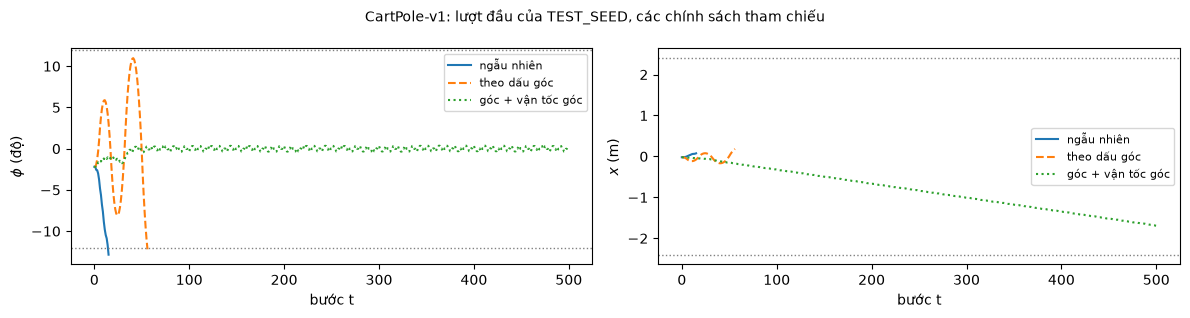

Trình phát: 3 lượt, HTML nhúng 22 kB


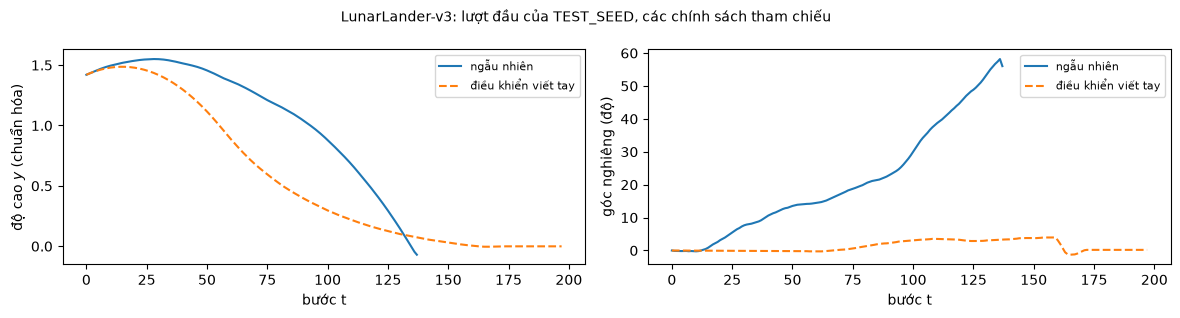

Trình phát: 2 lượt, HTML nhúng 20 kB


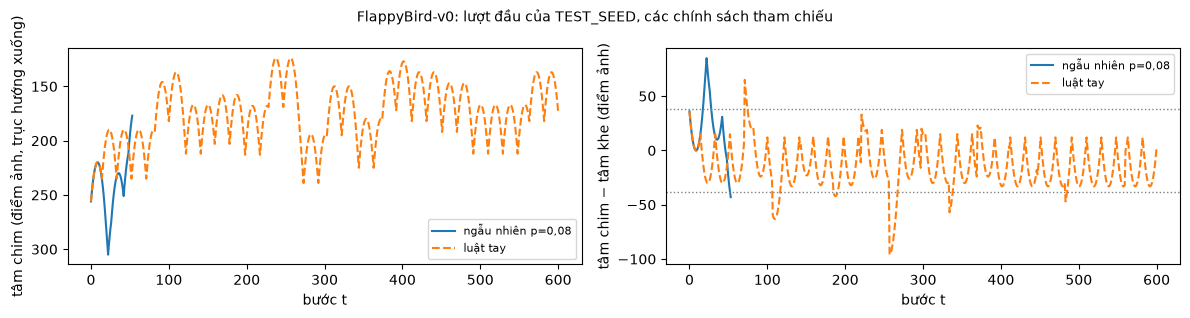

Trình phát: 2 lượt, HTML nhúng 49 kB; vẽ mỗi 2 bước để hiển thị trọn lượt dài 1365 bước


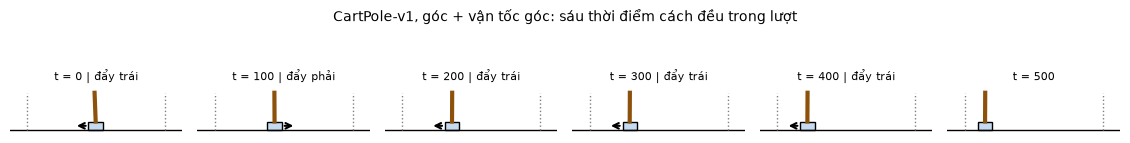

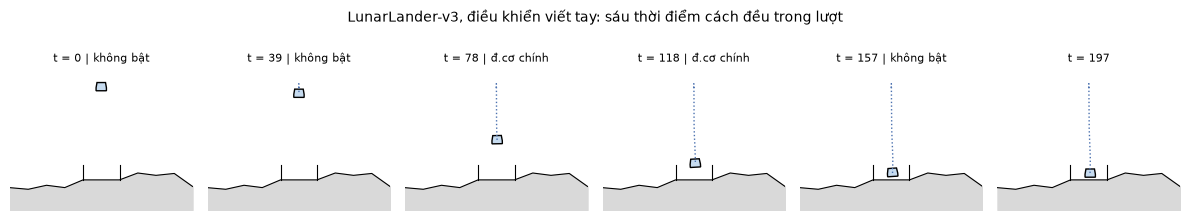

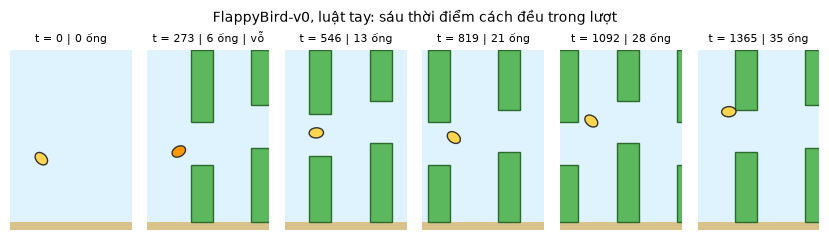

In [10]:
episodes_ref = {}
for env_id, pols in REF_POLICIES.items():
    episodes_ref[env_id] = {name: record_episode(envs[env_id], p, TEST_SEED, KIND[env_id]) for name, p in pols.items()}
    for name, ep in episodes_ref[env_id].items():
        assert len(ep["actions"]) == results_ref[env_id][name]["length"][0]   # trùng lượt đầu của phép đánh giá
        print(f"{env_id:<15} {name:<20} {len(ep['actions']):5d} bước, {end_reason(ep)}")

for env_id in ENV_IDS:
    plot_episodes(episodes_ref[env_id], f"{env_id}: lượt đầu của TEST_SEED, các chính sách tham chiếu")
    display(player(episodes_ref[env_id]))
best_ref = {"CartPole-v1": "góc + vận tốc góc", "LunarLander-v3": "điều khiển viết tay", "FlappyBird-v0": "luật tay"}
for env_id, name in best_ref.items():
    filmstrip(episodes_ref[env_id][name], 6, f"{env_id}, {name}: sáu thời điểm cách đều trong lượt"); plt.show()

Đến đây có thước đo, bảy mốc so sánh và ba cách xem một lượt. Còn thiếu chính sách học được: mục 4–6 dựng từng phần của Thuật toán 08.13, bắt đầu từ mạng giá trị hành động và bộ nhớ phát lại.

## 4. Mạng giá trị hành động và bộ nhớ phát lại

**Mạng giá trị hành động** (Định nghĩa 08.1). Một lần tính của mạng trả cả vector $\mathbf q_\theta(o)=\bigl(Q_\theta(o,a)\bigr)_{a\in\mathcal A}\in\mathbb R^{\lvert\mathcal A\rvert}$, nên phép $\max_a$ trong mục tiêu và phép chọn hành động tham lam không cần chạy mạng $\lvert\mathcal A\rvert$ lần. Ba môi trường có quan sát là vector ngắn, nên notebook dùng mạng nhiều tầng (multilayer perceptron, MLP) thay cho mạng tích chập của Atari:

$$\mathbf q_\theta(o)=W_3\,\sigma\bigl(W_2\,\sigma(W_1o+c_1)+c_2\bigr)+c_3,\qquad \sigma(z)=\max(z,0),$$

với $W_1$ cỡ $(h,n)$, $W_2$ cỡ $(h,h)$, $W_3$ cỡ $(\lvert\mathcal A\rvert,h)$; $\theta$ gồm mọi ma trận $W_\ell$ và vector $c_\ell$. Mục 7–9 dùng $h=64$ cho CartPole và $h=128$ cho hai môi trường còn lại. Mạng mục tiêu có cùng kiến trúc và nhận bản sao $\theta^-\leftarrow\theta$ lúc khởi tạo.

**Bộ nhớ phát lại** (Định nghĩa 08.7) là bộ đệm vòng dung lượng $N$ chứa mẫu chuyển sáu thành phần $(O,A,R,O',Z,U)$. Lớp `Replay` lưu sáu mảng NumPy cấp sẵn; `k` là vị trí ghi kế tiếp, `size` $=\lvert\mathcal D\rvert=\min(\text{số lần ghi},N)$. Khi đầy, mẫu mới ghi đè mẫu cũ nhất. `sample` rút đều $b$ chỉ số có hoàn lại, một trong hai cách rút mà ghi chú cho phép (mục "Bộ nhớ phát lại"). `last` trả $b$ mẫu vừa ghi theo thứ tự thời gian, chỉ dùng cho nhánh bỏ bộ nhớ phát lại ở mục 11. Cờ $U$ được lưu nhưng không đi vào mục tiêu; lưu nó giúp kiểm tra và đếm số mẫu bị cắt ngắn.

In [11]:
class QNet(nn.Module):
    # q_theta: R^n -> R^|A|, hai tầng ẩn ReLU
    def __init__(self, n_obs, n_act, hidden=(128, 128)):
        super().__init__()
        layers, d = [], n_obs
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, n_act))
        self.net = nn.Sequential(*layers)

    def forward(self, o):                              # o: (b, n) float32 -> (b, |A|)
        return self.net(o)


class Replay:
    # Bộ nhớ phát lại D: bộ đệm vòng dung lượng N, sáu mảng cho (O, A, R, O', Z, U)
    def __init__(self, N, n_obs):
        self.N, self.k, self.size = N, 0, 0
        self.O = np.zeros((N, n_obs), np.float32)
        self.A = np.zeros(N, np.int64)
        self.R = np.zeros(N, np.float32)
        self.O2 = np.zeros((N, n_obs), np.float32)
        self.Z = np.zeros(N, np.float32)               # cờ kết thúc của MDP
        self.U = np.zeros(N, np.float32)               # cờ cắt ngắn: lưu để kiểm tra, không dùng trong mục tiêu

    def add(self, o, a, r, o2, z, u):
        i = self.k
        self.O[i], self.A[i], self.R[i], self.O2[i], self.Z[i], self.U[i] = o, a, r, o2, z, u
        self.k = (self.k + 1) % self.N                 # ghi đè mẫu cũ nhất khi đầy
        self.size = min(self.size + 1, self.N)

    def sample(self, b, rng):
        return self.batch(rng.integers(0, self.size, size=b))      # rút đều, có hoàn lại

    def last(self, b):                                 # b mẫu vừa ghi, theo thứ tự thời gian
        return self.batch(((self.k - 1 - np.arange(b)) % self.N)[::-1].copy())

    def batch(self, idx):
        f = torch.from_numpy
        return (f(self.O[idx]), f(self.A[idx]), f(self.R[idx]), f(self.O2[idx]), f(self.Z[idx]), f(self.U[idx]))


# Kiểm tra bộ đệm vòng (Ví dụ 08.10: dung lượng 6) và kích thước của một mini-batch (Nhận xét 08.14)
D_test = Replay(6, 4)
for k in range(1, 9):                                  # mẫu 1..8 ghi vào bộ nhớ dung lượng 6; O = (k, k, k, k)
    D_test.add(np.full(4, k), k % 2, 1.0, np.full(4, k + 1), 0.0, 0.0)
print("|D| =", D_test.size, "| mẫu ở các vị trí 1..6:", D_test.O[:, 0].astype(int), "| con trỏ ghi ở vị trí", D_test.k + 1)
assert D_test.size == 6 and D_test.O[:, 0].astype(int).tolist() == [7, 8, 3, 4, 5, 6]   # như Ví dụ 08.10
assert D_test.k + 1 == 3                               # con trỏ ghi ở ô chứa mẫu 3, mẫu cũ nhất
O, A, R, O2, Z, U = D_test.sample(4, np.random.default_rng(0))
print("kích thước mini-batch b = 4:", tuple(O.shape), tuple(A.shape), tuple(R.shape), tuple(O2.shape),
      tuple(Z.shape), "| kiểu:", O.dtype, A.dtype, Z.dtype)
assert O.shape == (4, 4) and A.shape == (4,) and A.dtype == torch.int64 and Z.dtype == torch.float32
assert D_test.last(3)[0][:, 0].tolist() == [6.0, 7.0, 8.0]  # ba mẫu gần nhất theo thứ tự thời gian
q_test = QNet(4, 2, (64, 64))
print("q_theta(O) cỡ", tuple(q_test(O).shape), "| số tham số d =", sum(p.numel() for p in q_test.parameters()))

|D| = 6 | mẫu ở các vị trí 1..6: [7 8 3 4 5 6] | con trỏ ghi ở vị trí 3
kích thước mini-batch b = 4: (4, 4) (4,) (4,) (4, 4) (4,) | kiểu: torch.float32 torch.int64 torch.float32
q_theta(O) cỡ (4, 2) | số tham số d = 4610


Với $n=4$, $h=64$, $\lvert\mathcal A\rvert=2$, số tham số là $d=(4\cdot64+64)+(64\cdot64+64)+(64\cdot2+2)=4\,610$, khớp với dòng in ở trên. Hành động $A$ có kiểu số nguyên `int64` vì nó là chỉ số của phép chọn theo hành động; cờ $Z$ đã được chuyển sang kiểu số thực khi lưu vào $\mathcal D$, trước khi tính $1-Z$ và nhân với phần bootstrap (Nhận xét 08.14).

Đến đây có mạng để tính $\mathbf q_\theta(O_i)$ và bộ nhớ để rút mini-batch. Còn thiếu phép biến một mini-batch thành một bước tham số; mục 5 viết mục tiêu, hàm mất mát và kiểm chúng bằng số liệu của ghi chú.

## 5. Mục tiêu hồi quy, hàm mất mát và một bước tính tay

**Vấn đề.** Bước 6–8 của Thuật toán 08.13 biến một mini-batch thành một bước tham số. Ba chi tiết quyết định bước đó có đúng hay không: mặt nạ chỉ dùng cờ kết thúc $Z$ (Định nghĩa 08.4, 08.6), dự đoán lấy giá trị của đúng hành động đã lưu (phép chọn theo hành động, Định nghĩa 08.12), và mục tiêu không nhận gradient (phép dừng gradient). Với mini-batch $B=\{(O_i,A_i,R_i,O'_i,Z_i,U_i)\}_{i=1}^b$,

$$q_i=[\mathbf q_\theta(O_i)]_{A_i},\qquad y_i=\operatorname{sg}\Bigl(R_i+\gamma(1-Z_i)\max_{a'}Q_{\theta^-}(O'_i,a')\Bigr),\qquad L_B(\theta)=\frac1b\sum_{i=1}^b(y_i-q_i)^2,$$

và $\nabla_\theta L_B=\tfrac2b\sum_i(q_i-y_i)\nabla_\theta q_i$ (Định nghĩa 08.10). Ánh xạ sang hàm `dqn_loss`: `q_net(O)` là mảng $M$ cỡ $(b,\lvert\mathcal A\rvert)$; `.gather(1, A.unsqueeze(1)).squeeze(1)` lấy $q_i=M_{i,A_i}$, cỡ $(b,)$; khối `torch.no_grad()` là $\operatorname{sg}$; `tgt_net(O2).max(dim=1).values` là $\max_{a'}Q_{\theta^-}(O'_i,a')$, cỡ $(b,)$; `(1.0 - Z)` là mặt nạ, và `U` không xuất hiện trong công thức. Tùy chọn `loss="huber"` thay bình phương bằng hàm Huber, một lựa chọn khác mà ghi chú nêu ở mục "Hàm mất mát trên mini-batch"; mục 7–9 dùng bình phương.

In [12]:
def dqn_loss(q_net, tgt_net, batch, gamma, loss="mse"):
    O, A, R, O2, Z, U = batch                                         # (b,n) (b,) (b,) (b,n) (b,) (b,)
    q = q_net(O).gather(1, A.unsqueeze(1)).squeeze(1)                 # bước 6: q_i = [q_theta(O_i)]_{A_i}, (b,)
    with torch.no_grad():                                             # bước 7: sg(.), mục tiêu không nhận gradient
        y = R + gamma * (1.0 - Z) * tgt_net(O2).max(dim=1).values     # mặt nạ 1 - Z; cờ cắt ngắn U không dùng
    if loss == "mse":
        L = ((y - q) ** 2).mean()                                     # L_B = (1/b) sum_i (y_i - q_i)^2
    else:
        L = nn.functional.smooth_l1_loss(q, y)                        # Huber (biến thể)
    return L, q.detach(), y

**Ví dụ tính tay.** Số liệu lấy từ ghi chú: mẫu 1 là mẫu chuyển bị cắt ngắn của Ví dụ 08.8, mẫu 2 là mẫu chuyển kết thúc của Ví dụ 08.7, cùng mini-batch của Bài tập 08.1; mảng $M$ của mạng trực tuyến lấy từ Ví dụ 08.13. Với $\gamma=0{,}9$, $b=2$, $\lvert\mathcal A\rvert=3$:

| $i$ | $R_i$ | $Z_i$ | $U_i$ | $\max_{a'}Q_{\theta^-}(O'_i,a')$ | $\mathbf q_\theta(O_i)$ | $A_i$ |
|---|---|---|---|---|---|---|
| 1 | $1$ | $0$ | $1$ | $4$ | $(1{,}0;\ 3{,}1;\ 0{,}2)$ | $a_2$ |
| 2 | $-2$ | $1$ | $0$ | $100$ | $(-1{,}5;\ 0{,}4;\ 2{,}0)$ | $a_1$ |

- Phép chọn: $q_1=3{,}1$, $q_2=-1{,}5$.
- Mục tiêu: $y_1=1+0{,}9\cdot(1-0)\cdot4=4{,}6$; $y_2=-2+0{,}9\cdot(1-1)\cdot100=-2$.
- Sai số: $\delta_1=1{,}5$, $\delta_2=-0{,}5$; hàm mất mát $L_B=\tfrac12(1{,}5^2+0{,}5^2)=1{,}25$.
- Gradient theo $M$: ô $(1,2)$ nhận $q_1-y_1=-1{,}5$, ô $(2,1)$ nhận $q_2-y_2=0{,}5$, mọi ô khác nhận $0$ (với $b=2$, $\tfrac2b=1$).

Để mạng trả đúng các số này, ô mã dùng hai tầng tuyến tính không hệ số tự do và quan sát one-hot: $O_1=O'_1=(1,0)$, $O_2=O'_2=(0,1)$, nên $\mathbf q_\theta(O_i)$ là cột $i$ của ma trận trọng số $W=M^\top$. Mạng mục tiêu có cột $(4;1;0)$ và $(100;0;-1)$, nên giá trị lớn nhất tại $O'_1$, $O'_2$ là $4$ và $100$. Gradient theo $W$ là chuyển vị của gradient theo $M$.

Ô mã cũng tính lại mục tiêu với hai lỗi cài đặt mà ghi chú nêu: dùng mặt nạ $1-(Z\lor U)$, khi đó $y_1$ hạ từ $4{,}6$ xuống $1$ (Ví dụ 08.8); dùng $\max_aQ_\theta(O_i,a)$ thay cho phép chọn theo $A_i$, khi đó $q_2=2{,}0$ là giá trị của $a_3$, một hành động không được thực hiện (Ví dụ 08.13).

In [13]:
M = torch.tensor([[1.0, 3.1, 0.2], [-1.5, 0.4, 2.0]])               # q_theta(O_i) theo hàng, Ví dụ 08.13
q_lin = nn.Linear(2, 3, bias=False); t_lin = nn.Linear(2, 3, bias=False)
with torch.no_grad():
    q_lin.weight.copy_(M.T)                                          # W = M^T: q_theta(e_i) = cột i của W
    t_lin.weight.copy_(torch.tensor([[4.0, 100.0], [1.0, 0.0], [0.0, -1.0]]))   # max tại O'_1, O'_2: 4 và 100
O = torch.eye(2); A = torch.tensor([1, 0])                           # A_1 = a_2, A_2 = a_1 (chỉ số từ 0)
R = torch.tensor([1.0, -2.0]); Z = torch.tensor([0.0, 1.0]); U = torch.tensor([1.0, 0.0])
batch = (O, A, R, O, Z, U)

L, q, y = dqn_loss(q_lin, t_lin, batch, gamma=0.9)
L.backward()
grad_M = q_lin.weight.grad.T                                         # gradient theo M, cỡ (b, |A|) = (2, 3)
print("q =", q.numpy(), "| y =", y.numpy(), "| delta =", (y - q).numpy(), "| L_B =", round(L.item(), 4))
print("dL/dM =\n", grad_M.numpy())
assert torch.allclose(q, torch.tensor([3.1, -1.5])) and torch.allclose(y, torch.tensor([4.6, -2.0]))
assert abs(L.item() - 1.25) < 1e-6
assert torch.allclose(grad_M, torch.tensor([[0.0, -1.5, 0.0], [0.5, 0.0, 0.0]]))   # chỉ ô (i, A_i) nhận gradient
assert t_lin.weight.grad is None                                     # mạng mục tiêu không nhận gradient

# Lỗi 1: mặt nạ gộp hai cờ, 1 - (Z or U)
with torch.no_grad():
    y_bug = R + 0.9 * (1.0 - torch.maximum(Z, U)) * t_lin(O).max(dim=1).values
# Lỗi 2: phép cực đại của mạng trực tuyến thay cho phép chọn theo A_i
q_bug = q_lin(O).max(dim=1).values.detach()
print("lỗi 1, mục tiêu với mặt nạ 1-(Z or U):", y_bug.numpy(), "| lỗi 2, dự đoán bằng max:", q_bug.numpy())
assert torch.allclose(y_bug, torch.tensor([1.0, -2.0])) and torch.allclose(q_bug, torch.tensor([3.1, 2.0]))

q = [ 3.1 -1.5] | y = [ 4.6 -2. ] | delta = [ 1.5 -0.5] | L_B = 1.25
dL/dM =
 [[ 0.  -1.5  0. ]
 [ 0.5  0.   0. ]]
lỗi 1, mục tiêu với mặt nạ 1-(Z or U): [ 1. -2.] | lỗi 2, dự đoán bằng max: [3.1 2. ]


**Đọc kết quả.** Mẫu 1 bị cắt ngắn nhưng MDP chưa kết thúc, nên phần bootstrap $0{,}9\cdot4=3{,}6$ vẫn nằm trong $y_1$. Mặt nạ gộp hai cờ xóa phần này và dạy mạng rằng quan sát ở bước giới hạn có giá trị thấp. Mẫu 2 kết thúc thật, nên giá trị $100$ mà mạng mục tiêu trả tại quan sát cuối lượt không vào mục tiêu. Với phép cực đại thay cho phép chọn, dự đoán của mẫu 2 thành $2{,}0$, giá trị của $a_3$, và sai số đổi từ $-0{,}5$ thành $-4$: cập nhật kéo giá trị của $a_3$ về mục tiêu sinh từ hành động $a_1$.

**Câu hỏi:** Xét $q_1$, $q_2$ như hai biến riêng. Sau một bước hạ gradient nhỏ, $q_1$ và $q_2$ thay đổi theo hướng nào? Khi cả hai cùng phụ thuộc $\theta$, điều kiện nào làm $q_1$ giảm?

<details><summary>Lời giải</summary>

$\partial L_B/\partial q_1=-1{,}5<0$ nên bước $-\eta\nabla L_B$ tăng $q_1$ về $4{,}6$; $\partial L_B/\partial q_2=0{,}5>0$ nên $q_2$ giảm về $-2$. Khi $q_1$, $q_2$ cùng phụ thuộc $\theta$, bước $\Delta\theta=\eta(1{,}5\,\nabla_\theta q_1-0{,}5\,\nabla_\theta q_2)$ cho $\Delta q_1\approx\eta\bigl(1{,}5\lVert\nabla_\theta q_1\rVert^2-0{,}5\,\nabla_\theta q_1^\top\nabla_\theta q_2\bigr)$, nên $q_1$ giảm khi $\nabla_\theta q_1^\top\nabla_\theta q_2>3\lVert\nabla_\theta q_1\rVert^2$ (lời giải Bài tập 08.1).
</details>

## 6. Vòng huấn luyện của Thuật toán 08.13

**Vấn đề.** Một bước tối ưu cần dữ liệu trong $\mathcal D$, còn dữ liệu chỉ sinh ra khi tác tử tương tác với môi trường. Hàm `train_dqn` ghép hai việc theo đúng thứ tự của Thuật toán 08.13, với hai bộ đếm riêng: `t` đếm bước môi trường, `k_opt` đếm bước tối ưu.

| Bước | Thuật toán 08.13 | Mã trong `train_dqn` |
|---|---|---|
| khởi tạo | $\mathcal D\leftarrow\varnothing$, $\theta$ ngẫu nhiên, $\theta^-\leftarrow\theta$, $t=k_{\mathrm{opt}}=0$ | `Replay(N, n)`, `QNet(...)`, `tgt_net.load_state_dict(q_net.state_dict())` |
| 1 | $A_t$ theo $\epsilon_{\mathrm{exp}}$-tham lam từ $Q_\theta(O_t,\cdot)$ | `rng.random() < eps`: chọn đều; ngược lại `greedy_action` |
| 2–3 | thực hiện $A_t$, lưu $(O_t,A_t,R_{t+1},O_{t+1},Z_{t+1},U_{t+1})$ | `env.step(a)`, `D.add(o, a, r, o2, term, trunc)` |
| 4 | đặt lại khi $Z\lor U$; $t\leftarrow t+1$ | `if term or trunc: env.reset(...)`; `t += 1` |
| điều kiện | $\lvert\mathcal D\rvert\ge N_{\mathrm{start}}$ và $t\bmod F=0$ | `D.size >= N_start and t % F == 0` |
| 5–7 | rút $b$ mẫu, tính $q_i$, $y_i$ | `D.sample(b, rng)`, `dqn_loss` |
| 8 | bộ tối ưu cập nhật $\theta$; $k_{\mathrm{opt}}\leftarrow k_{\mathrm{opt}}+1$ | `opt.zero_grad(); L.backward(); opt.step()`; `k_opt += 1` |
| 9 | nếu $k_{\mathrm{opt}}\bmod C=0$: $\theta^-\leftarrow\theta$ | `if k_opt % C == 0: tgt_net.load_state_dict(...)` |

**Lịch thăm dò.** $\epsilon_{\mathrm{exp}}$ giảm tuyến tính từ $\epsilon_{\text{đầu}}$ xuống $\epsilon_{\text{cuối}}$ trong $\rho T$ bước môi trường đầu rồi giữ nguyên, với $\rho\in(0,1]$ là phần của ngân sách $T$ dành cho giai đoạn giảm; lịch của Mnih và cộng sự (2015) trong bảng siêu tham số của ghi chú có cùng dạng. Xác suất thăm dò tại bước $t$ là hàm của $t$, nên hành vi chỉ phụ thuộc lịch sử tới bước $t$, đúng điều kiện về hành vi của Mệnh đề 08.8; hai giả thiết còn lại của mệnh đề, quan sát đủ Markov và động lực không đổi, phụ thuộc môi trường (bảng ở mục 2).

**Bộ tối ưu.** Bước 8 dùng Adam (Định nghĩa 08.18) với tốc độ học $\eta$. `torch.optim.Adam(..., fused=True)` là bản gộp các phép tính theo tọa độ của cùng quy tắc, nhanh hơn trên CPU; nếu phiên bản PyTorch chưa hỗ trợ, hàm `make_optimizer` dùng bản thường.

**Ghi nhật ký.** Ngoài tham số, hàm ghi: lợi tức, độ dài và số ống của mỗi lượt huấn luyện kèm bước $t$ lúc lượt kết thúc; trung bình $L_B$ và trung bình $q_i$ trên các mini-batch của mỗi $1000$ bước môi trường; $10$ mốc kiểm định cách đều theo $t$, mỗi mốc chạy chính sách tham lam hiện hành trên $10$ lượt `VALID_SEED`. Với `keep_best=True`, hàm giữ thêm bản sao của mạng tại mốc kiểm định có tổng thưởng trung bình cao nhất (mục 9 giải thích cách dùng). Với `trace=True`, hàm ghi $(t,\lvert\mathcal D\rvert,k_{\mathrm{opt}},\text{có đồng bộ})$ sau mỗi bước tối ưu.

In [14]:
def linear_eps(t, T, eps_start, eps_end, frac):
    # epsilon_exp giảm tuyến tính từ eps_start xuống eps_end trong frac * T bước đầu, rồi giữ eps_end
    return max(eps_end, eps_start - (eps_start - eps_end) * t / max(1, frac * T))


def greedy_action(q_net, o):
    with torch.no_grad():
        qv = q_net(torch.as_tensor(o, dtype=torch.float32).unsqueeze(0))[0]   # q_theta(o), cỡ (|A|,)
    return int(torch.argmax(qv))


def net_policy(q_net):
    return lambda o, rng: greedy_action(q_net, o)          # chính sách tham lam theo Q_theta


def make_optimizer(params, cfg):
    try:                                                   # Adam bản gộp; cùng quy tắc cập nhật, nhanh hơn trên CPU
        return torch.optim.Adam(params, lr=cfg["lr"], fused=True)
    except (RuntimeError, TypeError):
        return torch.optim.Adam(params, lr=cfg["lr"])

In [15]:
def train_dqn(env_id, cfg, agent_seed=AGENT_SEED, train_seed=TRAIN_SEED, n_ckpt=10, keep_best=False):
    torch.manual_seed(agent_seed)
    rng = np.random.default_rng(agent_seed)                 # thăm dò và rút mini-batch
    env, env_valid = make_env(env_id), make_env(env_id)
    n_obs, n_act = env.observation_space.shape[0], env.action_space.n
    q_net, tgt_net = QNet(n_obs, n_act, cfg["hidden"]), QNet(n_obs, n_act, cfg["hidden"])
    tgt_net.load_state_dict(q_net.state_dict())             # theta^- <- theta
    opt = make_optimizer(q_net.parameters(), cfg)
    D = Replay(cfg["N"], n_obs)
    T, b, F, C, N_start, gamma = cfg["T"], cfg["b"], cfg["F"], cfg["C"], cfg["N_start"], cfg["gamma"]
    ep = 0
    o, _ = env.reset(seed=train_seed + ep)                  # O_0
    t, k_opt, n_sync, ep_ret, ep_len = 0, 0, 0, 0.0, 0
    log = dict(ep_t=[], ep_ret=[], ep_len=[], ep_score=[], loss_t=[], loss=[], qmean=[],
               ckpt_t=[], ckpt_mean=[], ckpt_se=[], ckpt_score=[], ckpt_score_se=[], trace=[])
    acc = [0.0, 0.0, 0]                                     # tổng L_B, tổng trung bình q_i, số bước tối ưu trong 1000 bước
    ckpts = {int(round(T * (j + 1) / n_ckpt)) for j in range(n_ckpt)} if n_ckpt else set()
    best_mean, best_net, t0 = -np.inf, None, time.time()
    while t < T:
        eps = linear_eps(t, T, cfg["eps_start"], cfg["eps_end"], cfg["eps_frac"])
        a = int(rng.integers(n_act)) if rng.random() < eps else greedy_action(q_net, o)   # bước 1
        o2, r, term, trunc, info = env.step(a)              # bước 2
        D.add(o, a, r, o2, float(term), float(trunc))       # bước 3: o2 là quan sát cuối, lấy trước khi đặt lại
        ep_ret += r; ep_len += 1
        if term or trunc:                                   # bước 4: đặt lại khi Z or U
            log["ep_t"].append(t + 1); log["ep_ret"].append(ep_ret); log["ep_len"].append(ep_len)
            log["ep_score"].append(info.get("score", np.nan))
            ep += 1; ep_ret, ep_len = 0.0, 0
            o, _ = env.reset(seed=train_seed + ep)
        else:
            o = o2
        t += 1
        if D.size >= N_start and t % F == 0:                # điều kiện của bước 5-9
            batch = D.sample(b, rng) if cfg.get("replay", True) else D.last(b)        # bước 5
            L, q, _ = dqn_loss(q_net, tgt_net, batch, gamma, cfg.get("loss", "mse"))  # bước 6-7
            opt.zero_grad(); L.backward(); opt.step()       # bước 8: cập nhật theta ...
            k_opt += 1                                      # ... rồi mới tăng k_opt
            synced = (k_opt % C == 0)
            if synced:                                      # bước 9: theta^- <- theta
                tgt_net.load_state_dict(q_net.state_dict()); n_sync += 1
            if cfg.get("trace"):
                log["trace"].append((t, D.size, k_opt, synced))
            acc[0] += float(L.detach()); acc[1] += float(q.mean()); acc[2] += 1
        if t % 1000 == 0 and acc[2]:
            log["loss_t"].append(t); log["loss"].append(acc[0] / acc[2]); log["qmean"].append(acc[1] / acc[2])
            acc = [0.0, 0.0, 0]
        if t in ckpts:                                      # mốc kiểm định: chính sách tham lam, 10 lượt VALID_SEED
            res = evaluate_policy(env_valid, net_policy(q_net), N_VALID, VALID_SEED, gamma)
            log["ckpt_t"].append(t); log["ckpt_mean"].append(res["total"].mean())
            log["ckpt_se"].append(res["total"].std(ddof=1) / np.sqrt(N_VALID))
            log["ckpt_score"].append(res["score"].mean())          # chỉ có nghĩa với Flappy Bird
            log["ckpt_score_se"].append(res["score"].std(ddof=1) / np.sqrt(N_VALID))
            if keep_best and res["total"].mean() > best_mean:
                best_mean, best_net = res["total"].mean(), copy.deepcopy(q_net)
                log["best_t"] = t
    log.update(k_opt=k_opt, n_sync=n_sync, n_episodes=ep, train_secs=time.time() - t0)
    log = {k: (np.array(v) if isinstance(v, list) and k != "trace" else v) for k, v in log.items()}
    return (q_net, log, best_net) if keep_best else (q_net, log)

**Kiểm tra hai bộ đếm** bằng Ví dụ 08.15: $N=6$, $b=2$, $N_{\mathrm{start}}=3$, $F=2$, $C=2$, $T=10$. Theo ghi chú, bước tối ưu chạy tại $t=4,6,8,10$ với $\lvert\mathcal D\rvert=4,6,6,6$, $k_{\mathrm{opt}}=1,2,3,4$, và đồng bộ xảy ra sau bước tối ưu thứ hai và thứ tư. Ô mã chạy `train_dqn` trên CartPole với đúng các tham số này ($\epsilon_{\mathrm{exp}}=1$, mạng một tầng ẩn $8$ nút) và so nhật ký `trace` với bảng của ví dụ.

In [16]:
BASE_CFG = dict(gamma=GAMMA, loss="mse", replay=True)
cfg_trace = dict(BASE_CFG, lr=1e-3, T=10, N=6, b=2, N_start=3, F=2, C=2, eps_start=1.0, eps_end=1.0, eps_frac=1.0,
                 hidden=(8,), trace=True)
_, log_trace = train_dqn("CartPole-v1", cfg_trace, n_ckpt=0)
print(" t  |D|  k_opt  đồng bộ")
for row in log_trace["trace"]:
    print(f"{row[0]:2d}  {row[1]:3d}  {row[2]:5d}  {'có' if row[3] else 'không'}")
assert log_trace["trace"] == [(4, 4, 1, False), (6, 6, 2, True), (8, 6, 3, False), (10, 6, 4, True)]   # Ví dụ 08.15

 t  |D|  k_opt  đồng bộ
 4    4      1  không
 6    6      2  có
 8    6      3  không
10    6      4  có


Đến đây Thuật toán 08.13 đã chạy đúng lịch trên một ví dụ mười bước. Còn thiếu các giá trị đầu vào cho từng môi trường và kết quả của chính sách học được; mục 7–9 chọn cấu hình, huấn luyện và đánh giá trên ba môi trường.

## 7. DQN trên CartPole

**Cấu hình.** Bảng dưới ghi đầu vào của Thuật toán 08.13 cho cả ba môi trường. Cấu hình được chọn từ các thử nghiệm sơ bộ ở mục 10; mục đó công bố mọi cấu hình đã thử.

| Ký hiệu | Ý nghĩa | CartPole | Lunar Lander | Flappy Bird |
|---|---|---|---|---|
| $T$ | ngân sách bước môi trường | $50\,000$ | $100\,000$ | $300\,000$ ($500\,000$ khi `LONG_BUDGET`) |
| $N$ | dung lượng của $\mathcal D$ | $50\,000$ | $50\,000$ | $100\,000$ |
| $b$ | cỡ mini-batch | $64$ | $128$ | $64$ |
| $N_{\mathrm{start}}$ | số mẫu trước bước tối ưu đầu | $1000$ | $1000$ | $1000$ |
| $F$ | số bước môi trường giữa hai bước tối ưu | $1$ | $1$ | $4$ |
| $C$ | số bước tối ưu giữa hai lần đồng bộ | $200$ | $250$ | $250$ |
| $\eta$ | tốc độ học của Adam | $10^{-3}$ | $6{,}3\cdot10^{-4}$ | $5\cdot10^{-4}$ |
| $\epsilon_{\mathrm{exp}}$ | lịch thăm dò: đầu → cuối, trong phần $\rho$ của $T$ | $1\to0{,}05$, $\rho=0{,}2$ | $1\to0{,}1$, $\rho=0{,}12$ | $0{,}1\to0{,}001$, $\rho=0{,}1$ |
| $h$ | số nút mỗi tầng ẩn (hai tầng) | $64$ | $128$ | $128$ |
| $\gamma$ | hệ số chiết khấu | $0{,}99$ | $0{,}99$ | $0{,}99$ |

Mỗi bước tối ưu rút $b$ mẫu, nên trên toàn bộ lần huấn luyện, một mẫu chuyển được rút trung bình $b\cdot k_{\mathrm{opt}}/T$ lần: khoảng $63$ lần với CartPole ($64\cdot49\,001/50\,000$), $127$ lần với Lunar Lander và $16$ lần với Flappy Bird. Con số $b/F$ của Ví dụ 08.14 là trung bình khi bộ nhớ đã đầy; với CartPole, $N=T$ nên bộ nhớ không bao giờ đầy. Mẫu thu sớm được rút nhiều hơn mẫu thu muộn, vì chúng ở trong $\mathcal D$ lâu hơn và lúc đầu $\mathcal D$ còn nhỏ.

Cấu hình Lunar Lander xuất phát từ mục `LunarLander-v3` trong tệp `hyperparams/dqn.yml` của thư viện RL Baselines3 Zoo: $10^5$ bước môi trường, tốc độ học $6{,}3\cdot10^{-4}$, $b=128$, $N=50\,000$, $\gamma=0{,}99$, thăm dò giảm về $0{,}1$ trong $12\%$ đầu, hai tầng ẩn $256$ nút, cập nhật sau mỗi $4$ bước môi trường với số bước gradient bằng số bước vừa thu, mạng mục tiêu cập nhật sau mỗi $250$ bước môi trường. Thư viện Stable-Baselines3 chạy cấu hình đó với DQN của nó, và mã nguồn `stable_baselines3/dqn/dqn.py` (phiên bản 2.9.0) dùng hàm mất mát Huber (`F.smooth_l1_loss`) cùng phép cắt chuẩn gradient với ngưỡng mặc định `max_grad_norm = 10`. Cấu hình ở đây khác ở các điểm sau: hàm mất mát bình phương của Định nghĩa 08.10, không cắt gradient, hai tầng ẩn $128$ nút (cho kết quả tốt hơn và nhanh hơn trong thử nghiệm sơ bộ), $N_{\mathrm{start}}=1000$, một bước tối ưu sau mỗi bước môi trường ($F=1$) và chu kỳ $C=250$ đếm theo bước tối ưu.

Hai hàm dưới dùng chung cho mục 7–9. `plot_learning` vẽ hai hình. Hình trái có lợi tức của từng lượt huấn luyện, trung bình trượt $20$ lượt, theo bước $t$ lúc lượt kết thúc; lượt này do hành vi $\epsilon_{\mathrm{exp}}$-tham lam sinh. Cùng hình có tổng thưởng trung bình của chính sách tham lam ở $10$ mốc kiểm định, thanh sai số $\pm1{,}96\,\mathrm{SE}$. Hình phải có trung bình $q_i$ trên các mini-batch và $L_B$ theo $t$. `final_report` đánh giá chính sách học được trên $100$ lượt `TEST_SEED`, in cùng các chính sách tham chiếu và so sánh ghép cặp với từng chính sách.

In [17]:
CFG = {
    "CartPole-v1": dict(BASE_CFG, T=50_000, N=50_000, b=64, N_start=1000, F=1, C=200, lr=1e-3,
                        eps_start=1.0, eps_end=0.05, eps_frac=0.2, hidden=(64, 64)),
    "LunarLander-v3": dict(BASE_CFG, T=100_000, N=50_000, b=128, N_start=1000, F=1, C=250, lr=6.3e-4,
                           eps_start=1.0, eps_end=0.1, eps_frac=0.12, hidden=(128, 128)),
    "FlappyBird-v0": dict(BASE_CFG, T=500_000 if LONG_BUDGET else 300_000, N=100_000, b=64, N_start=1000, F=4,
                          C=250, lr=5e-4, eps_start=0.1, eps_end=0.001, eps_frac=0.1, hidden=(128, 128)),
}


def smooth(x, w=20):
    x = np.asarray(x, float)
    return np.convolve(x, np.ones(w) / w, mode="valid") if len(x) >= w else x


def plot_learning(log, title, bound=None, flappy=False):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    key = "ep_score" if flappy else "ep_ret"
    v = smooth(log[key]); t = log["ep_t"][len(log["ep_t"]) - len(v):]
    axes[0].plot(t, v, lw=1, alpha=0.7, label="lượt huấn luyện (ε-tham lam), trung bình trượt 20 lượt")
    ck = np.array(log["ckpt_score"] if flappy else log["ckpt_mean"])
    se = np.array(log["ckpt_score_se"] if flappy else log["ckpt_se"])
    axes[0].errorbar(log["ckpt_t"], ck, yerr=1.96 * se, fmt="s--", ms=4, capsize=3,
                     label="chính sách tham lam, 10 lượt VALID_SEED (±1,96 SE)")
    axes[0].set_ylabel("số ống của lượt" if flappy else "tổng thưởng của lượt"); axes[0].legend(fontsize=8)
    axes[1].plot(log["loss_t"], log["qmean"], color="C0", label="trung bình $q_i$ trên mini-batch")
    if bound is not None:
        axes[1].axhline(bound, color="k", ls="--", lw=0.8, label=f"cận 1/(1−γ) = {bound:g}")
    axes[1].set_ylabel("trung bình $q_i$")
    ax2 = axes[1].twinx()                                    # L_B có thang riêng ở trục phải
    ax2.plot(log["loss_t"], log["loss"], color="C1", ls=":", label="$L_B$ trung bình (trục phải)")
    ax2.set_ylabel("$L_B$")
    h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    axes[1].legend(h1 + h2, l1 + l2, fontsize=8, loc="center right")
    for ax in axes:
        ax.set_xlabel("bước môi trường t")
    fig.suptitle(title, fontsize=10); fig.tight_layout(); plt.show()


def plot_q_vs_return(q_net, env_id, title, n_episodes=10):
    # So max_a Q_theta(O_t, a) dọc lượt tham lam với lợi tức chiết khấu thực tế từ bước t: G_t = sum_k gamma^k R_{t+k+1}
    gaps = []
    for i in range(n_episodes):
        ep = record_episode(envs[env_id], net_policy(q_net), TEST_SEED + i, KIND[env_id])
        with torch.no_grad():
            Q = q_net(torch.as_tensor(ep["states"][:-1], dtype=torch.float32)).max(dim=1).values.numpy()   # (L,)
        G = np.zeros(len(ep["rewards"])); acc = 0.0
        for t in range(len(G) - 1, -1, -1):                  # G_t = R_{t+1} + gamma * G_{t+1}
            acc = ep["rewards"][t] + GAMMA * acc; G[t] = acc
        half = len(G) // 2
        gaps.append((Q[:half] - G[:half]).mean())
        if i == 0:
            fig, ax = plt.subplots(figsize=(8, 3.2))
            ax.plot(Q, label=r"$\max_a Q_\theta(O_t,a)$"); ax.plot(G, ls="--", label="$G_t$ thực tế của lượt")
            ax.set_xlabel("bước t"); ax.set_ylabel("giá trị"); ax.legend(fontsize=8)
            ax.set_title(f"{title}: lượt đầu của TEST_SEED, {end_reason(ep)}", fontsize=10)
            fig.tight_layout(); plt.show()
            print(f"lượt đầu: max_a Q(O_0, a) = {Q[0]:.1f}, G_0 = {G[0]:.1f}")
    gaps = np.array(gaps)
    print(f"{n_episodes} lượt đầu của TEST_SEED: trung bình theo nửa đầu mỗi lượt của max_a Q - G_t = "
          f"{gaps.mean():.1f} ± {gaps.std(ddof=1) / np.sqrt(n_episodes):.1f} (SE)")


def final_report(env_id, learned):
    # learned: {tên: mạng}; đánh giá tham lam trên TEST_SEED, so với mọi chính sách tham chiếu
    flappy = env_id == "FlappyBird-v0"; key = "score" if flappy else "total"
    res = {name: evaluate_policy(envs[env_id], net_policy(net), N_TEST, TEST_SEED) for name, net in learned.items()}
    print(f"{env_id}: {N_TEST} lượt TEST_SEED, trung bình ± SE")
    for name, r in {**results_ref[env_id], **res}.items():
        summarize(name, r, flappy)
    for name, r in res.items():
        for ref, rr in results_ref[env_id].items():
            m, h = paired_difference(r, rr, key)
            print(f"  {name} - {ref}: {m:8.2f} ± {h:6.2f} (khoảng 95%, ghép cặp, {'số ống' if flappy else 'tổng thưởng'})")
    return res

Ô mã dưới huấn luyện DQN trên CartPole với hạt giống tác tử `AGENT_SEED` (khoảng một phút trên CPU hai luồng khi soạn) và in số bước tối ưu, số lần đồng bộ. Với $T=50\,000$, $N_{\mathrm{start}}=1000$, $F=1$, số bước tối ưu là $T-N_{\mathrm{start}}+1=49\,001$, và với $C=200$ có $\lfloor49\,001/200\rfloor=245$ lần đồng bộ.

60 giây | k_opt = 49001, số lần đồng bộ = 245, số lượt huấn luyện = 355


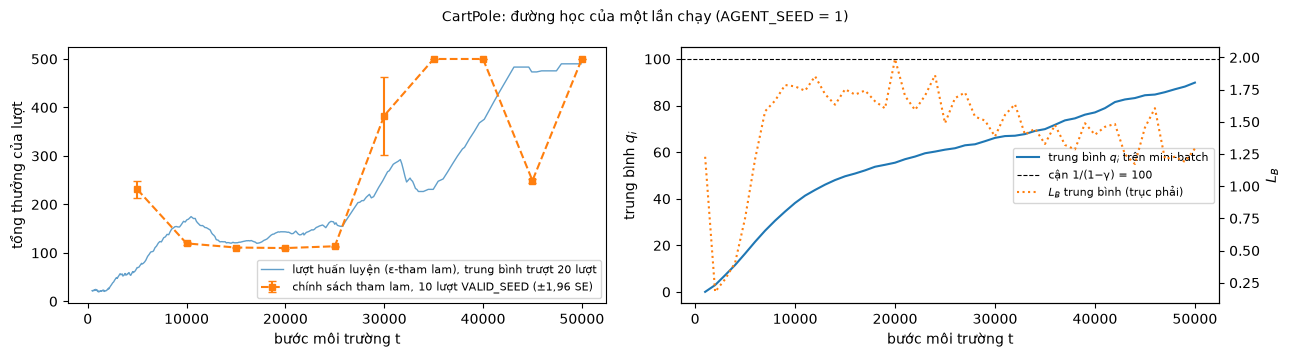

CartPole-v1: 100 lượt TEST_SEED, trung bình ± SE
ngẫu nhiên                 tổng thưởng    22.95 ±  1.16 (sd  11.62) | G_0   20.09 | dài     23 | cắt ngắn   0%
theo dấu góc               tổng thưởng    41.89 ±  0.82 (sd   8.20) | G_0   34.14 | dài     42 | cắt ngắn   0%
góc + vận tốc góc          tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
DQN                        tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
  DQN - ngẫu nhiên:   477.05 ±   2.28 (khoảng 95%, ghép cặp, tổng thưởng)
  DQN - theo dấu góc:   458.11 ±   1.61 (khoảng 95%, ghép cặp, tổng thưởng)
  DQN - góc + vận tốc góc:     0.00 ±   0.00 (khoảng 95%, ghép cặp, tổng thưởng)


In [18]:
env_id = "CartPole-v1"
q_cp, log_cp = train_dqn(env_id, CFG[env_id])
print(f"{log_cp['train_secs']:.0f} giây | k_opt = {log_cp['k_opt']}, số lần đồng bộ = {log_cp['n_sync']}, "
      f"số lượt huấn luyện = {log_cp['n_episodes']}")
assert log_cp["k_opt"] == CFG[env_id]["T"] - CFG[env_id]["N_start"] + 1 and log_cp["n_sync"] == log_cp["k_opt"] // CFG[env_id]["C"]
plot_learning(log_cp, "CartPole: đường học của một lần chạy (AGENT_SEED = 1)", bound=1 / (1 - GAMMA))
res_cp = final_report(env_id, {"DQN": q_cp})

**Đọc kết quả.** Phép kiểm `assert` chỉ dùng số bước tối ưu và số lần đồng bộ, hai đại lượng do $T$, $N_{\mathrm{start}}$, $F$, $C$ quyết định, không phụ thuộc phiên bản gói. Đường kiểm định thường không đơn điệu: chính sách tham lam có thể đạt $500$ ở một mốc rồi giảm ở mốc sau. Mục 10 vẽ đường kiểm định của sáu hạt giống cùng cấu hình: khi soạn, năm trong sáu hạt giống cho chính sách cuối đạt $500$ ở cả $100$ lượt `TEST_SEED`, hạt giống còn lại đạt $247{,}5$. Ở hình phải, đường nét đứt là cận $1/(1-\gamma)=100$: mỗi bước có phần thưởng $1$, nên giá trị đúng của mọi cặp không vượt cận này. Giá trị lớn nhất theo $t$ của trung bình $q_i$ ở sáu hạt giống khi soạn nằm trong khoảng $87{,}9$–$112{,}1$ (bảng `QMAX` ở mục 10), tức sát cận và có lúc vượt nhẹ.

CartPole không phân biệt được DQN với luật một dòng của mục 3. Lunar Lander ở mục 8 có mốc mạnh hơn nhiều: bộ điều khiển viết tay đạt $236{,}9$, với độ lệch chuẩn $100{,}7$ giữa các lượt và $4\%$ lượt lơ lửng tới khi bị cắt ngắn (mục 3), nên chưa có lý do để coi nó là chính sách tối ưu; một chính sách học được có thể vượt nó.

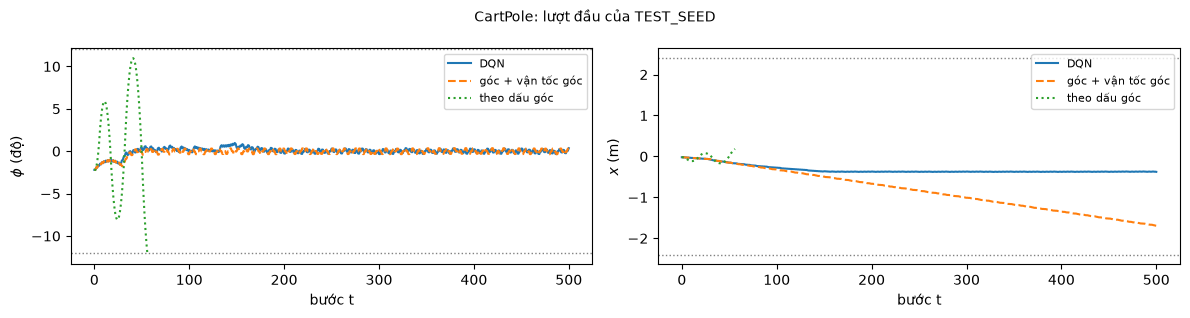

Trình phát: 3 lượt, HTML nhúng 32 kB


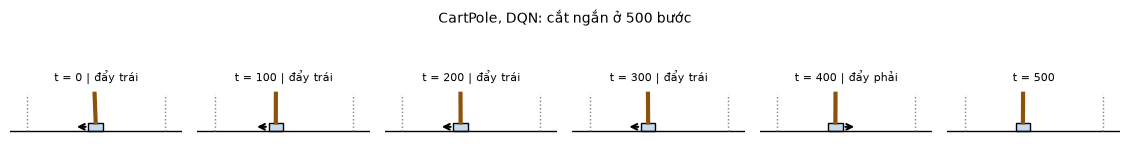

In [19]:
ep_cp = {"DQN": record_episode(envs[env_id], net_policy(q_cp), TEST_SEED, "cartpole"),
         "góc + vận tốc góc": episodes_ref[env_id]["góc + vận tốc góc"],
         "theo dấu góc": episodes_ref[env_id]["theo dấu góc"]}
plot_episodes(ep_cp, "CartPole: lượt đầu của TEST_SEED")
display(player(ep_cp))
filmstrip(ep_cp["DQN"], 6, f"CartPole, DQN: {end_reason(ep_cp['DQN'])}"); plt.show()

**Giá trị ước lượng so với lợi tức thực tế.** Với chính sách tham lam, $\max_aQ_\theta(O_t,a)$ là ước lượng của lợi tức chiết khấu kỳ vọng từ bước $t$. Ô mã dưới so ước lượng đó với $G_t=\sum_{k\ge0}\gamma^kR_{t+k+1}$ thực tế của cùng lượt, trên lượt đầu của `TEST_SEED` (hình) và trung bình của hiệu trên nửa đầu của $10$ lượt đầu (dòng in). Ở CartPole, lượt bị cắt ngắn ở bước $500$, nên $G_t$ giảm về $1$ ở cuối lượt; giá trị đúng của bài toán không có giới hạn thời gian thì không giảm, vì mục tiêu vẫn bootstrap qua bước cắt ngắn ($Z=0$). Phần cuối của hai đường vì vậy tách nhau mà không có nghĩa là mạng sai; nửa đầu lượt so được trực tiếp hơn, vì ở đó $\gamma^{500-t}\le0{,}99^{250}\approx0{,}08$ và $G_t=(1-\gamma^{500-t})/(1-\gamma)$ nằm trong khoảng $92$–$99{,}3$.

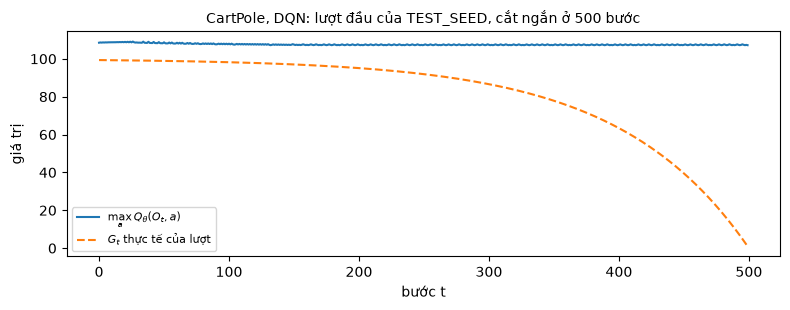

lượt đầu: max_a Q(O_0, a) = 108.5, G_0 = 99.3


10 lượt đầu của TEST_SEED: trung bình theo nửa đầu mỗi lượt của max_a Q - G_t = 10.8 ± 0.0 (SE)


In [20]:
plot_q_vs_return(q_cp, "CartPole-v1", "CartPole, DQN")

**Đọc hình.** Nếu đường $\max_aQ_\theta$ nằm trên $G_t$ ở nửa đầu lượt, mạng đánh giá cao giá trị của chính sách tham lam của chính nó; với CartPole, phần vượt trên $100$ không thể là giá trị đúng của bất kỳ chính sách nào. Một nguồn của độ lệch này là phép cực đại trong mục tiêu: với các ước lượng không chệch có nhiễu, kỳ vọng của cực đại lớn hơn hoặc bằng cực đại của các giá trị đúng (Sutton–Barto, ấn bản 2, §6.7). Một phần của hiệu in ra đến từ việc cắt ngắn: nếu giá trị đúng là $100$, phần $G_t$ bị cắt mất là $100\cdot0{,}99^{500-t}$, trung bình khoảng $3$ trên $t=0,\dots,249$ (vì $G_t$ trung bình khoảng $97{,}05$ trên nửa đầu lượt). Phần còn lại của hiệu, và phần vượt cận $100$ của $\max_aQ_\theta(O_0,a)$ (khoảng $8{,}5$ ở lần chạy khi soạn), là đánh giá cao thật. Hình và dòng in chỉ cho biết độ lệch trên các lượt này, không tách được phần do phép cực đại với phần do sai số xấp xỉ khác. Bài 09 (Double DQN) xét nguồn này; nhiệm vụ 1 ở mục 14 đo lại đại lượng ở đây với mục tiêu của Double DQN.

## 8. DQN trên Lunar Lander

**Vấn đề.** Lunar Lander có bốn hành động, phần thưởng $\pm100$ ở cuối lượt cộng phần định hình ở mỗi bước, và hai kết cục khác với hạ cánh trên bãi đáp: tàu lơ lửng tới khi bị cắt ngắn ở $1000$ bước, hoặc nằm yên ngoài bãi đáp (vẫn nhận $+100$). Notebook Bài 07 đã dùng đặc trưng Fourier cho môi trường này; ở đây mạng nhận thẳng quan sát $8$ chiều. Lần huấn luyện dưới mất khoảng ba phút trên CPU hai luồng khi soạn ($99\,001$ bước tối ưu).

Khác CartPole, phần thưởng một bước của Lunar Lander phụ thuộc độ thay đổi của hàm định hình và tài liệu môi trường không nêu cận cho nó (trên $20$ lượt ngẫu nhiên khi soạn, giá trị đo được nằm trong khoảng $-100$ tới $114{,}1$), nên hình phải không vẽ đường cận của giá trị.

159 giây | k_opt = 99001, số lần đồng bộ = 396, số lượt huấn luyện = 220


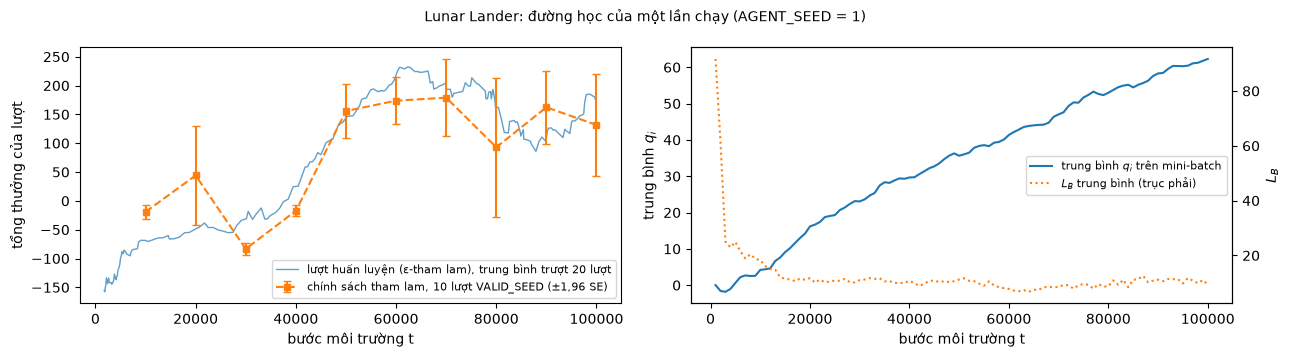

LunarLander-v3: 100 lượt TEST_SEED, trung bình ± SE
ngẫu nhiên                 tổng thưởng  -194.82 ± 12.30 (sd 123.00) | G_0  -98.93 | dài    101 | cắt ngắn   1%
điều khiển viết tay        tổng thưởng   236.89 ± 10.07 (sd 100.66) | G_0   68.79 | dài    267 | cắt ngắn   4%
DQN                        tổng thưởng   135.55 ± 13.02 (sd 130.19) | G_0   35.75 | dài    373 | cắt ngắn   7%
  DQN - ngẫu nhiên:   330.37 ±  31.10 (khoảng 95%, ghép cặp, tổng thưởng)
  DQN - điều khiển viết tay:  -101.34 ±  29.98 (khoảng 95%, ghép cặp, tổng thưởng)


In [21]:
env_id = "LunarLander-v3"
q_ll, log_ll = train_dqn(env_id, CFG[env_id])
print(f"{log_ll['train_secs']:.0f} giây | k_opt = {log_ll['k_opt']}, số lần đồng bộ = {log_ll['n_sync']}, "
      f"số lượt huấn luyện = {log_ll['n_episodes']}")
plot_learning(log_ll, "Lunar Lander: đường học của một lần chạy (AGENT_SEED = 1)")
res_ll = final_report(env_id, {"DQN": q_ll})

**Đọc kết quả.** Khi soạn, cấu hình này được chạy với năm hạt giống tác tử (bảng ở mục 10): tổng thưởng trung bình của chính sách cuối trên `TEST_SEED` là $175{,}1$; $162{,}7$; $204{,}0$; $254{,}0$; $247{,}2$, trung bình $208{,}6\pm18{,}4$ (SE giữa các hạt giống). Hiệu ghép cặp với bộ điều khiển viết tay của năm lần chạy đó là $-61{,}8$; $-74{,}1$; $-32{,}9$; $+17{,}1$; $+10{,}3$, khoảng tin cậy $95\%$ rộng cỡ $\pm20$–$31$: với ngân sách $10^5$ bước, DQN đạt gần nhưng thường chưa vượt bộ điều khiển viết tay. Lần chạy trong notebook là một mẫu của phân phối đó; với số luồng CPU hoặc phiên bản PyTorch khác, con số in ở trên lệch khỏi lần chạy khi soạn (cùng cấu hình chạy với hai luồng cho $135{,}5$ thay cho $175{,}1$ của một luồng). Cột "cắt ngắn" cho biết tỉ lệ lượt tàu lơ lửng tới bước $1000$: một chính sách học được có thể tránh phần thưởng $-100$ bằng cách không hạ cánh.

**Câu hỏi:** Đường kiểm định của Lunar Lander thường dao động mạnh giữa các mốc (mục 10 vẽ đường của năm hạt giống). Nêu hai nguyên nhân trong Thuật toán 08.13 có thể gây dao động này, và vì sao $10$ lượt kiểm định không đủ để kết luận về một mốc.

<details><summary>Lời giải</summary>

Thứ nhất, mục tiêu đổi tại mỗi mốc đồng bộ (Nhận xét 08.20), nên hàm mà mạng hồi quy về thay đổi theo từng đợt $C$ bước tối ưu; hai chính sách tham lam ở hai mốc liền nhau có thể khác nhau ở nhiều trạng thái dù $\theta$ chỉ thay đổi ít. Thứ hai, $\mathcal D$ chứa dữ liệu của hành vi đang thay đổi (Nhận xét 08.9), nên phân phối mẫu mà $L_B$ lấy trung bình cũng thay đổi; cả ba yếu tố của bộ ba bất ổn có mặt (Nhận xét 08.21). Với $10$ lượt và độ lệch chuẩn tổng thưởng cỡ $100$ (bộ điều khiển viết tay có sd $100{,}7$ trên `TEST_SEED`), SE của một mốc cỡ $30$, nên khoảng $\pm1{,}96\,\mathrm{SE}$ rộng khoảng $\pm60$; hiệu giữa hai mốc liền nhau nhỏ hơn cỡ đó không phân biệt được với nhiễu.
</details>

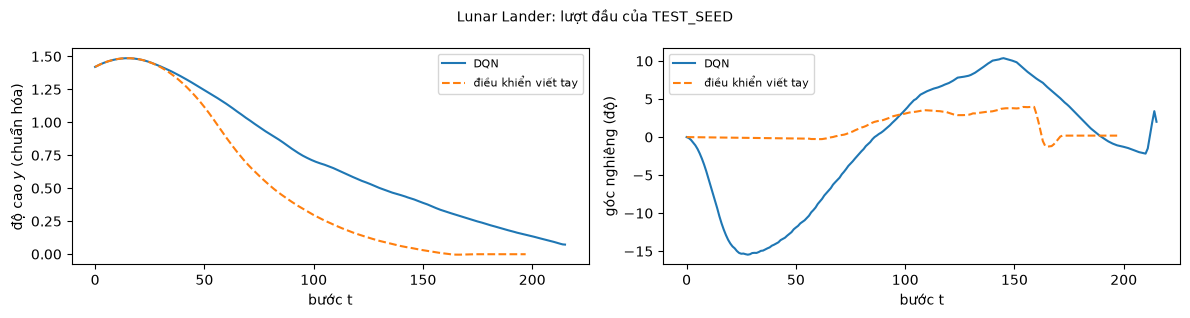

Trình phát: 2 lượt, HTML nhúng 22 kB


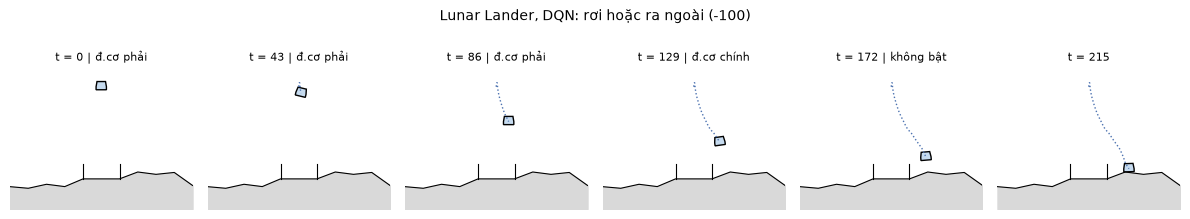

In [22]:
ep_ll = {"DQN": record_episode(envs[env_id], net_policy(q_ll), TEST_SEED, "lunar"),
         "điều khiển viết tay": episodes_ref[env_id]["điều khiển viết tay"]}
plot_episodes(ep_ll, "Lunar Lander: lượt đầu của TEST_SEED")
display(player(ep_ll))
filmstrip(ep_ll["DQN"], 6, f"Lunar Lander, DQN: {end_reason(ep_ll['DQN'])}"); plt.show()

**Giá trị ước lượng so với lợi tức thực tế.** Cùng phép so của mục 7, cho Lunar Lander. Lợi tức $G_t$ của một lượt là một mẫu, có phương sai lớn vì nhiễu của động cơ và kết cục $\pm100$ ở cuối lượt, nên một lượt riêng lẻ có thể lệch nhiều so với kỳ vọng; dòng in lấy trung bình trên $10$ lượt để giảm phần nhiễu này. Quan sát của Lunar Lander không đủ Markov theo nghĩa chặt (mục 2): cùng một quan sát ứng với nhiều trạng thái ẩn (địa hình, trạng thái khớp chân), và tỉ lệ các trạng thái ẩn đó phụ thuộc hành vi đã đưa tàu tới quan sát. $Q_\theta$ vì vậy ước lượng một trung bình theo các tỉ lệ do dữ liệu trong $\mathcal D$ quyết định, không phải một giá trị chỉ phụ thuộc quan sát.

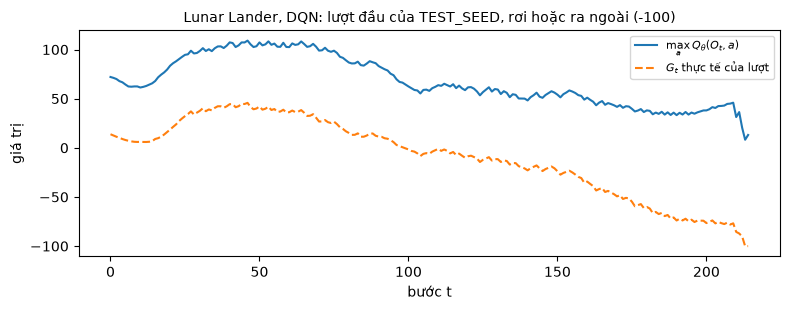

lượt đầu: max_a Q(O_0, a) = 72.1, G_0 = 13.8


10 lượt đầu của TEST_SEED: trung bình theo nửa đầu mỗi lượt của max_a Q - G_t = 46.2 ± 5.9 (SE)


In [23]:
plot_q_vs_return(q_ll, "LunarLander-v3", "Lunar Lander, DQN")

**Đọc hình.** Cách đọc giống mục 7: hiệu dương có hệ thống ở nửa đầu lượt là dấu hiệu đánh giá cao. Khác CartPole, ở đây không có cận đơn giản để biết giá trị nào chắc chắn sai, nên chỉ so được với lợi tức thực tế. Theo bảng nhiều hạt giống, DQN đạt gần nhưng thường chưa vượt bộ điều khiển viết tay trên Lunar Lander; mục 9 chuyển sang Flappy Bird, nơi mốc so sánh là một luật tay đơn giản hơn.

## 9. DQN trên Flappy Bird

**Vấn đề.** Ở Flappy Bird, một hành động sai trong vài bước gần ống đủ làm lượt kết thúc, và mỗi ống chỉ mang $+1$ sau khoảng $36$ bước $+0{,}1$. Quan sát $12$ chiều chứa vị trí tuyệt đối của ba ống và của chim; notebook Bài 07 phải tự dựng độ lệch giữa tâm chim và tâm khe, còn ở đây mạng phải tự học các đại lượng tương đối đó.

**Lịch thăm dò.** Lịch $\epsilon_{\mathrm{exp}}$ là một đầu vào của Thuật toán 08.13. Mục 7–8 dùng lịch bắt đầu từ $1$, như bảng siêu tham số Atari trong ghi chú. Với Flappy Bird, notebook dùng lịch $0{,}1\to0{,}001$ trong $10\%$ đầu, khác lịch Atari đó. Lý do nằm ở câu hỏi của mục 3: với $\epsilon_{\mathrm{exp}}=1$, hành vi là chọn đều, và dòng cuối của output ô đánh giá ở mục 3 cho thấy chính sách chọn đều chết trước ống đầu tiên sau khoảng $50$ bước; phần đầu của $\mathcal D$ vì vậy gần như chỉ chứa một kiểu tình huống. Ba lịch đã thử khi soạn, cùng $T=300\,000$, $F=4$, $C=250$, $\eta=5\cdot10^{-4}$, đánh giá chính sách cuối trên `TEST_SEED` (số ống trung bình, trung bình ± SE giữa các hạt giống):

| Lịch $\epsilon_{\mathrm{exp}}$ | Số hạt giống | Số ống của từng hạt giống | Trung bình ± SE |
|---|---|---|---|
| $1\to0{,}01$ trong $30\%$ đầu | $3$ | $5{,}5$; $4{,}1$; $3{,}0$ | $4{,}2\pm0{,}7$ |
| $1\to0{,}001$ trong $10\%$ đầu | $3$ | $5{,}1$; $24{,}7$; $12{,}3$ | $14{,}0\pm5{,}7$ |
| $0{,}1\to0{,}001$ trong $10\%$ đầu | $6$ | $38{,}9$; $16{,}4$; $46{,}6$; $33{,}9$; $15{,}3$; $4{,}3$ | $25{,}9\pm6{,}7$ |

Lịch thứ ba cho kết quả cao nhất nhưng phân tán lớn giữa các hạt giống. Lựa chọn này chỉ đổi một đầu vào của thuật toán và được chọn trên dữ liệu thu được (cùng thiên lệch chọn cấu hình nêu ở mục 10); phần thưởng và quan sát của môi trường giữ nguyên.

**Mốc kiểm định tốt nhất.** Đầu ra của Thuật toán 08.13 là chính sách tham lam theo $\theta$ khi $t=T$. Ở Flappy Bird, chính sách đó thay đổi nhiều giữa các mốc kiểm định, nên notebook báo thêm một bước chọn mô hình nằm ngoài Thuật toán 08.13: thuật toán vẫn chạy đủ $T$ bước, rồi trong $10$ mốc kiểm định, giữ bản sao của mạng tại mốc có tổng thưởng trung bình cao nhất trên $10$ lượt `VALID_SEED` (`keep_best=True`) và đánh giá bản đó trên `TEST_SEED`. Bước này khác tiêu chuẩn dừng mà ghi chú nêu (dừng sớm khi lợi tức đánh giá đạt một ngưỡng chọn trước): không có ngưỡng, không dừng sớm, và việc chọn xảy ra sau khi đã chạy hết ngân sách. Việc chọn chỉ dùng `VALID_SEED`, tách khỏi `TEST_SEED`, nên con số trên `TEST_SEED` không bị chính phép chọn này làm lạc quan. Cả hai chính sách đều được báo.

Khi mốc tốt nhất là mốc cuối ($t=T$), hai chính sách trùng nhau và ô mã chỉ báo một dòng. Lần huấn luyện dưới mất khoảng hai phút rưỡi trên CPU hai luồng khi soạn; với `LONG_BUDGET = True` ($T=500\,000$), khoảng bốn phút.

T = 300000 | 143 giây | k_opt = 74751, số lần đồng bộ = 299, số lượt huấn luyện = 2015 | mốc kiểm định tốt nhất: t = 300000


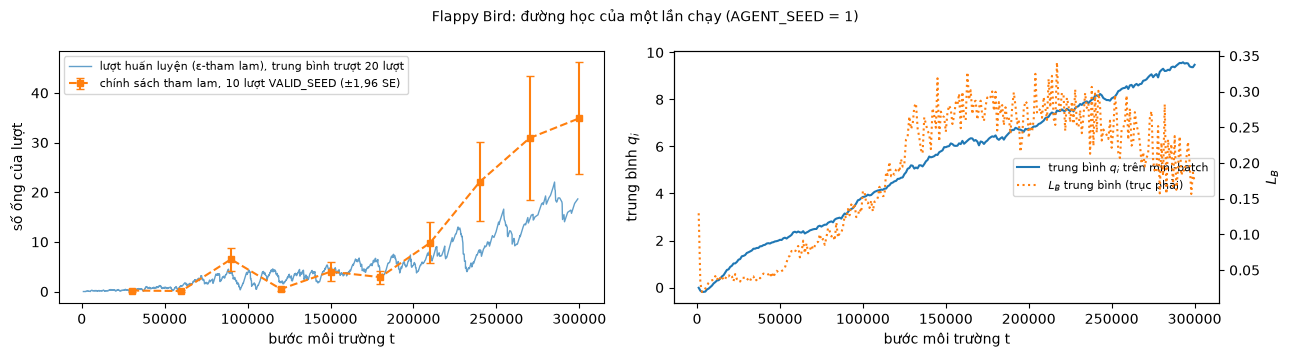

Mốc kiểm định tốt nhất là mốc cuối t = T: chính sách cuối và chính sách mốc tốt nhất trùng nhau.


FlappyBird-v0: 100 lượt TEST_SEED, trung bình ± SE
ngẫu nhiên p=0,08          ống     0.03 ±  0.02 (sd   0.17) | G_0    3.11 | dài     49 | cắt ngắn   0%
luật tay                   ống    34.30 ±  1.30 (sd  12.95) | G_0   11.56 | dài   1334 | cắt ngắn  23%
DQN cuối                   ống    35.64 ±  1.63 (sd  16.31) | G_0   11.37 | dài   1372 | cắt ngắn  44%
  DQN cuối - ngẫu nhiên p=0,08:    35.61 ±   3.19 (khoảng 95%, ghép cặp, số ống)
  DQN cuối - luật tay:     1.34 ±   3.72 (khoảng 95%, ghép cặp, số ống)


In [24]:
env_id = "FlappyBird-v0"
q_fb, log_fb, q_fb_best = train_dqn(env_id, CFG[env_id], keep_best=True)
print(f"T = {CFG[env_id]['T']} | {log_fb['train_secs']:.0f} giây | k_opt = {log_fb['k_opt']}, "
      f"số lần đồng bộ = {log_fb['n_sync']}, số lượt huấn luyện = {log_fb['n_episodes']} | "
      f"mốc kiểm định tốt nhất: t = {log_fb['best_t']}")
plot_learning(log_fb, "Flappy Bird: đường học của một lần chạy (AGENT_SEED = 1)", flappy=True)
learned_fb = {"DQN cuối": q_fb}
if log_fb["best_t"] != CFG[env_id]["T"]:                 # mốc tốt nhất khác mốc cuối: báo cả hai chính sách
    learned_fb["DQN mốc tốt nhất"] = q_fb_best
else:
    print("Mốc kiểm định tốt nhất là mốc cuối t = T: chính sách cuối và chính sách mốc tốt nhất trùng nhau.")
res_fb = final_report(env_id, learned_fb)

**Đọc kết quả.** Bảng của mục 10 ghi sáu hạt giống của cấu hình này khi soạn. Chính sách cuối đạt $38{,}9$; $16{,}4$; $46{,}6$; $33{,}9$; $15{,}3$; $4{,}3$ ống, trung bình $25{,}9\pm6{,}7$. Chính sách tại mốc kiểm định tốt nhất đạt $38{,}9$; $35{,}4$; $47{,}1$; $45{,}8$; $13{,}7$; $40{,}2$ ống, trung bình $36{,}8\pm5{,}0$. Trên cùng $100$ lượt `TEST_SEED`, luật tay với ngưỡng $0{,}02$ đạt $34{,}3$ ống và với ngưỡng $0{,}04$ đạt $42{,}5$ ống (mục 3); Q-learning tuyến tính và Sarsa tuyến tính của notebook Bài 07 đạt $28{,}9$ và $38{,}0$ ống, mỗi con số từ một hạt giống huấn luyện. Cấu hình DQN được chọn trên chính `TEST_SEED` (mục 10), nên hai trung bình $25{,}9$ và $36{,}8$ là ước lượng lạc quan. Với ngân sách $300\,000$ bước, trung bình của DQN vì vậy ở cỡ luật tay ngưỡng $0{,}02$ và hai phương pháp tuyến tính, thấp hơn luật tay tốt nhất trong bốn ngưỡng; kết quả của một lần chạy có thể nằm ở bất kỳ đâu trong khoảng $4$–$47$ ống. Với $T=500\,000$ (ba hạt giống), chính sách cuối đạt $22{,}3$; $44{,}5$; $3{,}7$ ống, còn mốc tốt nhất đạt $48{,}4$; $46{,}5$; $43{,}5$: ngân sách lớn hơn làm các mốc tốt hơn nhưng không làm chính sách cuối ổn định hơn. Bảng in ở trên là của lần chạy trong notebook; đọc nó như một mẫu của các phân phối vừa nêu.

Hai đường ở hình trái đo hai thứ khác nhau. Đường liền là số ống của các lượt huấn luyện: hành vi vẫn thăm dò ($\epsilon_{\mathrm{exp}}=0{,}001$ sau $10\%$ đầu, tức trung bình $1{,}8$ hành động ngẫu nhiên trong một lượt $1800$ bước) và mỗi lượt dài trải qua nhiều phiên bản $\theta$. Các điểm vuông là chính sách tham lam tại một $\theta$ cố định, đúng đối tượng mà phép đánh giá cuối đo.

DQN cuối            1755 bước, va chạm, 45 ống
luật tay            1365 bước, va chạm, 35 ống


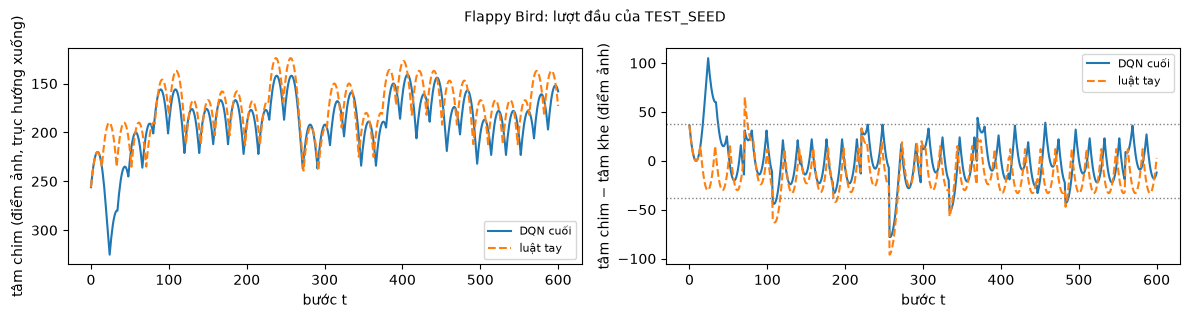

Trình phát: 2 lượt, HTML nhúng 97 kB; vẽ mỗi 2 bước để hiển thị trọn lượt dài 1755 bước


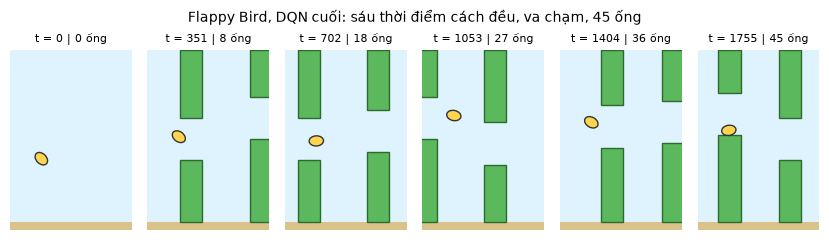

In [25]:
ep_fb = {name: record_episode(envs[env_id], net_policy(net), TEST_SEED, "flappy") for name, net in learned_fb.items()}
ep_fb["luật tay"] = episodes_ref[env_id]["luật tay"]
for name, ep in ep_fb.items():
    print(f"{name:<18} {len(ep['actions']):5d} bước, {end_reason(ep)}")
plot_episodes(ep_fb, "Flappy Bird: lượt đầu của TEST_SEED")
display(player(ep_fb))
name_fb = list(learned_fb)[-1]
filmstrip(ep_fb[name_fb], 6, f"Flappy Bird, {name_fb}: sáu thời điểm cách đều, {end_reason(ep_fb[name_fb])}"); plt.show()

## 10. Thử nghiệm sơ bộ dùng để chọn cấu hình

**Cách chạy.** Trước khi soạn notebook, mỗi cấu hình được huấn luyện bằng cùng hàm `train_dqn` với ba đến sáu hạt giống tác tử $s$ (hạt giống của lượt huấn luyện thứ $k$ là $20\,000+100\,000\,s+k$, nên $s=1$ trùng `TRAIN_SEED` của notebook). Chính sách tham lam cuối được đánh giá trên $100$ lượt `TEST_SEED`; với các lần chạy sau khi thêm tùy chọn `keep_best`, chính sách tại mốc kiểm định tốt nhất cũng được đánh giá. Các lần chạy dùng một luồng CPU mỗi lần và chạy song song mười hai lần một lúc, nên cột thời gian lớn hơn thời gian của notebook khoảng $1{,}5$–$2$ lần. Ô mã dưới chứa kết quả đã tổng hợp (mỗi hạt giống một con số), không chứa mô hình hay nhật ký đầy đủ.

**Thiên lệch chọn cấu hình.** Cấu hình ở mục 7–9 được chọn bằng cách xem chính các con số trên `TEST_SEED` dưới đây, cùng độ phân tán giữa hạt giống và thời gian chạy; không có tập lượt riêng cho việc chọn cấu hình, và không có quy tắc chọn đặt trước. Vì vậy kết quả trên `TEST_SEED` của cấu hình được chọn là ước lượng lạc quan. Một đánh giá không thiên lệch cần chọn cấu hình trên một tập hạt giống khác rồi báo kết quả trên `TEST_SEED` một lần (nhiệm vụ 6 ở mục 14). Ngược lại, phép chọn mốc kiểm định tốt nhất ở mục 9 chỉ dùng `VALID_SEED`.

Cột "TB ± SE" là trung bình và sai số chuẩn giữa các hạt giống của đại lượng ghi ở từng hạt giống (tổng thưởng trung bình trên $100$ lượt, hoặc số ống trung bình với Flappy Bird). Dòng đánh dấu `*` là cấu hình được chọn; các dòng `abl_` là thí nghiệm loại bỏ của mục 11.

In [26]:
# Dữ liệu ghi nhận khi soạn notebook, chạy ngoài notebook: 100 lượt TEST_SEED cho mỗi hạt giống
# (tên, T, F, C, lớp ẩn, b, N, tốc độ học eta, eps_exp đầu, eps_exp cuối, tỉ lệ T giảm eps, mất mát, bộ nhớ phát lại,
#  điểm từng hạt giống, điểm của mốc kiểm định tốt nhất từng hạt giống hoặc None, giây huấn luyện TB khi chạy song song)
PRELIM = {
    "CartPole-v1": [
        ("a_base", 50000, 1, 500, (128, 128), 64, 50000, 0.001, 1.0, 0.05, 0.2, "mse", True,
         [494.3, 279.41, 500.0], None, 143),
        ("abl_C1", 50000, 1, 1, (64, 64), 64, 50000, 0.001, 1.0, 0.05, 0.2, "mse", True,
         [500.0, 500.0, 339.04, 498.24, 497.44], [500.0, 500.0, 341.14, 500.0, 500.0], 137),
        ("abl_both", 50000, 1, 1, (64, 64), 64, 50000, 0.001, 1.0, 0.05, 0.2, "mse", False,
         [500.0, 500.0, 281.94, 500.0, 500.0], [500.0, 496.29, 500.0, 500.0, 500.0], 132),
        ("abl_norep", 50000, 1, 200, (64, 64), 64, 50000, 0.001, 1.0, 0.05, 0.2, "mse", False,
         [269.21, 480.86, 174.52, 421.91, 210.09], [393.04, 500.0, 458.56, 421.91, 500.0], 109),
        ("b_F4C100", 50000, 4, 100, (128, 128), 64, 50000, 0.001, 1.0, 0.05, 0.2, "mse", True,
         [483.05, 202.45, 221.06], None, 47),
        ("c_lr5e-4", 50000, 1, 500, (128, 128), 64, 50000, 0.0005, 1.0, 0.05, 0.2, "mse", True,
         [168.42, 130.6, 190.71], None, 139),
        ("d_T100kF4C250", 100000, 4, 250, (128, 128), 64, 50000, 0.001, 1.0, 0.05, 0.2, "mse", True,
         [500.0, 417.12, 404.42], None, 99),
        ("e_h64C200", 50000, 1, 200, (64, 64), 64, 50000, 0.001, 1.0, 0.05, 0.2, "mse", True,
         [500.0, 500.0, 500.0, 500.0, 500.0, 247.49], [500.0, 500.0, 500.0, 500.0, 500.0, 500.0], 90),
        ("f_huber", 50000, 1, 500, (128, 128), 64, 50000, 0.001, 1.0, 0.05, 0.2, "huber", True,
         [340.13, 164.49, 500.0], None, 137),
        ("g_N10k", 50000, 1, 500, (128, 128), 64, 10000, 0.001, 1.0, 0.05, 0.2, "mse", True,
         [193.69, 236.04, 228.92], None, 139),
        ("h_h64C200_T30k", 30000, 1, 200, (64, 64), 64, 50000, 0.001, 1.0, 0.05, 0.2, "mse", True,
         [220.45, 238.22, 286.79], None, 68),
        ("i_h64F2C100", 50000, 2, 100, (64, 64), 64, 50000, 0.001, 1.0, 0.05, 0.2, "mse", True,
         [405.17, 272.9, 500.0], None, 71),
    ],
    "LunarLander-v3": [
        ("a_base", 150000, 4, 250, (128, 128), 64, 100000, 0.0005, 1.0, 0.05, 0.3, "mse", True,
         [67.71, -75.08, -15.24], None, 158),
        ("abl_C1", 100000, 1, 1, (128, 128), 128, 50000, 0.00063, 1.0, 0.1, 0.12, "mse", True,
         [-31.2, 192.68, 203.13], [-19.22, 192.68, 240.86], 291),
        ("abl_norep", 100000, 1, 250, (128, 128), 128, 50000, 0.00063, 1.0, 0.1, 0.12, "mse", False,
         [-215.75, -295.43, -155.02], [-110.37, -46.6, -37.43], 259),
        ("b_T200k_b128", 200000, 4, 250, (128, 128), 128, 100000, 0.00063, 1.0, 0.1, 0.12, "mse", True,
         [130.59, -76.39, 234.28], None, 204),
        ("c_zooF1", 100000, 1, 250, (256, 256), 128, 50000, 0.00063, 1.0, 0.1, 0.12, "mse", True,
         [158.83, 173.4, 140.73], None, 518),
        ("d_h256", 150000, 4, 250, (256, 256), 64, 100000, 0.0005, 1.0, 0.05, 0.3, "mse", True,
         [-44.27, -75.0, -18.47], [-18.09, -25.4, 45.46], 176),
        ("e_zooF1_h128", 100000, 1, 250, (128, 128), 128, 50000, 0.00063, 1.0, 0.1, 0.12, "mse", True,
         [175.08, 162.74, 203.98, 253.98, 247.16], [147.22, 162.74, 203.98, 220.8, 247.16], 304),
        ("f_zooF1_T150k", 150000, 1, 250, (256, 256), 128, 50000, 0.00063, 1.0, 0.1, 0.12, "mse", True,
         [207.5, -50.94, -50.65], None, 822),
        ("g_F2_T200k", 200000, 2, 250, (256, 256), 128, 50000, 0.00063, 1.0, 0.1, 0.12, "mse", True,
         [-39.53, 192.95, 263.78], None, 609),
        ("h_zooF1_eps05", 100000, 1, 250, (256, 256), 128, 50000, 0.00063, 1.0, 0.05, 0.1, "mse", True,
         [172.21, -77.87, 61.07], None, 565),
        ("j_zooF1_h128_C500", 100000, 1, 500, (128, 128), 128, 50000, 0.00063, 1.0, 0.1, 0.12, "mse", True,
         [133.27, 257.24, 59.8], [192.11, 257.24, 212.64], 315),
        ("k_zooF1_h128_lr3e-4", 100000, 1, 250, (128, 128), 128, 50000, 0.0003, 1.0, 0.1, 0.12, "mse", True,
         [211.16, 111.0, 143.85], [211.16, 111.0, 143.92], 307),
    ],
    "FlappyBird-v0": [
        ("a_base", 300000, 4, 250, (128, 128), 64, 100000, 0.0005, 1.0, 0.01, 0.3, "mse", True,
         [5.5, 4.07, 3.0], None, 246),
        ("b_T200kF2C500", 200000, 2, 500, (128, 128), 64, 100000, 0.0005, 1.0, 0.01, 0.3, "mse", True,
         [2.62, 0.46, 2.28], None, 271),
        ("c_epsfast", 300000, 4, 250, (128, 128), 64, 100000, 0.0005, 1.0, 0.001, 0.1, "mse", True,
         [5.09, 24.71, 12.32], None, 243),
        ("d_T500k_epsfast", 500000, 4, 250, (128, 128), 64, 100000, 0.0005, 1.0, 0.001, 0.1, "mse", True,
         [30.73, 30.89, 25.97], [30.73, 48.6, 38.19], 435),
        ("e_F2C500_epsfast", 300000, 2, 500, (128, 128), 64, 100000, 0.0005, 1.0, 0.001, 0.1, "mse", True,
         [46.39, 38.21, 1.0], [46.39, 38.21, 1.0], 438),
        ("f_lr1e-3_epsfast", 300000, 4, 250, (128, 128), 64, 100000, 0.001, 1.0, 0.001, 0.1, "mse", True,
         [13.8, 31.84, 24.16], [17.99, 31.84, 24.16], 264),
        ("g_eps0.1start", 300000, 4, 250, (128, 128), 64, 100000, 0.0005, 0.1, 0.001, 0.1, "mse", True,
         [38.87, 16.42, 46.63, 33.94, 15.29, 4.3], [38.87, 35.41, 47.14, 45.77, 13.74, 40.17], 287),
        ("h_h256b128_epsfast", 300000, 4, 250, (256, 256), 128, 100000, 0.0005, 1.0, 0.001, 0.1, "mse", True,
         [11.34, 44.1, 0.0], [45.67, 44.1, 0.0], 514),
        ("i_T1M_epsfast", 1000000, 4, 250, (128, 128), 64, 100000, 0.0005, 1.0, 0.001, 0.1, "mse", True,
         [37.36, 34.29, 33.89], [43.3, 46.68, 37.28], 936),
        ("l_eps0.1_F2C500", 300000, 2, 500, (128, 128), 64, 100000, 0.0005, 0.1, 0.001, 0.1, "mse", True,
         [12.8, 24.5, 15.05], [44.86, 24.5, 41.07], 452),
        ("m_eps0.1_T500k", 500000, 4, 250, (128, 128), 64, 100000, 0.0005, 0.1, 0.001, 0.1, "mse", True,
         [22.3, 44.52, 3.73], [48.44, 46.54, 43.53], 444),
        ("n_eps0.1_lr1e-3", 300000, 4, 250, (128, 128), 64, 100000, 0.001, 0.1, 0.001, 0.1, "mse", True,
         [28.02, 48.03, 0.34], [28.02, 48.03, 24.44], 281),
    ],
}
# đường kiểm định của cấu hình được chọn: {env: (các mốc t, [[giá trị 10 mốc] cho từng hạt giống])}
PRELIM_CURVES = {
    "CartPole-v1": ([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000, 45000, 50000], [[289.7, 227.0, 134.5, 155.5, 500.0, 500.0, 189.3, 333.0, 500.0, 500.0], [224.0, 251.1, 407.3, 497.3, 139.2, 476.3, 500.0, 220.2, 500.0, 500.0], [215.1, 185.8, 233.6, 135.3, 99.0, 160.1, 305.4, 497.7, 500.0, 500.0], [314.7, 245.0, 135.2, 250.3, 212.1, 150.5, 258.4, 239.0, 352.6, 500.0], [304.8, 500.0, 500.0, 500.0, 249.2, 210.8, 136.5, 161.9, 143.5, 500.0], [183.1, 172.4, 138.3, 203.6, 224.5, 199.3, 268.4, 500.0, 500.0, 245.4]]),
    "LunarLander-v3": ([10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000], [[-28.7, 6.3, -25.9, -8.4, 206.9, 33.5, 204.3, 156.5, 204.2, 173.3], [-203.7, -92.6, -34.7, -59.6, -21.0, -70.9, -41.3, -84.4, 76.2, 134.3], [-41.3, -64.9, -83.5, -89.7, -57.7, 76.1, -89.0, -40.3, 146.9, 180.2], [-13.1, -7.3, -256.5, 251.8, 161.3, 156.0, 177.3, 119.2, 208.2, 246.8], [-304.4, -150.2, -55.1, 21.0, -43.6, 161.8, -64.0, 86.9, -0.1, 243.0]]),
    "FlappyBird-v0": ([30000, 60000, 90000, 120000, 150000, 180000, 210000, 240000, 270000, 300000], [[0.2, 1.2, 1.6, 3.3, 3.0, 6.7, 9.1, 9.1, 8.6, 40.9], [1.1, 1.4, 4.0, 4.8, 11.1, 17.5, 24.8, 28.5, 35.5, 8.6], [1.2, 2.0, 4.0, 4.6, 10.7, 28.7, 44.5, 28.5, 46.3, 39.8], [0.5, 0.9, 2.0, 3.4, 3.3, 23.4, 10.2, 48.8, 43.3, 30.2], [0.0, 0.9, 0.0, 3.0, 3.4, 5.0, 5.4, 5.9, 17.5, 15.0], [1.5, 0.1, 3.4, 8.0, 11.2, 5.1, 18.3, 34.9, 20.7, 4.1]]),
}
# loại bỏ trên CartPole (5 hạt giống): {nhánh: (t mỗi 2000 bước, [[q trung bình] từng hạt giống])}
ABL_Q = {
    "e_h64C200": ([2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000, 18000, 20000, 22000, 24000, 26000, 28000, 30000, 32000, 34000, 36000, 38000, 40000, 42000, 44000, 46000, 48000, 50000], [[3.0, 11.6, 21.9, 31.1, 39.2, 45.6, 50.6, 54.5, 58.7, 60.7, 62.5, 64.3, 67.1, 68.2, 69.9, 71.9, 74.1, 76.8, 78.9, 80.4, 80.8, 82.8, 83.9, 86.1, 87.9], [2.8, 11.1, 20.8, 30.5, 38.6, 44.4, 48.4, 53.6, 57.1, 59.4, 62.0, 64.5, 66.2, 68.7, 71.2, 72.4, 74.7, 77.3, 79.9, 83.9, 86.3, 88.8, 91.3, 95.1, 97.5], [2.8, 11.2, 20.2, 29.0, 36.4, 42.0, 46.9, 52.1, 56.6, 60.7, 63.1, 64.6, 66.9, 68.3, 70.5, 72.1, 73.1, 74.7, 77.6, 80.4, 82.4, 85.3, 87.4, 89.5, 92.2], [2.8, 11.6, 21.5, 31.2, 38.6, 44.1, 49.8, 54.6, 57.3, 59.8, 62.2, 64.6, 67.5, 68.0, 69.5, 71.5, 73.4, 75.0, 77.3, 79.5, 82.6, 84.7, 86.9, 89.0, 90.1], [2.8, 11.2, 21.0, 30.0, 38.7, 47.4, 53.8, 61.8, 67.4, 71.9, 78.1, 81.6, 84.2, 87.5, 90.1, 92.0, 95.4, 99.4, 101.6, 101.6, 102.0, 102.4, 103.5, 106.6, 112.1]]),
    "abl_C1": ([2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000, 18000, 20000, 22000, 24000, 26000, 28000, 30000, 32000, 34000, 36000, 38000, 40000, 42000, 44000, 46000, 48000, 50000], [[421.6, 139.0, 87.2, 84.8, 165.2, 250.8, 326.1, 355.5, 353.0, 325.1, 330.2, 364.2, 339.5, 348.2, 287.0, 253.6, 240.7, 220.1, 197.1, 197.3, 192.9, 202.1, 195.3, 210.5, 255.2], [55.2, 238.1, 1270.4, 2064.4, 1889.5, 1575.3, 1158.7, 944.7, 838.3, 748.2, 748.2, 583.5, 495.1, 510.5, 463.6, 463.3, 537.5, 470.2, 517.1, 555.4, 1287.6, 1363.5, 463.9, 358.8, 331.7], [41.8, 488.4, 1299.5, 1325.8, 791.2, 433.7, 686.0, 603.5, 328.2, 254.4, 373.7, 528.2, 861.8, 1357.0, 1095.8, 774.8, 1881.1, 879.6, 1682.7, 981.1, 722.5, 1048.5, 616.7, 449.1, 484.3], [43.8, 412.6, 2013.8, 2796.1, 1785.7, 1343.7, 1077.7, 827.1, 635.5, 397.8, 249.7, 250.6, 257.1, 333.5, 713.2, 693.3, 709.7, 665.9, 625.0, 597.5, 584.2, 622.4, 525.5, 429.5, 371.1], [37.9, 351.4, 2050.7, 2422.7, 1946.2, 1799.8, 1459.2, 1044.6, 720.1, 542.2, 422.0, 343.2, 419.0, 393.8, 464.9, 572.7, 764.5, 567.9, 572.5, 501.0, 538.2, 324.8, 326.9, 359.0, 363.7]]),
    "abl_norep": ([2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000, 18000, 20000, 22000, 24000, 26000, 28000, 30000, 32000, 34000, 36000, 38000, 40000, 42000, 44000, 46000, 48000, 50000], [[3.0, 12.0, 20.0, 26.0, 31.2, 37.8, 43.7, 44.2, 53.2, 58.1, 59.9, 65.7, 66.9, 68.3, 64.0, 65.6, 72.2, 73.4, 77.4, 74.6, 89.0, 85.9, 95.4, 90.0, 85.8], [2.8, 11.3, 18.5, 26.5, 31.7, 31.1, 35.1, 50.7, 53.4, 51.4, 42.8, 62.7, 61.7, 85.0, 72.9, 90.6, 94.8, 88.6, 90.5, 95.2, 99.1, 75.7, 78.8, 71.2, 64.6], [2.9, 11.6, 21.4, 23.6, 34.7, 42.6, 43.1, 52.0, 63.1, 59.5, 61.8, 61.7, 63.5, 58.4, 67.7, 64.2, 65.5, 58.8, 85.7, 69.2, 95.6, 98.8, 102.6, 94.7, 77.3], [2.9, 10.9, 19.0, 28.6, 33.1, 37.6, 43.0, 46.0, 46.6, 58.6, 63.4, 60.6, 71.8, 73.6, 77.0, 86.2, 82.8, 85.7, 87.1, 86.1, 87.4, 86.9, 89.9, 84.2, 85.1], [2.9, 12.2, 20.5, 26.5, 33.0, 36.5, 42.8, 53.8, 44.5, 50.8, 61.1, 58.1, 70.2, 70.7, 69.2, 79.8, 82.4, 78.5, 90.3, 86.3, 85.8, 73.8, 81.3, 71.3, 71.2]]),
    "abl_both": ([2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000, 18000, 20000, 22000, 24000, 26000, 28000, 30000, 32000, 34000, 36000, 38000, 40000, 42000, 44000, 46000, 48000, 50000], [[155.6, 153.9, 161.6, 116.5, 107.8, 102.2, 101.5, 101.0, 102.9, 82.5, 100.0, 72.7, 109.7, 105.1, 104.4, 98.1, 87.6, 68.3, 83.0, 67.2, 107.2, 55.3, 67.5, 108.6, 102.6], [48.4, 265.9, 504.8, 212.6, 92.1, 111.5, 109.4, 55.0, 115.4, 77.2, 364.5, 73.4, 105.5, 107.3, 103.1, 123.9, 117.2, 85.2, 66.5, 99.2, 309.5, 95.9, 69.4, 75.0, 79.0], [72.7, 368.8, 374.5, 95.9, 111.4, 108.7, 155.9, 77.4, 101.4, 104.7, 106.9, 186.4, 107.5, 63.2, 74.3, 100.0, 166.0, 56.6, 62.4, 58.8, 74.0, 156.0, 50.7, 63.5, 121.9], [962.7, 171.3, 118.5, 82.7, 28.9, 68.8, 42.0, 43.1, 85.7, 49.0, 53.7, 54.8, 84.3, 69.0, 31.4, 90.9, 50.4, 170.9, 55.3, 26.2, 86.0, 41.5, 42.5, 103.0, 111.6], [88.1, 147.0, 122.3, 104.4, 78.3, 190.5, 38.1, 63.2, 64.8, 85.2, 92.5, 96.8, 36.7, 81.2, 57.5, 128.4, 51.0, 60.5, 121.2, 80.3, 118.0, 89.7, 87.1, 110.7, 103.3]]),
}
# max theo t của trung bình q_i trên mini-batch (mỗi 1000 bước), từng hạt giống: cấu hình được chọn và nhánh loại bỏ
QMAX = {
    ("CartPole-v1", "e_h64C200"): [87.9, 97.5, 92.2, 90.1, 112.1, 110.6],
    ("LunarLander-v3", "e_zooF1_h128"): [71.4, 46.3, 52.7, 70.0, 63.7],
    ("FlappyBird-v0", "g_eps0.1start"): [8.4, 10.2, 10.8, 10.7, 7.7, 11.1],
    ("CartPole-v1", "abl_C1"): [421.6, 2068.1, 1881.1, 2796.1, 2455.0],
    ("CartPole-v1", "abl_norep"): [108.9, 99.1, 102.9, 92.8, 91.9],
    ("CartPole-v1", "abl_both"): [192.4, 504.8, 374.5, 962.7, 190.5],
    ("LunarLander-v3", "abl_C1"): [50.0, 64.9, 72.9],
    ("LunarLander-v3", "abl_norep"): [100.2, 112.0, 109.4],
}

CHOSEN = {"CartPole-v1": "e_h64C200", "LunarLander-v3": "e_zooF1_h128", "FlappyBird-v0": "g_eps0.1start"}


def show_prelim(env_id, ablation=False):
    unit = "ống" if env_id == "FlappyBird-v0" else "tổng thưởng"
    print(f"{env_id} ({unit} trên TEST_SEED; eps: đầu→cuối/tỉ lệ T)")
    print(f"  {'cấu hình':<22}{'T':>8}{'F':>3}{'C':>6}{'h':>5}{'b':>5}{'eta':>9}{'eps':>16}{'mất mát':>8}{'phát lại':>9}"
          f"{'n':>3}{'TB ± SE':>16}{'giây':>6}  từng hạt giống | mốc tốt nhất")
    for (name, T, F, C, hid, b, N, lr, e0, e1, fr, loss, rep, seeds, best, secs) in PRELIM[env_id]:
        if name.startswith("abl_") != ablation and not (ablation and name == CHOSEN[env_id]):
            continue
        v = np.array(seeds); se = v.std(ddof=1) / np.sqrt(len(v))
        mark = "*" if name == CHOSEN[env_id] else " "
        print(f"{mark} {name:<22}{T:>8}{F:>3}{C:>6}{hid[0]:>5}{b:>5}{lr:>9.1e}{f'{e0:g}→{e1:g}/{fr:g}':>16}{loss:>8}"
              f"{'có' if rep else 'không':>9}{len(v):>3}{f'{v.mean():.1f} ± {se:.1f}':>16}{secs:>6}  {seeds}"
              + (f" | {best}" if best else ""))


for env_id in ENV_IDS:
    show_prelim(env_id); print()
print("Giá trị lớn nhất theo t của trung bình q_i trên mini-batch, từng hạt giống, cấu hình được chọn:")
for env_id in ENV_IDS:
    print(f"  {env_id:<15} {QMAX[(env_id, CHOSEN[env_id])]}")

CartPole-v1 (tổng thưởng trên TEST_SEED; eps: đầu→cuối/tỉ lệ T)
  cấu hình                     T  F     C    h    b      eta             eps mất mát phát lại  n         TB ± SE  giây  từng hạt giống | mốc tốt nhất
  a_base                   50000  1   500  128   64  1.0e-03      1→0.05/0.2     mse       có  3    424.6 ± 72.6   143  [494.3, 279.41, 500.0]
  b_F4C100                 50000  4   100  128   64  1.0e-03      1→0.05/0.2     mse       có  3    302.2 ± 90.6    47  [483.05, 202.45, 221.06]
  c_lr5e-4                 50000  1   500  128   64  5.0e-04      1→0.05/0.2     mse       có  3    163.2 ± 17.5   139  [168.42, 130.6, 190.71]
  d_T100kF4C250           100000  4   250  128   64  1.0e-03      1→0.05/0.2     mse       có  3    440.5 ± 30.0    99  [500.0, 417.12, 404.42]
* e_h64C200                50000  1   200   64   64  1.0e-03      1→0.05/0.2     mse       có  6    457.9 ± 42.1    90  [500.0, 500.0, 500.0, 500.0, 500.0, 247.49] | [500.0, 500.0, 500.0, 500.0, 500.0, 500.0]
 

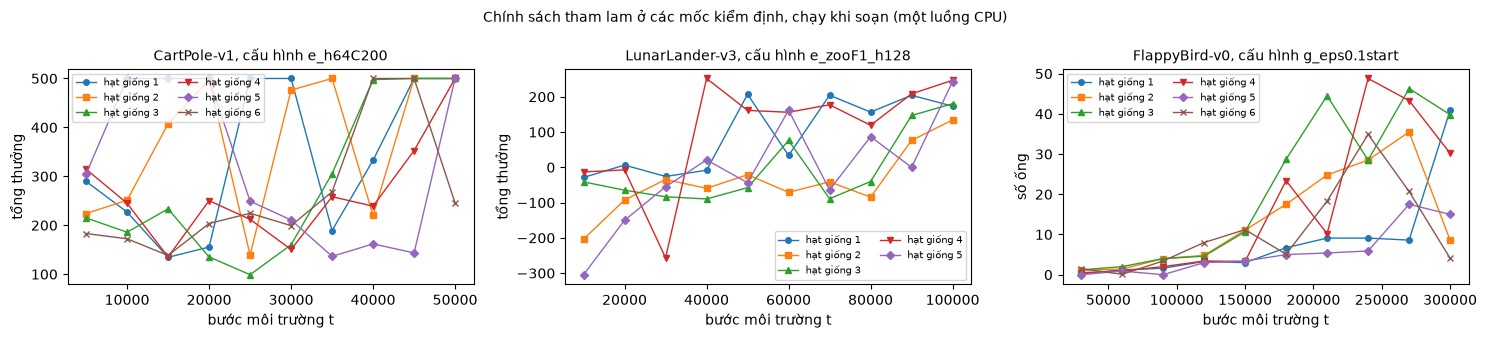

In [27]:
# Đường kiểm định (10 lượt VALID_SEED mỗi mốc) của cấu hình được chọn, mọi hạt giống chạy khi soạn
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, env_id in zip(axes, ENV_IDS):
    ts, curves = PRELIM_CURVES[env_id]
    for s, c in enumerate(curves, start=1):
        ax.plot(ts, c, marker="os^vDx"[s - 1], ls="-", lw=1, ms=4, label=f"hạt giống {s}")
    ax.set_title(f"{env_id}, cấu hình {CHOSEN[env_id]}", fontsize=10); ax.set_xlabel("bước môi trường t")
    ax.set_ylabel("số ống" if env_id == "FlappyBird-v0" else "tổng thưởng"); ax.legend(fontsize=7, ncol=2)
fig.suptitle("Chính sách tham lam ở các mốc kiểm định, chạy khi soạn (một luồng CPU)", fontsize=10)
fig.tight_layout(); plt.show()

**Đọc kết quả.** Bảng và hình cho bốn quan sát, mỗi quan sát có phạm vi riêng.

- Kết quả phụ thuộc mạnh vào cấu hình. Ở Lunar Lander, cùng thuật toán cho từ $-45{,}9$ (cấu hình `d_h256`) tới $208{,}6$ (cấu hình được chọn); ở Flappy Bird, từ $1{,}8$ tới $35{,}2$ ống; ở CartPole, từ $163{,}2$ tới $457{,}9$.
- Huấn luyện lâu hơn có thể làm chính sách cuối kém đi. Ở Lunar Lander, tăng $T$ từ $10^5$ lên $1{,}5\cdot10^5$ (cấu hình `f_zooF1_T150k` so với `c_zooF1`) hạ trung bình từ $157{,}7$ xuống $35{,}3$ vì hai trong ba hạt giống sụt ở cuối. Ở Flappy Bird, với $T=500\,000$ (cấu hình `m_eps0.1_T500k`), chính sách cuối của một hạt giống chỉ đạt $3{,}7$ ống trong khi mốc tốt nhất của nó đạt $43{,}5$.
- Đường kiểm định của từng hạt giống không đơn điệu ở cả ba cấu hình được chọn: chính sách đạt mức cao ở một mốc có thể sụt ở mốc sau.
- Trong các lần chạy của ba cấu hình được chọn, trung bình $q_i$ không tăng không chặn: giá trị lớn nhất theo $t$ là $87{,}9$–$112{,}1$ ở CartPole, $46{,}3$–$71{,}4$ ở Lunar Lander và $7{,}7$–$11{,}1$ ở Flappy Bird (bảng `QMAX`).

Các quan sát này phù hợp với Nhận xét 08.21 (Thuật toán 08.13 không có bảo đảm hội tụ tổng quát) mà không chứng minh nó. Nhu cầu chạy nhiều hạt giống có lý do riêng: với ngân sách hữu hạn, kết quả của cùng một cấu hình phân tán lớn giữa các hạt giống (ở Flappy Bird, từ $4{,}3$ tới $46{,}6$ ống), nên hiệu giữa hai cấu hình đo trên một hạt giống mỗi bên thường nhỏ hơn độ phân tán đó.

## 11. Thí nghiệm loại bỏ: mạng mục tiêu và bộ nhớ phát lại

**Vấn đề.** Nhận xét 08.19 gán cho mạng mục tiêu và bộ nhớ phát lại hai vai trò: giữ mục tiêu đứng yên trong $C$ bước tối ưu, và giảm tương quan giữa các mẫu trong một mini-batch. Bài tập 08.3 thiết kế một thí nghiệm loại bỏ trên giấy. Thí nghiệm đó được chạy dưới đây trên CartPole, với cấu hình của mục 7 và hai nhánh:

- **bỏ mạng mục tiêu:** $C=1$, nên $\theta^-\leftarrow\theta$ sau mọi bước tối ưu và mục tiêu tính bằng đúng tham số đang học (Ví dụ 08.5);
- **bỏ bộ nhớ phát lại:** mỗi bước tối ưu dùng $b$ mẫu chuyển vừa thu theo thứ tự thời gian (`replay=False`, hàm `Replay.last`), giữ $F$, $C$ và số bước tối ưu như cấu hình đầy đủ.

Mỗi nhánh mất khoảng một phút. Ngoài tổng thưởng của chính sách cuối, đại lượng cần xem là trung bình $q_i$ trên mini-batch: phần thưởng của CartPole bằng $1$ ở mọi bước, nên mọi lợi tức chiết khấu không vượt $1/(1-\gamma)=100$ (ghi chú, Tình huống 08.1), và một dự đoán vượt xa cận này chắc chắn sai.

bỏ mạng mục tiêu (C = 1)         69 giây | q trung bình lớn nhất    757.0


bỏ bộ nhớ phát lại               59 giây | q trung bình lớn nhất     93.5


CartPole-v1: 100 lượt TEST_SEED, trung bình ± SE
ngẫu nhiên                 tổng thưởng    22.95 ±  1.16 (sd  11.62) | G_0   20.09 | dài     23 | cắt ngắn   0%
theo dấu góc               tổng thưởng    41.89 ±  0.82 (sd   8.20) | G_0   34.14 | dài     42 | cắt ngắn   0%
góc + vận tốc góc          tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
DQN đầy đủ                 tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
bỏ mạng mục tiêu (C = 1)   tổng thưởng   289.17 ±  2.69 (sd  26.89) | G_0   94.34 | dài    289 | cắt ngắn   0%
bỏ bộ nhớ phát lại         tổng thưởng   192.56 ±  2.93 (sd  29.28) | G_0   85.02 | dài    193 | cắt ngắn   0%
  DQN đầy đủ - ngẫu nhiên:   477.05 ±   2.28 (khoảng 95%, ghép cặp, tổng thưởng)
  DQN đầy đủ - theo dấu góc:   458.11 ±   1.61 (khoảng 95%, ghép cặp, tổng thưởng)
  DQN đầy đủ - góc + vận tốc góc:     0.00 ±   0.00 (khoảng 95%, ghép cặp, tổng thưởng)
  bỏ mạng mục tiêu (C = 1) - ngẫu

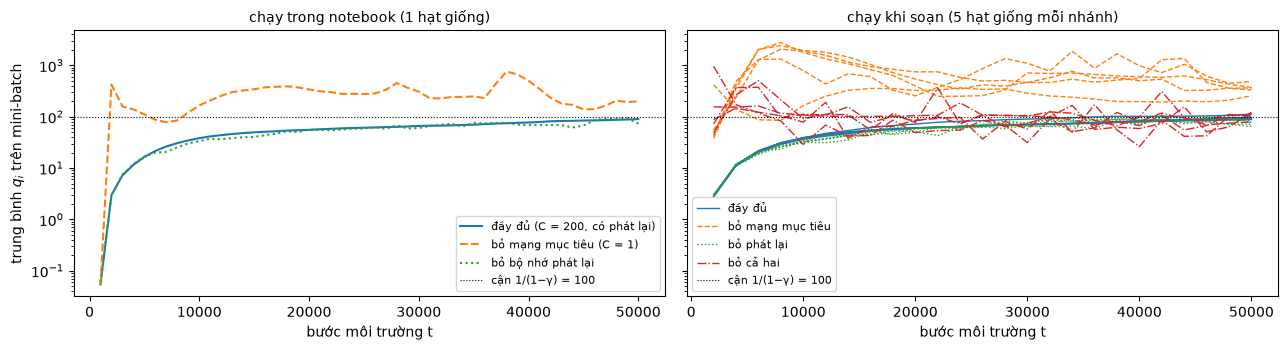

CartPole-v1 (tổng thưởng trên TEST_SEED; eps: đầu→cuối/tỉ lệ T)
  cấu hình                     T  F     C    h    b      eta             eps mất mát phát lại  n         TB ± SE  giây  từng hạt giống | mốc tốt nhất
  abl_C1                   50000  1     1   64   64  1.0e-03      1→0.05/0.2     mse       có  5    466.9 ± 32.0   137  [500.0, 500.0, 339.04, 498.24, 497.44] | [500.0, 500.0, 341.14, 500.0, 500.0]
  abl_both                 50000  1     1   64   64  1.0e-03      1→0.05/0.2     mse    không  5    456.4 ± 43.6   132  [500.0, 500.0, 281.94, 500.0, 500.0] | [500.0, 496.29, 500.0, 500.0, 500.0]
  abl_norep                50000  1   200   64   64  1.0e-03      1→0.05/0.2     mse    không  5    311.3 ± 59.9   109  [269.21, 480.86, 174.52, 421.91, 210.09] | [393.04, 500.0, 458.56, 421.91, 500.0]
* e_h64C200                50000  1   200   64   64  1.0e-03      1→0.05/0.2     mse       có  6    457.9 ± 42.1    90  [500.0, 500.0, 500.0, 500.0, 500.0, 247.49] | [500.0, 500.0, 500.0, 50

In [28]:
env_id = "CartPole-v1"
abl_live = {"đầy đủ (C = 200, có phát lại)": log_cp}
nets_abl = {}
for name, over in [("bỏ mạng mục tiêu (C = 1)", dict(C=1)), ("bỏ bộ nhớ phát lại", dict(replay=False))]:
    q_a, log_a = train_dqn(env_id, dict(CFG[env_id], **over))
    abl_live[name], nets_abl[name] = log_a, q_a
    print(f"{name:<32} {log_a['train_secs']:.0f} giây | q trung bình lớn nhất {log_a['qmean'].max():8.1f}")
res_abl = final_report(env_id, {"DQN đầy đủ": q_cp, **nets_abl})

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
styles = {"e_h64C200": ("-", "đầy đủ"), "abl_C1": ("--", "bỏ mạng mục tiêu"), "abl_norep": (":", "bỏ phát lại"),
          "abl_both": ("-.", "bỏ cả hai")}
for (name, log), ls in zip(abl_live.items(), ["-", "--", ":"]):
    axes[0].plot(log["loss_t"], np.maximum(log["qmean"], 1e-2), ls=ls, label=name)   # trục log: chặn dưới 0,01
for key, (ls, lab) in styles.items():
    ts, curves = ABL_Q[key]
    for j, c in enumerate(curves):
        axes[1].plot(ts, np.maximum(c, 1e-2), ls=ls, lw=1, color=f"C{list(styles).index(key)}", label=lab if j == 0 else None)
for ax, title in [(axes[0], "chạy trong notebook (1 hạt giống)"), (axes[1], "chạy khi soạn (5 hạt giống mỗi nhánh)")]:
    ax.axhline(1 / (1 - GAMMA), color="k", lw=0.8, ls=":", label="cận 1/(1−γ) = 100")
    ax.set_yscale("log"); ax.set_xlabel("bước môi trường t"); ax.set_title(title, fontsize=10); ax.legend(fontsize=8)
axes[0].set_ylabel("trung bình $q_i$ trên mini-batch")
fig.tight_layout(); plt.show()
for env_id in ["CartPole-v1", "LunarLander-v3"]:
    show_prelim(env_id, ablation=True); print()

# So sánh ghép cặp trên các hạt giống chung (dữ liệu khi soạn): d_s = điểm(đầy đủ) - điểm(nhánh), cùng hạt giống s
T_CRIT = {2: 4.303, 4: 2.776}                                  # phân vị 0,975 của Student với df = 2 và df = 4
rows = {env: {r[0]: r[13] for r in PRELIM[env]} for env in PRELIM}
for env_id, branches in [("CartPole-v1", ["abl_C1", "abl_norep", "abl_both"]), ("LunarLander-v3", ["abl_C1", "abl_norep"])]:
    full = np.array(rows[env_id][CHOSEN[env_id]])
    for br in branches:
        g = np.array(rows[env_id][br]); d = full[:len(g)] - g          # hạt giống 1..n dùng chung
        se = d.std(ddof=1) / np.sqrt(len(d)); t_stat = d.mean() / se; df = len(d) - 1
        print(f"{env_id:<15} đầy đủ - {br:<10} d = {np.round(d, 1).tolist()} | trung bình {d.mean():7.1f}, SE {se:5.1f}, "
              f"t = {t_stat:5.2f}, df = {df}, |t| > {T_CRIT[df]}: {'có' if abs(t_stat) > T_CRIT[df] else 'không'} | "
              f"max q_i theo hạt giống {QMAX[(env_id, br)]}")

**Đọc kết quả.** Kết luận dưới đây dựa trên dòng so sánh ghép cặp (dữ liệu khi soạn, một luồng CPU, hạt giống $1$–$5$ với CartPole và $1$–$3$ với Lunar Lander); lần chạy trong notebook chỉ là một hạt giống với hai luồng. Hiệu $d_s$ là điểm của cấu hình đầy đủ trừ điểm của nhánh, trên cùng hạt giống $s$, và $t=\bar d/\mathrm{SE}(d)$ được so với phân vị $0{,}975$ của phân phối Student.

- **Bỏ bộ nhớ phát lại** làm giảm tổng thưởng của chính sách cuối, và hiệu ghép cặp phân biệt được: trên CartPole, $\bar d=188{,}7$, $\mathrm{SE}=59{,}9$, $t=3{,}15>2{,}776$ ($\mathrm{df}=4$); trên Lunar Lander, $\bar d=402{,}7$, $\mathrm{SE}=29{,}2$, $t=13{,}8>4{,}303$ ($\mathrm{df}=2$), và cả ba hạt giống cho tổng thưởng âm. Với $b$ mẫu liền nhau, mỗi mini-batch là một đoạn quỹ đạo ngắn, đúng dòng thứ nhất của bảng trong Nhận xét 08.19 (Ví dụ 08.9).
- **Bỏ mạng mục tiêu**, và **bỏ cả hai**, không phân biệt được với cấu hình đầy đủ qua tổng thưởng của chính sách cuối: trên CartPole, $\bar d=33{,}1$ ($t=1{,}03$) và $\bar d=43{,}6$ ($t=1{,}00$); trên Lunar Lander, $\bar d=59{,}1$ ($t=0{,}80$, $\mathrm{df}=2$). Ở CartPole, bốn trong năm hạt giống của mỗi nhánh vẫn đạt từ $497$ trở lên.
- Mỗi dòng là một kiểm định riêng ở mức $5\%$ với ít hạt giống, không hiệu chỉnh cho nhiều phép so sánh, và hiệu trên CartPole bị chặn bởi trần $500$. Với hiệu chỉnh Bonferroni cho năm phép so sánh (ngưỡng $t_{0{,}995}$: $4{,}604$ với $\mathrm{df}=4$, $9{,}925$ với $\mathrm{df}=2$), kết luận về bộ nhớ phát lại còn đứng trên Lunar Lander ($t=13{,}77$) nhưng không còn trên CartPole ($t=3{,}15$); kết luận trên CartPole vì vậy yếu hơn.
- Độ lớn của $Q_\theta$ thì phân biệt được trên CartPole. Bỏ mạng mục tiêu làm giá trị lớn nhất của trung bình $q_i$ vượt cận $1/(1-\gamma)=100$ ở cả năm hạt giống, từ $421{,}6$ tới $2796{,}1$; bỏ cả hai cho $190{,}5$ tới $962{,}7$; cấu hình đầy đủ cho $87{,}9$ tới $112{,}1$. Chính sách tham lam chỉ phụ thuộc thứ tự của $Q_\theta(o,\cdot)$, nên giá trị sai về độ lớn vẫn có thể cho hành động đúng; giá trị đó không còn là ước lượng của $q_*$.

Lần chạy trong notebook (hạt giống $1$, hai luồng; con số có thể khác theo máy và phiên bản gói) cho tổng thưởng $289{,}2$ khi bỏ mạng mục tiêu và $192{,}6$ khi bỏ bộ nhớ phát lại, với cấu hình đầy đủ đạt $500$; một hạt giống không đủ để kết luận, nên các kết luận ở trên chỉ dựa trên bảng. Ghi chú dẫn Mnih và cộng sự (2015, Extended Data Table 3): trên năm trò chơi Atari, tổ hợp dùng cả hai cơ chế cho điểm cao nhất. Số liệu ở đây cùng chiều với kết luận đó đối với bộ nhớ phát lại, với số hạt giống nhỏ và chỉ trên hai môi trường.

## 12. Đối chiếu với lý thuyết

**Bộ ba bất ổn và phạm vi bảo đảm.** Cả ba lần huấn luyện ở mục 7–9 có đủ ba yếu tố của Định nghĩa 07.38: xấp xỉ hàm bằng mạng $Q_\theta$ có tham số dùng chung; bootstrap, vì $y_i$ chứa $\max_{a'}Q_{\theta^-}(O'_i,a')$; học khác chính sách, vì mục tiêu đánh giá chính sách tham lam trong khi $\mathcal D$ chứa dữ liệu của hành vi $\epsilon_{\mathrm{exp}}$-tham lam ở nhiều phiên bản $\theta$ cũ. Theo Nhận xét 08.21, Thuật toán 08.13 vì vậy không có bảo đảm hội tụ tổng quát. Số liệu của notebook phù hợp với kết luận đó mà không chứng minh nó: đường kiểm định không đơn điệu, kết quả phân tán giữa các hạt giống (Flappy Bird: $4{,}3$ tới $46{,}6$ ống với cùng cấu hình), và huấn luyện lâu hơn có thể làm chính sách cuối kém đi (Lunar Lander, cấu hình `f_zooF1_T150k`). Nhận xét 07.39 phân biệt "có thể phân kỳ" với "một lần chạy phân kỳ". Trong các lần chạy khi soạn của ba cấu hình được chọn, giá trị lớn nhất theo $t$ của trung bình $q_i$ là $87{,}9$–$112{,}1$ (CartPole), $46{,}3$–$71{,}4$ (Lunar Lander) và $7{,}7$–$11{,}1$ (Flappy Bird), theo bảng `QMAX` ở mục 10: giá trị không tăng không chặn, và kết quả kém là chính sách kém với giá trị bị chặn, một hiện tượng khác.

**Dữ liệu khác chính sách và Mệnh đề 08.8.** Mệnh đề 08.8 cho biết mục tiêu một bước có cùng kỳ vọng có điều kiện dù mẫu do phiên bản hành vi nào sinh ra, với hai giả thiết quyết định: quan sát đủ Markov và động lực không đổi theo thời gian. Ở CartPole, hai giả thiết thỏa (mục 2). Ở Flappy Bird, giả thiết thứ nhất thỏa gần đúng. Ở Lunar Lander, quan sát thiếu độ cao địa hình và trạng thái khớp chân. Như đoạn sau chứng minh Mệnh đề 08.8 trong ghi chú, khi bỏ giả thiết Markov, cùng một quan sát $o$ ứng với nhiều trạng thái ẩn với tỉ lệ phụ thuộc hành vi đã đưa tác tử tới $o$; mẫu của hai phiên bản hành vi khác nhau trong $\mathcal D$ vì vậy có kỳ vọng mục tiêu khác nhau, và kết luận của mệnh đề chỉ đúng gần đúng. Ảnh hưởng của điều này lên giá trị và chính sách học được không được thí nghiệm ở đây tách riêng.

**Mạng mục tiêu và cận của giá trị.** Ở CartPole, giá trị đúng của mọi cặp không vượt $1/(1-\gamma)=100$. Với $C=200$, giá trị lớn nhất của trung bình $q_i$ khi soạn nằm trong khoảng $87{,}9$–$112{,}1$, tức sát cận và có lúc vượt nhẹ. Với $C=1$, nó vượt cận ở cả năm hạt giống, từ $421{,}6$ tới $2796{,}1$, rồi giảm về vài trăm ở cuối lần chạy. Đây là tình huống của dòng thứ hai trong bảng của Nhận xét 08.19 và của Ví dụ 08.5: mục tiêu chứa chính tham số vừa cập nhật, nên mỗi bước kéo $q_i$ lên cũng kéo mục tiêu lên. Ví dụ 08.24 cho thấy mạng mục tiêu không ngăn được phân kỳ trong một phản ví dụ có hướng phân kỳ; ở CartPole, nó giữ giá trị gần miền đúng trong suốt $50\,000$ bước khi soạn. Tổng thưởng của chính sách cuối không phân biệt được hai cấu hình (mục 11).

**Bộ nhớ phát lại.** Bỏ bộ nhớ phát lại làm mỗi mini-batch thành một đoạn quỹ đạo liền nhau, đúng dòng thứ nhất của bảng trong Nhận xét 08.19. So sánh ghép cặp ở mục 11 phân biệt được nhánh này ở cả hai môi trường; ở Lunar Lander, cả ba hạt giống cho tổng thưởng âm, thấp hơn chính sách ngẫu nhiên. Mnih và cộng sự (2015, Extended Data Table 3) báo kết quả cùng chiều trên năm trò chơi Atari. Bộ nhớ phát lại không bỏ yếu tố học khác chính sách; nó thêm một nguồn, vì mẫu cũ do các phiên bản $\theta$ trước sinh ra.

**Chính sách cuối và mốc tốt nhất.** Thuật toán 08.13 trả chính sách tham lam tại $t=T$. Giữ mốc kiểm định tốt nhất là một bước chọn mô hình nằm ngoài thuật toán: thuật toán chạy đủ $T$ bước, sau đó chính sách được chọn lại theo `VALID_SEED`; bước này khác tiêu chuẩn dừng sớm theo ngưỡng mà ghi chú nêu. Ở Flappy Bird, nó nâng trung bình sáu hạt giống từ $25{,}9$ lên $36{,}8$ ống trên `TEST_SEED`. Ở Lunar Lander, nó không giúp: mốc tốt nhất trên $10$ lượt kiểm định có khi kém chính sách cuối trên $100$ lượt kiểm tra, vì SE của một mốc cỡ $30$. Bước chọn này có chi phí riêng (thêm lượt đánh giá) và chỉ đáng tin khi tập kiểm định đủ lớn so với độ biến thiên của lợi tức.

**Kết thúc và cắt ngắn.** Mặt nạ chỉ dùng $Z$ (Định nghĩa 08.4, 08.6). Ở CartPole, chính sách tốt có mọi lượt bị cắt ngắn ở $500$ bước. Nếu mặt nạ gộp cả $U$, mỗi lượt thành công kết thúc bằng một mẫu có mục tiêu $1$ thay cho khoảng $1+0{,}99\cdot100\approx100$. Quan sát không chứa thời gian đã trôi qua, nên quan sát ở bước $500$ giống các quan sát giữa lượt; mạng vì vậy hạ giá trị của cả những quan sát giữa lượt tương tự, như Ví dụ 08.8 mô tả. Ô kiểm tra ở mục 5 tính đúng sai lệch này trên số liệu của Ví dụ 08.8.

## 13. Tổng kết

Thuật toán 08.13 được cài đặt trong khoảng $110$ dòng mã PyTorch (bốn ô mã của mục 4–6, không tính dòng trống, dòng chú thích và các phép kiểm), và từng phần được kiểm bằng số liệu của ghi chú: bộ đệm vòng theo Ví dụ 08.10; mục tiêu, hàm mất mát và gradient theo Bài tập 08.1 cùng Ví dụ 08.13 ($y=(4{,}6;-2)$, $L_B=1{,}25$, gradient chỉ ở ô $(i,A_i)$); hai lỗi cài đặt theo Ví dụ 08.8 và Ví dụ 08.13; lịch hai bộ đếm theo Ví dụ 08.15. Cùng một hàm `train_dqn` được dùng cho ba môi trường, chỉ đổi cấu hình. Khi soạn, với ngân sách từ $50\,000$ tới $300\,000$ bước môi trường, DQN giữ cột đủ $500$ bước ở năm trong sáu hạt giống trên CartPole. Trên Lunar Lander, DQN đạt $208{,}6\pm18{,}4$, gần nhưng thường dưới bộ điều khiển viết tay ($236{,}9$). Trên Flappy Bird, DQN đạt $25{,}9\pm6{,}7$ ống với chính sách cuối và $36{,}8\pm5{,}0$ ống với mốc kiểm định tốt nhất; luật tay của Bài 07 đạt $34{,}3$ ống và luật tay với ngưỡng tốt nhất trong bốn ngưỡng đạt $42{,}5$. Cấu hình DQN được chọn trên chính `TEST_SEED`, nên các con số của DQN lạc quan. Thí nghiệm loại bỏ cho hai kết quả: bỏ bộ nhớ phát lại làm giảm tổng thưởng của chính sách cuối trên cả hai môi trường; bỏ mạng mục tiêu không làm tổng thưởng khác đi một cách phân biệt được, nhưng làm giá trị lớn nhất của trung bình $q_i$ trên CartPole lên $421{,}6$–$2796{,}1$, vượt cận $100$.

**Kết quả theo mục.** Mục 3: đánh giá trên $100$ lượt chung hạt giống, so sánh ghép cặp, bảy chính sách tham chiếu. Mục 4–5: mạng giá trị hành động, bộ nhớ phát lại, hàm `dqn_loss` với phép chọn theo hành động, phép dừng gradient và mặt nạ $1-Z$. Mục 6: hàm `train_dqn` với hai bộ đếm. Mục 7–9: ba lần huấn luyện, đường học, đánh giá cuối, trình phát, so sánh giá trị ước lượng với lợi tức thực tế. Mục 10–11: cấu hình đã thử và thí nghiệm loại bỏ.

**Công thức cần nhớ.** $y_i=R_i+\gamma(1-Z_i)\max_{a'}Q_{\theta^-}(O'_i,a')$ tính trong `torch.no_grad()`; $q_i$ lấy bằng `gather` theo $A_i$ đã lưu; $L_B=\tfrac1b\sum_i(y_i-q_i)^2$; cập nhật $\theta$, tăng $k_{\mathrm{opt}}$, rồi mới kiểm $k_{\mathrm{opt}}\bmod C=0$.

**Giả thiết hay bị quên.** Cờ cắt ngắn $U$ chỉ quyết định việc đặt lại môi trường; quan sát cuối phải được lưu trước khi đặt lại; lợi tức của lượt huấn luyện không đo chất lượng của chính sách đầu ra; một lần chạy không đủ để so hai cấu hình; chọn cấu hình trên tập kiểm tra làm kết quả trên tập đó lạc quan; Mệnh đề 08.8 cần quan sát đủ Markov.

In [29]:
print(f"Tổng thời gian chạy notebook: {time.time() - T_START:.0f} giây ({(time.time() - T_START) / 60:.1f} phút)")

Tổng thời gian chạy notebook: 566 giây (9.4 phút)


## 14. Gợi mở tìm hiểu và cải tiến

Mỗi nhiệm vụ nêu việc cần làm, gợi ý cách cài đặt và đại lượng cần đo. Khi so hai cấu hình, dùng ít nhất ba hạt giống tác tử, chọn cấu hình trên một tập hạt giống riêng và chỉ báo kết quả cuối trên `TEST_SEED`. Ô mã cuối mục có khung hàm cho nhiệm vụ 1, 3 và 4; ô đó chỉ kiểm cú pháp và kích thước, không huấn luyện.

1. **Double DQN** (Bài 09). Mục tiêu của Thuật toán 08.13 dùng cùng mạng $\theta^-$ để chọn và để đánh giá hành động tại $O'_i$. Double DQN chọn bằng mạng trực tuyến và đánh giá bằng mạng mục tiêu: $a^*_i=\arg\max_aQ_\theta(O'_i,a)$, $y_i=R_i+\gamma(1-Z_i)\,Q_{\theta^-}(O'_i,a^*_i)$, cả hai trong $\operatorname{sg}$. Hàm `dqn_loss_double` dưới cài đặt mục tiêu này; thêm tham số `loss_fn` cho `train_dqn` để thay `dqn_loss`. So với DQN trên Lunar Lander: tổng thưởng trên `TEST_SEED`, và độ lệch giữa $\max_aQ_\theta(O_t,a)$ với lợi tức chiết khấu thực tế $G_t$ tính từ cùng bước $t$ dọc các lượt đánh giá tham lam (hàm `plot_q_vs_return` của mục 7), theo cách đo của van Hasselt và cộng sự (2016).
2. **Hàm mất mát Huber.** Đặt `loss="huber"` trong cấu hình Lunar Lander, chạy ba hạt giống và so với bình phương. Trên CartPole, bảng ở mục 10 có cấu hình `f_huber` ($334{,}9\pm96{,}9$, không tốt hơn bình phương); nêu một lý do để kết quả trên Lunar Lander có thể khác, dựa trên độ lớn của sai số $\delta_i$ khi phần thưởng có giá trị $\pm100$.
3. **Cập nhật mềm của mạng mục tiêu.** Thay bước 9 bằng $\theta^-\leftarrow\tau\theta+(1-\tau)\theta^-$ sau mỗi bước tối ưu (hàm `soft_update`). Chọn $\tau$ sao cho "chu kỳ" $1/\tau$ bằng $C$ của cấu hình gốc, rồi đo lại trung bình $q_i$ của CartPole như mục 11.
4. **Quan sát không đủ Markov.** Bỏ hai vận tốc khỏi quan sát CartPole (lớp `DropVelocity`), huấn luyện DQN và so với quan sát đầy đủ; sau đó chồng hai quan sát liên tiếp (`FrameStackObservation` của Gymnasium) như bốn khung của Atari (Nhận xét 08.2, Ví dụ 08.4). Môi trường mới cần một nhánh trong `make_env`, một mục trong từ điển `envs` và ít nhất một chính sách tham chiếu trong `REF_POLICIES` (ví dụ chọn đều) để `final_report` có mốc so sánh. Đo tổng thưởng của chính sách cuối với ba hạt giống cho mỗi biến thể.
5. **Tỉ lệ tái sử dụng mẫu $b/F$.** Theo Ví dụ 08.14, mỗi mẫu được rút trung bình $b/F$ lần. Với Flappy Bird, giữ $T$, $b$ và đổi $F\in\{1,2,4\}$; báo số ống trên `TEST_SEED` và thời gian chạy. Bảng mục 10 có hai điểm liên quan ($F=2$ ở các cấu hình `e_` và `l_`).
6. **Chọn cấu hình không thiên lệch.** Lặp lại một phần bảng của mục 10 cho Lunar Lander, nhưng chọn cấu hình bằng tổng thưởng trên $100$ lượt có hạt giống $50\,000+i$, rồi chỉ đánh giá cấu hình được chọn trên `TEST_SEED`. So con số này với số trong bảng.
7. **RMSprop.** Thuật toán của Mnih và cộng sự (2015) dùng RMSprop (Định nghĩa 08.17) với tốc độ học $2{,}5\cdot10^{-4}$. Sửa `make_optimizer` để chọn `torch.optim.RMSprop`, rồi so với Adam trên CartPole ở cùng $\eta$ và ở $\eta$ nhỏ hơn mười lần.
8. **Kích thước tập kiểm định.** Ở Lunar Lander, mốc tốt nhất trên $10$ lượt `VALID_SEED` không tốt hơn chính sách cuối. Tăng `N_VALID` lên $30$ và lặp lại; tính SE của một mốc trước và sau, và nêu cỡ tập kiểm định cần để phân biệt hai mốc cách nhau $30$ đơn vị tổng thưởng.

In [30]:
def dqn_loss_double(q_net, tgt_net, batch, gamma, loss="mse"):
    # Nhiệm vụ 1: chọn a* bằng mạng trực tuyến, đánh giá bằng mạng mục tiêu
    O, A, R, O2, Z, U = batch
    q = q_net(O).gather(1, A.unsqueeze(1)).squeeze(1)                       # (b,)
    with torch.no_grad():
        a_star = q_net(O2).argmax(dim=1, keepdim=True)                        # (b, 1)
        y = R + gamma * (1.0 - Z) * tgt_net(O2).gather(1, a_star).squeeze(1)  # (b,)
    L = ((y - q) ** 2).mean() if loss == "mse" else nn.functional.smooth_l1_loss(q, y)
    return L, q.detach(), y


def soft_update(tgt_net, q_net, tau):
    # Nhiệm vụ 3: theta^- <- tau * theta + (1 - tau) * theta^-
    with torch.no_grad():
        for p_t, p in zip(tgt_net.parameters(), q_net.parameters()):
            p_t.mul_(1.0 - tau).add_(tau * p)


class DropVelocity(gym.ObservationWrapper):
    # Nhiệm vụ 4: CartPole chỉ quan sát (x, phi)
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(env.observation_space.low[[0, 2]], env.observation_space.high[[0, 2]],
                                                dtype=np.float32)

    def observation(self, o):
        return o[[0, 2]]


# Kiểm trên mini-batch của mục 5: tại O'_1, mạng trực tuyến chọn a* = a_2 (giá trị 3,1),
# mạng mục tiêu đánh giá a_2 bằng 1, nên y_1 = 1 + 0,9 * 1 = 1,9; mẫu 2 kết thúc nên y_2 = -2 như trước
L_d, q_d, y_d = dqn_loss_double(q_lin, t_lin, batch, gamma=0.9)
print("Double DQN trên mini-batch mục 5: y =", y_d.numpy(), "| L_B =", round(L_d.item(), 4))
assert torch.allclose(y_d, torch.tensor([1.9, -2.0]))
env_pv = gym.wrappers.FlattenObservation(gym.wrappers.FrameStackObservation(DropVelocity(gym.make("CartPole-v1")), 2))
o_pv, _ = env_pv.reset(seed=0)
print("CartPole bỏ vận tốc, chồng 2 quan sát: cỡ", o_pv.shape)
assert y_d.shape == (2,) and o_pv.shape == (4,)

Double DQN trên mini-batch mục 5: y = [ 1.9 -2. ] | L_B = 0.845
CartPole bỏ vận tốc, chồng 2 quan sát: cỡ (4,)


## 15. Biến thể của DQN trên Lunar Lander và Flappy Bird

Mục 7–13 dùng Thuật toán 08.13 đúng như ghi chú, với một cấu hình cho mỗi môi trường. Các mục đó được giữ nguyên làm mốc, và các biến thể của DQN được thêm phía dưới: mục tiêu Double DQN (DDQN) của Bài 09; mạng dueling (dueling network), tách $Q_\theta$ thành một giá trị theo quan sát $V$ và một phần lợi thế (advantage) theo hành động; hàm mất mát Huber với cắt chuẩn gradient (gradient norm clipping); cập nhật mềm của mạng mục tiêu; lợi tức $n$ bước ($n$-step return); phát lại ưu tiên; tốc độ học giảm dần. Mỗi biến thể được so với cấu hình gốc trên cùng hạt giống. Các cấu hình được chọn trên một tập hạt giống riêng, và chỉ cấu hình được chọn mới được đánh giá trên `TEST_SEED`, để tránh thiên lệch chọn cấu hình đã nêu ở mục 10. Mục 15 thực hiện một phần các nhiệm vụ 1, 2, 3 và 6 của mục 14 trên hai môi trường, bằng cách so tổng thưởng của chính sách cuối; phép đo $\max_aQ_\theta-G_t$ của nhiệm vụ 1 và phép đo $q_i$ trên CartPole của nhiệm vụ 3 chưa được làm, còn các nhiệm vụ 4, 5, 7 và 8 vẫn để mở.

Mục 15.1 tóm tắt các cấu hình đã công bố; mục 15.2 viết công thức và mã của các biến thể; mục 15.3 nêu quy trình chọn cấu hình; mục 15.4 và 15.5 báo kết quả trên hai môi trường; mục 15.6 tổng kết. Phần chạy trực tiếp mặc định là một lần huấn luyện trên Flappy Bird, khoảng $3$–$3{,}5$ phút trên CPU hai luồng khi soạn; lần huấn luyện Lunar Lander với ngân sách $300\,000$ bước (khoảng $11$ phút) chỉ chạy khi đặt `RUN_LUNAR_LONG = True` ở mục 15.4.

### 15.1. Các cấu hình đã công bố

Bảng dưới ghi các nguồn đã kiểm, kèm đường dẫn cố định theo mã commit hoặc thẻ mô hình. Kết quả của các nguồn được đo theo những cách khác nhau: một lần chạy hay nhiều hạt giống, chính sách cuối hay mốc tốt nhất, số lượt đánh giá khác nhau. Vì vậy các con số chỉ so được với nhau và với notebook này một cách gần đúng. Mọi kết quả về Lunar Lander của các nguồn là trên phiên bản `LunarLander-v2`. Ghi chú phiên bản của Gymnasium liệt kê ba thay đổi của `v3`: gió và nhiễu xoắn được đặt lại ở mỗi `reset`, một lỗi không tất định được sửa, và biên của không gian quan sát được mở rộng. Đọc mã nguồn cho thấy mã tính phần thưởng và động lực học không đổi khi tắt gió (mặc định, và cũng là thiết lập của notebook); các con số của `v2` vì vậy là mốc tham khảo gần đúng.

| Nguồn | Môi trường | Phương pháp và thay đổi | Ngân sách (bước môi trường) | Kết quả đã công bố, cách đo |
|---|---|---|---|---|
| RL Baselines3 Zoo, [`hyperparams/dqn.yml` dòng 58–71](https://github.com/DLR-RM/rl-baselines3-zoo/blob/b8a11d6e0e/hyperparams/dqn.yml#L58-L71) và [`benchmark.md`](https://github.com/DLR-RM/rl-baselines3-zoo/blob/b8a11d6e0e/benchmark.md) | Lunar Lander | DQN của Stable-Baselines3 (Huber, cắt chuẩn gradient $10$, đồng bộ cứng); hai tầng ẩn $256$ nút; $\eta=6{,}3\cdot10^{-4}$, $b=128$, $N=50\,000$, mạng mục tiêu cập nhật sau mỗi $250$ bước môi trường, $\epsilon_{\mathrm{exp}}$ giảm về $0{,}1$ trong $12\%$ đầu | $10^5$ | $154{,}4\pm79{,}2$ (trung bình ± sd trên $200$ lượt, một lần huấn luyện; tài liệu ghi rõ bảng không phải phép so sánh định lượng) |
| Thẻ mô hình [`sb3/dqn-LunarLander-v2`](https://huggingface.co/sb3/dqn-LunarLander-v2) | Lunar Lander | như dòng trên | $10^5$ | $136{,}8\pm42{,}7$ ($10$ lượt) |
| Thẻ mô hình [`araffin/dqn-LunarLander-v2`](https://huggingface.co/araffin/dqn-LunarLander-v2) | Lunar Lander | như trên, $\eta=7\cdot10^{-4}$, $N=100\,000$, $\epsilon_{\mathrm{exp}}$ giảm về $0{,}05$ trong $8\%$ đầu, $8$ môi trường song song; giữ mốc đánh giá tốt nhất | $5\cdot10^5$ | $280{,}2\pm13{,}0$ (mốc tốt nhất, một lần huấn luyện) |
| DI-engine, [`lunarlander_dqn_config.py`](https://github.com/opendilab/DI-engine/blob/d0b21d065b/dizoo/box2d/lunarlander/config/lunarlander_dqn_config.py) và thẻ [`OpenDILabCommunity/LunarLander-v2-DQN`](https://huggingface.co/OpenDILabCommunity/LunarLander-v2-DQN) | Lunar Lander | Double DQN + dueling + lợi tức $3$ bước; mạng $512$–$64$; $\eta=10^{-3}$, $b=64$, $N=100\,000$ | tối đa $2\cdot10^6$ theo lệnh huấn luyện trên thẻ | $221{,}8\pm81{,}5$ (thẻ không nêu cách tính con số này) |
| CleanRL, [`cleanrl/dqn.py`](https://github.com/vwxyzjn/cleanrl/blob/fe8d8a03c4/cleanrl/dqn.py) | (chỉ môi trường điều khiển cổ điển) | DQN với bình phương sai số, không cắt gradient, đồng bộ cứng sau $500$ bước | — | không có kết quả cho Lunar Lander |
| Gói [`flappy-bird-gymnasium`](https://github.com/markub3327/flappy-bird-gymnasium/blob/e7eb59e2a8/flappy_bird_gymnasium/envs/flappy_bird_env.py) 0.4.0 | Flappy Bird | kèm một mạng dueling DQN đã huấn luyện sẵn | không công bố | không có số liệu; mã huấn luyện và siêu tham số không được công bố |

Các biến thể đến từ các nguồn sau. Sutton và Barto (2018, chương 7) trình bày lợi tức $n$ bước; Hessel và cộng sự (2018) dẫn Sutton (1988) cho mục tiêu $n$ bước theo hướng thuận. Double DQN là của van Hasselt, Guez và Silver (2016); mạng dueling của Wang và cộng sự (2016); phát lại ưu tiên của Schaul và cộng sự (2016); cập nhật mềm của mạng mục tiêu được dùng trong DDPG (Lillicrap và cộng sự, 2016). Hessel và cộng sự (2018, Rainbow) ghép các thành phần này vào DQN, gồm cả lợi tức $n$ bước. Thí nghiệm loại bỏ của Rainbow bỏ từng thành phần khỏi Rainbow đầy đủ trên Atari. Kết quả ghi rằng phát lại ưu tiên và lợi tức $n$ bước là hai thành phần quan trọng nhất, còn bỏ mạng dueling không cho khác biệt đáng kể. Đó là kết quả trên Atari, đo bằng cách bỏ từng thành phần khỏi một tổ hợp; mục 15.4–15.5 thêm từng thành phần vào DQN gốc trên hai môi trường của notebook.

**Flappy Bird.** Không tìm được kết quả DQN đã công bố trên `flappy-bird-gymnasium` với quan sát $12$ chiều (`use_lidar=False`) mà vừa tái lập được, vừa báo trung bình trên các lượt kiểm tra. Các kho đã kiểm như sau.

- [`yenchenlin/DeepLearningFlappyBird`](https://github.com/yenchenlin/DeepLearningFlappyBird) học từ ảnh điểm ảnh trên một bản cài đặt trò chơi khác.
- [`chncyhn/flappybird-qlearning-bot`](https://github.com/chncyhn/flappybird-qlearning-bot) dùng Q-learning dạng bảng trên một bản cài đặt khác.
- [`samiuls25/rl_dqn_flappybird`](https://github.com/samiuls25/rl_dqn_flappybird) dùng quan sát LIDAR $180$ chiều và không công bố con số.
- [`johnnycode8/dqn_pytorch`](https://github.com/johnnycode8/dqn_pytorch/tree/24ccb030ed) dùng đúng môi trường này với Double DQN và dueling. Kho này chỉ thực hiện một bước gradient sau mỗi lượt, bỏ qua cờ cắt ngắn và báo lượt huấn luyện tốt nhất thay cho trung bình, nên không dùng làm mốc.

Mốc so sánh cho Flappy Bird vì vậy chỉ là luật tay của mục 3 và cấu hình gốc của mục 9.

**Lunar Lander.** Với cùng ngân sách $10^5$ bước như RL Zoo, cấu hình gốc của mục 8 đạt $208{,}6\pm18{,}4$ trên `TEST_SEED` với năm hạt giống (mục 10) và $187{,}3\pm21{,}6$ với tám hạt giống (mục 15.4). Hai nguồn có số cao hơn đều dùng nhiều dữ liệu hơn ($5\cdot10^5$ tới $2\cdot10^6$ bước), và nguồn của araffin báo mốc tốt nhất thay cho chính sách cuối.

### 15.2. Công thức của các biến thể

Mọi biến thể giữ khung của Thuật toán 08.13 (thu thập, lưu, rút mini-batch, bước tối ưu, đồng bộ); mỗi biến thể chỉ đổi một yếu tố. Ký hiệu như ghi chú Bài 08: mini-batch $B=\{(O_i,A_i,R_i,O'_i,Z_i,U_i)\}_{i=1}^b$, $q_i=[\mathbf q_\theta(O_i)]_{A_i}$, sai số TD $\delta_i=y_i-q_i$, và $L_B=\tfrac1b\sum_i\ell(\delta_i)$ với $\ell(x)=x^2$ ở các mục trước. Ghi chú Bài 09 viết trạng thái kế tiếp là $S'_i$; ở đây là quan sát $O'_i$, trùng $S'_i$ khi quan sát đủ Markov. Trong mục 15, $n$ chỉ số bước của lợi tức $n$ bước; số chiều của quan sát viết là `n_obs`.

**Double DQN.** *Giới hạn:* lấy cực đại trên các ước lượng có nhiễu cho mục tiêu thiên cao (ghi chú Bài 09, mục "Sai lệch cực đại và ví dụ Rademacher"). Mạng trực tuyến chọn hành động tại $O'_i$, mạng mục tiêu đánh giá hành động đó (ghi chú Bài 09, mục "Đích Double DQN"; van Hasselt và cộng sự, 2016):
$$a^*_i=\arg\max_{a\in\mathcal A}Q_\theta(O'_i,a),\qquad y_i=R_i+\gamma(1-Z_i)\operatorname{sg}\bigl(Q_{\theta^-}(O'_i,a^*_i)\bigr).$$
Khi $Z_i=1$, $y_i=R_i$ và giá trị của $a^*_i$ không được dùng. Trong mã, `q_net(O2).argmax(dim=1, keepdim=True)` là $a^*_i$, cỡ $(b,1)$; khi hòa, `argmax` lấy chỉ số nhỏ nhất. So với mục tiêu của Thuật toán 08.13, chỉ $\max_{a'}Q_{\theta^-}(O'_i,a')$ được thay bằng $Q_{\theta^-}(O'_i,a^*_i)$.

**Mạng dueling.** *Giới hạn:* mạng của mục 4 không tách phần giá trị chung cho mọi hành động tại $o$ khỏi phần khác nhau giữa các hành động; mỗi đầu ra $Q_\theta(o,a)$ phải chứa cả hai phần. Mạng dueling có một thân chung, rồi hai đầu ra: một số $V(o)$ và $\lvert\mathcal A\rvert$ số $\mathrm{Adv}(o,a)$ (Wang và cộng sự, 2016, phương trình 9):
$$Q_\theta(o,a)=V(o)+\mathrm{Adv}(o,a)-\frac1{\lvert\mathcal A\rvert}\sum_{a'}\mathrm{Adv}(o,a').$$
Từ công thức, $V(o)=\frac1{\lvert\mathcal A\rvert}\sum_aQ_\theta(o,a)$ là trung bình của $Q_\theta$ theo hành động tại quan sát $o$, không phải giá trị của chính sách tham lam. $Q_\theta$ chỉ xác định $V$ và phần lợi thế đã trừ trung bình; bản thân $\mathrm{Adv}$ chỉ xác định sai khác một hằng số. Thứ tự của $Q_\theta(o,\cdot)$ trùng thứ tự của $\mathrm{Adv}(o,\cdot)$. Lớp `DuelingQNet` trả cùng cỡ $(b,\lvert\mathcal A\rvert)$ như `QNet`, nên các hàm còn lại dùng được không đổi.

**Hàm mất mát Huber và cắt chuẩn gradient.** *Giới hạn:* với $\ell(\delta_i)=\delta_i^2$, gradient theo $q_i$ tỉ lệ với $\delta_i$, và phần thưởng của Lunar Lander đạt $\pm100$ ở cuối lượt. Với ngưỡng $\kappa=1$,
$$\ell_\kappa(\delta_i)=\begin{cases}\tfrac12\delta_i^2,&\lvert\delta_i\rvert<\kappa,\\ \kappa\bigl(\lvert\delta_i\rvert-\tfrac12\kappa\bigr),&\text{ngược lại},\end{cases}\qquad \frac{d\ell_\kappa}{d\delta_i}=\operatorname{clip}(\delta_i,-\kappa,\kappa).$$
So với bình phương, Huber giảm trọng số của các mẫu có $\lvert\delta_i\rvert>\kappa$ so với các mẫu có sai số nhỏ: đạo hàm theo $q_i$ của mẫu có sai số lớn bị chặn ở $\kappa$ thay cho tăng theo $\delta_i$. Ở vùng $\lvert\delta_i\rvert<\kappa$, gradient của $\tfrac12\delta_i^2$ bằng một nửa gradient của $\delta_i^2$; với SGD, điều đó tương đương giảm tốc độ học một nửa, nhưng với Adam, bước tham số gần như không đổi khi mọi gradient nhân cùng một hằng số (trừ ảnh hưởng của hằng $\varepsilon$ trong mẫu số). Cắt chuẩn gradient tác động lên độ lớn của cả vector gradient: nó thay $g=\nabla_\theta L_B$ bằng $g\cdot\min\bigl(c/(\lVert g\rVert_2+10^{-6}),1\bigr)$, với $c=10$ như mặc định của Stable-Baselines3 (`torch.nn.utils.clip_grad_norm_`).

**Cập nhật mềm.** *Giới hạn:* với đồng bộ cứng, $\theta^-$ nhảy tới $\theta$ mỗi $C$ bước tối ưu, và mục tiêu của mọi mẫu đổi cùng lúc tại mốc (Nhận xét 08.20). Cập nhật mềm thay bước 9 bằng $\theta^-\leftarrow\tau\theta+(1-\tau)\theta^-$ sau mỗi bước tối ưu (như DDPG; Lillicrap và cộng sự, 2016). Với $\tau=1/C$, $\theta^-$ là trung bình trượt của $\theta$ với độ dài nhớ cỡ $C$ bước tối ưu; mục 15.4–15.5 dùng $\tau=0{,}004=1/250$.

**Lợi tức $n$ bước.** *Giới hạn:* với mục tiêu một bước, một phần thưởng chỉ đi ngược một bước mỗi lần cập nhật; ở Flappy Bird, hình phạt $-1$ khi va chạm có thể đến nhiều bước sau hành động gây ra nó. Đây là một cách giải thích cho kết quả ở mục 15.5, chưa được thí nghiệm ở đây tách riêng. Với $k$ là số bước gom được, $1\le k\le n$ (Sutton và Barto, 2018, mục 7.1),
$$R^{(k)}_t=\sum_{j=0}^{k-1}\gamma^jR_{t+j+1},\qquad y=R^{(k)}_t+\gamma^k(1-Z)\max_{a'}Q_{\theta^-}(O_{t+k},a').$$
Cửa sổ dừng sớm khi gặp $Z=1$ hoặc $U=1$ ở bước $t+k\le t+n$. Khi $Z=1$, mục tiêu chỉ còn tổng phần thưởng. Khi $U=1$, mục tiêu vẫn bootstrap từ quan sát cuối $O_{t+k}$ với hệ số $\gamma^k$. Mỗi mẫu lưu thêm $\gamma^k$. Với dữ liệu $\epsilon_{\mathrm{exp}}$-tham lam lấy từ bộ nhớ, $R^{(k)}_t$ chứa phần thưởng của các hành động mà hành vi cũ đã chọn ở bước $t+1,\dots,t+k-1$, không phải của chính sách tham lam, nên mục tiêu lệch khi $n>1$ và lệch này không được hiệu chỉnh.

**Phát lại ưu tiên.** *Giới hạn:* rút đều cho mọi mẫu cùng xác suất, dù sai số TD của chúng khác nhau. Mẫu $i$ được rút với xác suất $P(i)=p_i^\alpha/\sum_{l}p_l^\alpha$, với $p_i=\lvert\delta_i\rvert+10^{-6}$ là sai số TD ở lần rút gần nhất; mẫu mới nhận độ ưu tiên lớn nhất hiện có. Hàm mất mát nhân từng số hạng với trọng số $w_i=\tilde w_i/\max_{j\in B}\tilde w_j$, trong đó $\tilde w_i=(\lvert\mathcal D\rvert P(i))^{-\beta}$, với $\alpha=0{,}6$ và $\beta$ tăng tuyến tính từ $0{,}4$ lên $1$ (Schaul và cộng sự, 2016). Bài báo dùng kèm tốc độ học nhỏ hơn bốn lần; ở đây $\eta$ được giữ nguyên để chỉ đổi một yếu tố.

**Tốc độ học giảm tuyến tính.** *Giới hạn:* ở mục 10, chính sách cuối có thể sụt ở các mốc muộn dù đã đạt mức cao trước đó. $\eta_t=\eta+(\eta_{\text{cuối}}-\eta)\,t/T$, với $\eta_{\text{cuối}}=\eta/10$, làm các bước tham số nhỏ dần về cuối lần huấn luyện.

**Phạm vi của Mệnh đề 08.8.** Trong các giả thiết và điều kiện áp dụng của mệnh đề, ba điều liên quan tới các biến thể: mục tiêu một bước với phép cực đại tính trọn tại $O'_i$, mẫu rút đều từ $\mathcal D$, và $O_t$ đủ Markov. Lợi tức $n$ bước với $n>1$ bỏ điều thứ nhất. Phát lại ưu tiên bỏ điều thứ hai; trọng số $w_i$ chỉ bù hoàn toàn cho phép rút không đều khi $\beta=1$. Điều thứ ba chỉ thỏa gần đúng ở Lunar Lander và Flappy Bird (mục 2). Double DQN thay phép cực đại trọn tại $O'_i$, nên kỳ vọng có điều kiện của mục tiêu là $\mathbb E\bigl[R+\gamma(1-Z)Q_{\theta^-}(O',\arg\max_aQ_\theta(O',a))\bigm|O_i,A_i\bigr]$ thay cho $(\mathcal TQ_{\theta^-})(O_i,A_i)$. Lập luận rằng kỳ vọng này không phụ thuộc hành vi đã sinh mẫu vẫn đi qua (với $\theta$, $\theta^-$ cố định), nhưng toán tử khác. Cả hai cấu hình chọn ở mục 15.4–15.5 đều dùng Double DQN và lợi tức $3$ bước.

| Ký hiệu | Biến trong mã | Cỡ |
|---|---|---|
| $a^*_i$ | `a_star` | $(b,1)$ |
| $V(o)$, $\mathrm{Adv}(o,\cdot)$ | `self.v(z)`, `self.a(z)` | $(b,1)$, $(b,\lvert\mathcal A\rvert)$ |
| $R^{(k)}_t$, $O_{t+k}$ (mẫu $n$ bước) | cột `R`, cột `O2` của bộ nhớ | $(N,)$ và (N, n_obs) trong bộ nhớ; $(b,)$ và (b, n_obs) trong mini-batch |
| $\gamma^k$ | `D.disc`; `disc` | $(N,)$ trong bộ nhớ; $(b,)$ trong mini-batch |
| $p_i$, $w_i$ | `D.prio`, `weights` | $(N,)$, $(b,)$ |
| $\kappa$, $c$, $\tau$, $n$, $\eta_{\text{cuối}}$ | `smooth_l1_loss` (mặc định $1$), `cfg["clip_norm"]`, `cfg["tau"]`, `cfg["n_step"]`, `cfg["lr_end"]` | vô hướng |

In [31]:
class DuelingQNet(nn.Module):
    # Q(o, a) = V(o) + Adv(o, a) - trung bình_a' Adv(o, a'): thân chung, hai đầu ra
    def __init__(self, n_obs, n_act, hidden=(128, 128)):
        super().__init__()
        layers, d = [], n_obs
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        self.body = nn.Sequential(*layers)
        self.v = nn.Linear(d, 1)                       # V(o), cỡ (b, 1)
        self.a = nn.Linear(d, n_act)                   # Adv(o, .), cỡ (b, |A|)

    def forward(self, o):
        z = self.body(o)
        adv = self.a(z)
        return self.v(z) + adv - adv.mean(dim=1, keepdim=True)


def make_qnet(n_obs, n_act, cfg):
    return (DuelingQNet if cfg.get("dueling") else QNet)(n_obs, n_act, cfg["hidden"])


class ReplayExt(Replay):
    # Bộ nhớ của mục 4 cộng hai mảng: gamma^k của mẫu n bước và độ ưu tiên p_i
    def __init__(self, N, n_obs):
        super().__init__(N, n_obs)
        self.disc = np.zeros(N, np.float32)
        self.prio = np.zeros(N, np.float64)
        self.max_prio = 1.0

    def add(self, o, a, r, o2, z, u, disc):
        self.disc[self.k] = disc
        self.prio[self.k] = self.max_prio              # mẫu mới nhận độ ưu tiên lớn nhất hiện có
        super().add(o, a, r, o2, z, u)

    def sample_per(self, b, rng, alpha, beta):
        p = self.prio[:self.size] ** alpha             # p_i^alpha
        c = np.cumsum(p)
        idx = np.searchsorted(c, rng.random(b) * c[-1], side="right").clip(0, self.size - 1)
        w = (self.size * p[idx] / c[-1]) ** (-beta)    # (|D| P(i))^(-beta)
        return idx, (w / w.max()).astype(np.float32)


class NStepBuffer:
    # Gom tối đa n bước của lượt hiện hành; xả mọi mẫu đang chờ khi Z = 1 hoặc U = 1
    def __init__(self, n, gamma):
        self.n, self.gamma, self.buf = n, gamma, []

    def push(self, o, a, r, o2, term, trunc):
        self.buf.append((o, a, r))
        out = []
        if term or trunc:                              # cửa sổ dừng ở bước cuối của lượt
            while self.buf:
                out.append(self._emit(o2, float(term), float(trunc)))
                self.buf.pop(0)
        elif len(self.buf) == self.n:
            out.append(self._emit(o2, 0.0, 0.0))
            self.buf.pop(0)
        return out

    def _emit(self, o2, z, u):
        G, g = 0.0, 1.0
        for (_, _, r) in self.buf:                     # R^(k) = sum_j gamma^j R_{t+j+1}
            G += g * r; g *= self.gamma
        o, a, _ = self.buf[0]
        return (o, a, G, o2, z, u, g)                  # g = gamma^k


def dqn_loss_ext(q_net, tgt_net, batch, disc, weights, cfg):
    O, A, R, O2, Z, U = batch
    q = q_net(O).gather(1, A.unsqueeze(1)).squeeze(1)                        # q_i, (b,)
    with torch.no_grad():                                                    # sg(.)
        if cfg.get("double"):
            a_star = q_net(O2).argmax(dim=1, keepdim=True)                   # a*_i theo mạng trực tuyến, (b, 1)
            boot = tgt_net(O2).gather(1, a_star).squeeze(1)                  # Q_{theta^-}(O'_i, a*_i), (b,)
        else:
            boot = tgt_net(O2).max(dim=1).values
        y = R + disc * (1.0 - Z) * boot                                      # disc = gamma^k
    per_sample = (y - q) ** 2 if cfg.get("loss", "mse") == "mse" else nn.functional.smooth_l1_loss(q, y, reduction="none")
    L = (per_sample * weights).mean() if weights is not None else per_sample.mean()
    return L, q.detach(), y, (y - q).detach()

**Kiểm tra bằng tính tay.** Ô mã dưới kiểm bốn điều.

- Ví dụ "Đối chiếu hai đích" của ghi chú Bài 09 (mục "Đích Double DQN"): $R=1$, $\gamma=0{,}9$, $Z=0$, $Q_{\theta^-}(o',\cdot)=(5;4)$, $Q_\theta(o',\cdot)=(3;6)$. DQN cho $y=1+0{,}9\cdot5=5{,}5$; Double DQN chọn hành động thứ hai theo mạng trực tuyến rồi đánh giá bằng mạng mục tiêu, $y=1+0{,}9\cdot4=4{,}6$. Với $Z=1$, cả hai cho $y=R=1$.
- Lợi tức $3$ bước trên một lượt $5$ bước với $R=1,2,3,4,5$, $\gamma=0{,}5$, kết thúc thật ở bước $5$. Mẫu từ $O_0$: $1+0{,}5\cdot2+0{,}25\cdot3=2{,}75$, bootstrap từ $O_3$ với $\gamma^3=0{,}125$. Mẫu từ $O_2$: $3+0{,}5\cdot4+0{,}25\cdot5=6{,}25$ với $Z=1$. Mẫu từ $O_4$: chỉ còn $R=5$, $k=1$, $Z=1$.
- Cùng lượt đó nhưng bị cắt ngắn ở bước $5$: mọi mẫu có $Z=0$, nên vẫn bootstrap; mẫu từ $O_3$ có $k=2$, $\gamma^2=0{,}25$.
- Đẳng thức dueling $Q=V+\mathrm{Adv}-\overline{\mathrm{Adv}}$ trên một mạng khởi tạo ngẫu nhiên.

In [32]:
# (1) Double DQN so với DQN: một quan sát, hai hành động; tầng tuyến tính không hệ số tự do cho đúng các giá trị Q
q_on, q_tg = nn.Linear(1, 2, bias=False), nn.Linear(1, 2, bias=False)
with torch.no_grad():
    q_on.weight.copy_(torch.tensor([[3.0], [6.0]]))     # Q_theta(o', .) = (3, 6)
    q_tg.weight.copy_(torch.tensor([[5.0], [4.0]]))     # Q_{theta^-}(o', .) = (5, 4)
o1 = torch.ones(1, 1)
b_cont = (o1, torch.tensor([0]), torch.tensor([1.0]), o1, torch.tensor([0.0]), torch.tensor([0.0]))   # Z = 0
b_term = (o1, torch.tensor([0]), torch.tensor([1.0]), o1, torch.tensor([1.0]), torch.tensor([0.0]))   # Z = 1
g09 = torch.tensor([0.9])
y_dqn = dqn_loss_ext(q_on, q_tg, b_cont, g09, None, {})[2].item()
y_dd = dqn_loss_ext(q_on, q_tg, b_cont, g09, None, {"double": True})[2].item()
print(f"y_DQN = {y_dqn:.2f}, y_Double = {y_dd:.2f}")
assert abs(y_dqn - 5.5) < 1e-5 and abs(y_dd - 4.6) < 1e-5
assert abs(dqn_loss_ext(q_on, q_tg, b_term, g09, None, {"double": True})[2].item() - 1.0) < 1e-6

# (2) Lợi tức 3 bước, gamma = 0,5, lượt 5 bước kết thúc thật (Z = 1) ở bước cuối
nb = NStepBuffer(3, 0.5); out = []
for t in range(5):
    out += nb.push(f"O{t}", t, float(t + 1), f"O{t + 1}", term=(t == 4), trunc=False)
for x in out:
    print(f"từ {x[0]}: R^(k) = {x[2]:5.2f}, bootstrap từ {x[3]}, gamma^k = {x[6]:.3f}, Z = {x[4]:.0f}, U = {x[5]:.0f}")
assert [x[0] for x in out] == ["O0", "O1", "O2", "O3", "O4"]
assert out[0][2] == 2.75 and out[0][3] == "O3" and out[0][6] == 0.125 and out[0][4] == 0.0
assert out[2][2] == 6.25 and out[2][3] == "O5" and out[2][4] == 1.0
assert out[4][2] == 5.0 and out[4][6] == 0.5 and out[4][4] == 1.0

# (3) Cùng lượt, bị cắt ngắn (U = 1) ở bước cuối: Z = 0 ở mọi mẫu, vẫn bootstrap với gamma^k
nb = NStepBuffer(3, 0.5); out_u = []
for t in range(5):
    out_u += nb.push(f"O{t}", t, float(t + 1), f"O{t + 1}", term=False, trunc=(t == 4))
assert all(x[4] == 0.0 for x in out_u) and out_u[3][5] == 1.0 and out_u[3][6] == 0.25

# (4) Đẳng thức dueling
net_d = DuelingQNet(4, 3, (8,)); o_r = torch.randn(5, 4)
z_r = net_d.body(o_r)
assert torch.allclose(net_d(o_r), net_d.v(z_r) + net_d.a(z_r) - net_d.a(z_r).mean(dim=1, keepdim=True))
print("Bốn phép kiểm đều đúng.")

y_DQN = 5.50, y_Double = 4.60
từ O0: R^(k) =  2.75, bootstrap từ O3, gamma^k = 0.125, Z = 0, U = 0
từ O1: R^(k) =  4.50, bootstrap từ O4, gamma^k = 0.125, Z = 0, U = 0
từ O2: R^(k) =  6.25, bootstrap từ O5, gamma^k = 0.125, Z = 1, U = 0
từ O3: R^(k) =  6.50, bootstrap từ O5, gamma^k = 0.250, Z = 1, U = 0
từ O4: R^(k) =  5.00, bootstrap từ O5, gamma^k = 0.500, Z = 1, U = 0
Bốn phép kiểm đều đúng.


**Hàm huấn luyện có biến thể.** `train_dqn_ext` có cùng vòng lặp, hai bộ đếm, mốc kiểm định và quy ước hạt giống như `train_dqn` của mục 6; hàm của mục 6 không đổi, nên các mục 7–14 vẫn cho cùng kết quả. Khác biệt nằm ở sáu chỗ. Mạng được tạo bằng `make_qnet`, nên có thể là mạng dueling. Bước 3 đi qua `NStepBuffer` khi $n>1$. Bước 5 rút theo độ ưu tiên khi bật phát lại ưu tiên. Bước 6–8 dùng `dqn_loss_ext`, cắt chuẩn gradient và đặt tốc độ học theo $t$. Bước 9 dùng cập nhật mềm khi có `tau`. Bản sao của mạng ở mốc kiểm định tốt nhất luôn được giữ (như `keep_best=True` ở mục 6). Cấu hình dùng các khóa của mục 7, cộng các khóa `double`, `dueling`, `loss`, `clip_norm`, `tau`, `n_step`, `per`, `lr_end`.

In [33]:
def train_dqn_ext(env_id, cfg, agent_seed=AGENT_SEED, train_seed=TRAIN_SEED, n_ckpt=10):
    torch.manual_seed(agent_seed)
    rng = np.random.default_rng(agent_seed)
    env, env_valid = make_env(env_id), make_env(env_id)
    n_obs, n_act = env.observation_space.shape[0], env.action_space.n
    q_net, tgt_net = make_qnet(n_obs, n_act, cfg), make_qnet(n_obs, n_act, cfg)
    tgt_net.load_state_dict(q_net.state_dict())
    opt = make_optimizer(q_net.parameters(), cfg)
    D = ReplayExt(cfg["N"], n_obs)
    T, b, F, C, N_start, gamma = cfg["T"], cfg["b"], cfg["F"], cfg["C"], cfg["N_start"], cfg["gamma"]
    n_step = cfg.get("n_step", 1)
    nbuf = NStepBuffer(n_step, gamma) if n_step > 1 else None
    ep = 0
    o, _ = env.reset(seed=train_seed + ep)
    t, k_opt, ep_ret, ep_len = 0, 0, 0.0, 0
    log = dict(ep_t=[], ep_ret=[], ep_len=[], ep_score=[], loss_t=[], loss=[], qmean=[],
               ckpt_t=[], ckpt_mean=[], ckpt_se=[], ckpt_score=[], ckpt_score_se=[])
    acc = [0.0, 0.0, 0]
    ckpts = {int(round(T * (j + 1) / n_ckpt)) for j in range(n_ckpt)}
    best_mean, best_net, t0 = -np.inf, None, time.time()
    while t < T:
        eps = linear_eps(t, T, cfg["eps_start"], cfg["eps_end"], cfg["eps_frac"])
        a = int(rng.integers(n_act)) if rng.random() < eps else greedy_action(q_net, o)   # bước 1
        o2, r, term, trunc, info = env.step(a)                                             # bước 2
        if nbuf is None:                                                                   # bước 3
            D.add(o, a, r, o2, float(term), float(trunc), gamma)
        else:
            for tr_ in nbuf.push(o, a, r, o2, term, trunc):
                D.add(*tr_)
        ep_ret += r; ep_len += 1
        if term or trunc:                                                                  # bước 4
            log["ep_t"].append(t + 1); log["ep_ret"].append(ep_ret); log["ep_len"].append(ep_len)
            log["ep_score"].append(info.get("score", np.nan))
            ep += 1; ep_ret, ep_len = 0.0, 0
            o, _ = env.reset(seed=train_seed + ep)
        else:
            o = o2
        t += 1
        if D.size >= N_start and t % F == 0:
            weights = None                                                                 # bước 5
            if cfg.get("per"):
                beta = 0.4 + 0.6 * min(1.0, t / T)
                idx, w = D.sample_per(b, rng, 0.6, beta); weights = torch.from_numpy(w)
            else:
                idx = rng.integers(0, D.size, size=b)
            L, q, _, td = dqn_loss_ext(q_net, tgt_net, D.batch(idx), torch.from_numpy(D.disc[idx]), weights, cfg)  # bước 6-7
            if cfg.get("lr_end") is not None:                                              # eta_t giảm tuyến tính
                for g_ in opt.param_groups:
                    g_["lr"] = cfg["lr"] + (cfg["lr_end"] - cfg["lr"]) * t / T
            opt.zero_grad(); L.backward()                                                  # bước 8
            if cfg.get("clip_norm"):
                nn.utils.clip_grad_norm_(q_net.parameters(), cfg["clip_norm"])
            opt.step()
            k_opt += 1
            if cfg.get("per"):                                                             # p_i = |delta_i| + 1e-6
                pr = np.abs(td.numpy()).astype(np.float64) + 1e-6
                D.prio[idx] = pr; D.max_prio = max(D.max_prio, float(pr.max()))
            if cfg.get("tau"):                                                             # bước 9, bản mềm
                with torch.no_grad():
                    for p_t, p in zip(tgt_net.parameters(), q_net.parameters()):
                        p_t.mul_(1.0 - cfg["tau"]).add_(cfg["tau"] * p)
            elif k_opt % C == 0:                                                           # bước 9
                tgt_net.load_state_dict(q_net.state_dict())
            acc[0] += float(L.detach()); acc[1] += float(q.mean()); acc[2] += 1
        if t % 1000 == 0 and acc[2]:
            log["loss_t"].append(t); log["loss"].append(acc[0] / acc[2]); log["qmean"].append(acc[1] / acc[2])
            acc = [0.0, 0.0, 0]
        if t in ckpts:                                                                     # mốc kiểm định
            res = evaluate_policy(env_valid, net_policy(q_net), N_VALID, VALID_SEED, gamma)
            log["ckpt_t"].append(t); log["ckpt_mean"].append(res["total"].mean())
            log["ckpt_se"].append(res["total"].std(ddof=1) / np.sqrt(N_VALID))
            log["ckpt_score"].append(res["score"].mean())
            log["ckpt_score_se"].append(res["score"].std(ddof=1) / np.sqrt(N_VALID))
            if res["total"].mean() > best_mean:
                best_mean, best_net = res["total"].mean(), copy.deepcopy(q_net)
                log["best_t"] = t
    log.update(k_opt=k_opt, n_episodes=ep, train_secs=time.time() - t0)
    log = {k: (np.array(v) if isinstance(v, list) else v) for k, v in log.items()}
    return q_net, log, best_net

### 15.3. Quy trình chọn cấu hình

Mục 10 đã nêu một thiên lệch: cấu hình của mục 7–9 được chọn bằng chính các con số trên `TEST_SEED`. Ở mục 15, ba tập hạt giống có ba vai trò tách rời. Mọi phép đánh giá dùng chính sách tham lam ($\epsilon=0$); hành vi trong lúc huấn luyện là $\epsilon_{\mathrm{exp}}$-tham lam.

| Tập | Hạt giống | Số lượt | Dùng để |
|---|---|---|---|
| `SEL_SEED` | $50\,000+i$ | $100$ | so các cấu hình với nhau và chọn cấu hình |
| `VALID_SEED` | $40\,000+i$ | $10$ mỗi mốc | chọn mốc kiểm định tốt nhất bên trong một lần huấn luyện (mục 9) |
| `TEST_SEED` | $30\,000+i$ | $100$ | đánh giá cấu hình đã chọn và cấu hình gốc |

**Các bước đã làm.** Mỗi biến thể đơn lẻ và mỗi tổ hợp được huấn luyện trước hết với ba hạt giống tác tử ($1$–$3$), cùng hạt giống của lượt huấn luyện như mục 10; mỗi lần chạy dùng một luồng CPU, mười hai lần chạy song song. Các cấu hình được thêm hạt giống như sau.

| Nhóm | Thêm hạt giống $4$–$5$ | Lý do |
|---|---|---|
| Lunar Lander, thay đổi đơn lẻ, $T=10^5$ | lợi tức $3$ bước; Double DQN | hiệu ghép cặp dương lớn nhất trên ba hạt giống đầu; Double DQN vì là nội dung của Bài 09 |
| Lunar Lander, tổ hợp, $T=10^5$ | không có | chọn theo phán đoán khi soạn: các cấu hình $T=3\cdot10^5$ đã cho trung bình cao hơn |
| Lunar Lander, $T=3\cdot10^5$ | cả ba cấu hình có tốc độ học giảm dần | chọn theo phán đoán khi soạn |
| Flappy Bird, thay đổi đơn lẻ | lợi tức $3$ bước | hiệu ghép cặp dương lớn nhất trên ba hạt giống đầu |
| Flappy Bird, tổ hợp | lợi tức $3$ bước + Double DQN; lợi tức $3$ bước + Double DQN + cập nhật mềm | chọn theo phán đoán khi soạn; lợi tức $3$ bước với $T=5\cdot10^5$ có hiệu lớn nhất ($+14{,}3$) nhưng dùng ngân sách lớn hơn và giữ ba hạt giống |
| cả hai môi trường | cấu hình gốc | để so ghép cặp trên mọi hạt giống |

Cấu hình chọn cho Lunar Lander là cấu hình có trung bình cao nhất và độ phân tán nhỏ nhất trên tập chọn sau ba hạt giống; cấu hình đó giữ nguyên vị trí sau khi thêm hạt giống $4$–$5$. Với Flappy Bird, lựa chọn được chốt khi các ứng viên có năm hạt giống. Sau đó, cấu hình chọn và cấu hình gốc của cả hai môi trường được thêm hạt giống $6$–$8$.

So sánh với cấu hình gốc dùng hiệu ghép cặp $d_s$ trên các hạt giống chung $s$, kèm $t=\bar d/\mathrm{SE}(d)$ và phân vị $0{,}975$ của Student: $4{,}303$ với $\mathrm{df}=2$, $2{,}776$ với $\mathrm{df}=4$, $2{,}365$ với $\mathrm{df}=7$. Mỗi phép so là một kiểm định riêng, không hiệu chỉnh cho nhiều phép so sánh. Có khoảng $20$ phép so với cấu hình gốc trên Lunar Lander và $15$ trên Flappy Bird. Với hiệu chỉnh Bonferroni cho $20$ phép so, các ngưỡng của $\lvert t\rvert$ là $19{,}96$ ($\mathrm{df}=2$), $6{,}76$ ($\mathrm{df}=4$) và $4{,}59$ ($\mathrm{df}=7$). Không hiệu nào trên tập chọn vượt các ngưỡng này, kể cả kết quả âm của phát lại ưu tiên ($t=-4{,}60$, $\mathrm{df}=2$) và hiệu của cấu hình chọn trên Lunar Lander ($t=3{,}51$, $\mathrm{df}=7$). 

**Hai lần xem `TEST_SEED`.** Kết quả trên `TEST_SEED` của hạt giống $1$–$5$ cho cấu hình gốc và cấu hình chọn của cả hai môi trường được tính trước khi huấn luyện hạt giống $6$–$8$. Hiệu ghép cặp khi đó là $+47{,}4$ với Lunar Lander ($t=2{,}08$) và $+14{,}1$ ống với Flappy Bird ($t=2{,}14$), cả hai dưới $2{,}776$ ($\mathrm{df}=4$). Hạt giống $6$–$8$ được thêm vì lần chạy hai luồng của cấu hình chọn trên Flappy Bird cho chính sách cuối $14{,}3$ ống trên tập chọn; cấu hình chọn không đổi. `TEST_SEED` vì vậy đã được xem hai lần. Với hiệu chỉnh Bonferroni cho hai lần xem, ngưỡng của $\lvert t\rvert$ với $\mathrm{df}=7$ là $2{,}84$. Hiệu của Lunar Lander trên tám hạt giống ($t=2{,}97$) vượt ngưỡng này, còn hiệu của Flappy Bird ($t=1{,}53$) thì không.

Ô mã dưới chứa kết quả chọn cấu hình, chạy ngoài notebook: với mỗi hạt giống, điểm của chính sách cuối, điểm của mốc kiểm định tốt nhất và giá trị lớn nhất theo $t$ của trung bình $q_i$. Ô mã cũng định nghĩa hai hàm in bảng và vẽ hình dùng cho mục 15.4–15.5. Các cột của bảng có nghĩa như sau.

- "cuối" là trung bình ± SE giữa các hạt giống của điểm chính sách cuối trên `SEL_SEED`.
- "mốc tốt nhất" là trung bình trên `SEL_SEED` của mạng ở mốc được chọn bằng `VALID_SEED`.
- "gốc (chung)" là trung bình của cấu hình gốc trên đúng các hạt giống chung; "Δ", "t", "df" là hiệu ghép cặp trên các hạt giống đó. Ở bảng $T=3\cdot10^5$ của Lunar Lander, hiệu so một cấu hình $T=3\cdot10^5$ với cấu hình gốc $T=10^5$.
- "q max" là khoảng từ nhỏ nhất đến lớn nhất giữa các hạt giống của $\max_t$ (trung bình $q_i$ trên mini-batch).
- "giây" là thời gian huấn luyện trung bình với một luồng khi mười hai lần chạy song song, lâu hơn khoảng $1{,}5$–$2$ lần so với một lần chạy hai luồng riêng lẻ.

In [34]:
SEL_SEED = 50_000
# Kết quả chọn cấu hình, chạy ngoài notebook (một luồng CPU, 12 lần chạy song song). Mỗi cấu hình: {hạt giống: (điểm chính sách cuối,
# điểm mốc kiểm định tốt nhất, max_t của trung bình q_i)} trên 100 lượt SEL_SEED; điểm = tổng thưởng (Lunar) hoặc số ống (Flappy).
# Thứ tự: (tên, mô tả thay đổi so với cấu hình gốc, T, giây huấn luyện trung bình, {hạt giống: (...)})
SEL_RESULTS = {
    "LunarLander-v3": [
        ("base", "cấu hình gốc", 100000, 281, {1: (199.8, 132.42, 71.4), 2: (152.67, 152.67, 46.3), 3: (191.36, 191.36, 52.7), 4: (244.3, 222.8, 70.0), 5: (238.97, 238.97, 63.7), 6: (233.99, 233.99, 72.8), 7: (141.49, 141.49, 21.9), 8: (71.43, 71.43, 64.4)}),
        ("T300k", "T 300 000", 300000, 949, {1: (248.73, 216.15, 83.8), 2: (200.61, 231.49, 74.6), 3: (197.44, 263.99, 81.3)}),
        ("T300k_lrdecay", "T 300 000, η → η/10", 300000, 855, {1: (249.21, 249.21, 66.1), 2: (270.73, 270.73, 79.0), 3: (234.84, 233.47, 77.6), 4: (216.65, 223.84, 83.9), 5: (264.07, 264.07, 76.6)}),
        ("ddqn", "Double DQN", 100000, 292, {1: (201.17, 201.17, 56.7), 2: (162.46, 182.43, 57.6), 3: (225.76, 225.76, 42.3), 4: (218.27, 184.57, 62.4), 5: (192.3, 233.89, 64.2)}),
        ("ddqn_lrdecay", "Double DQN, η → η/10", 100000, 307, {1: (-13.35, 15.11, 30.7), 2: (41.13, 27.1, 33.3), 3: (212.23, 202.51, 61.6)}),
        ("duel", "dueling", 100000, 316, {1: (151.28, 160.04, 63.1), 2: (224.59, 224.59, 67.6), 3: (199.9, 199.9, 61.7)}),
        ("huberclip", "Huber + cắt chuẩn 10", 100000, 326, {1: (187.54, 187.54, 41.7), 2: (138.3, 213.34, 32.5), 3: (219.86, 219.86, 24.8)}),
        ("lrdecay", "η giảm tuyến tính → η/10", 100000, 332, {1: (194.75, 194.75, 43.1), 2: (-7.06, 100.99, 39.2), 3: (-3.84, -17.87, 29.7)}),
        ("n3_T300k_lrdecay", "3 bước, T 300 000, η → η/10", 300000, 729, {1: (227.1, 257.97, 69.0), 2: (269.85, 269.85, 73.1), 3: (262.63, 262.63, 69.0), 4: (234.2, 240.32, 57.0), 5: (274.13, 273.13, 74.4)}),
        ("n3_ddqn", "3 bước + Double DQN", 100000, 362, {1: (247.17, 255.44, 55.3), 2: (126.83, 192.82, 41.4), 3: (211.82, 211.82, 50.1)}),
        ("n3_ddqn_T300k_lrdecay", "3 bước + Double DQN, T 300 000, η → η/10", 300000, 654, {1: (254.7, 255.32, 69.3), 2: (270.37, 261.71, 71.7), 3: (269.17, 261.23, 70.1), 4: (245.66, 255.67, 66.5), 5: (273.31, 276.01, 83.0), 6: (253.45, 253.45, 71.7), 7: (266.46, 273.9, 75.6), 8: (256.03, 271.77, 69.9)}),
        ("n3_ddqn_duel", "3 bước + Double DQN + dueling", 100000, 370, {1: (150.03, 150.03, 0.7), 2: (247.01, 247.01, 49.5), 3: (144.28, 211.26, 44.3)}),
        ("n3_ddqn_lrdecay", "3 bước + Double DQN, η → η/10", 100000, 358, {1: (179.4, 200.57, 38.0), 2: (-11.12, -11.12, -2.0), 3: (205.5, 227.08, 32.7)}),
        ("n3_duel", "3 bước + dueling", 100000, 324, {1: (116.39, 98.66, 21.6), 2: (226.29, 224.55, 43.3), 3: (234.29, 230.34, 50.2)}),
        ("n3_lrdecay", "3 bước, η → η/10", 100000, 300, {1: (163.53, 163.53, 17.8), 2: (167.86, 167.86, 38.5), 3: (180.37, 180.37, 8.4)}),
        ("nstep3", "3 bước", 100000, 300, {1: (239.19, 248.72, 55.7), 2: (217.85, 217.85, 40.7), 3: (228.58, 223.61, 56.9), 4: (101.31, 184.71, 36.4), 5: (19.16, 257.37, 35.5)}),
        ("per", "phát lại ưu tiên", 100000, 392, {1: (-16.49, -16.49, 116.1), 2: (19.11, 1.22, 77.7), 3: (85.05, 116.27, 97.4)}),
        ("soft", "cập nhật mềm τ = 0,004", 100000, 326, {1: (150.31, 198.94, 56.9), 2: (180.46, 153.36, 57.9), 3: (247.18, 247.18, 66.5)}),
        ("w256", "hai tầng ẩn 256 nút", 100000, 502, {1: (158.96, 158.96, 77.0), 2: (174.19, 174.19, 71.0), 3: (143.03, 133.05, 81.6)}),
        ("zoo", "RL Zoo: 256 nút, Huber, cắt 10, N_start 128", 100000, 583, {1: (-2.49, 199.55, 46.2), 2: (-205.0, 168.05, 66.1), 3: (154.9, 225.7, 49.4)}),
    ],
    "FlappyBird-v0": [
        ("base", "cấu hình gốc", 300000, 263, {1: (37.03, 37.03, 8.4), 2: (12.44, 38.83, 10.2), 3: (45.1, 47.3, 10.8), 4: (35.63, 45.2, 10.7), 5: (16.76, 12.77, 7.7), 6: (5.76, 42.33, 11.1), 7: (36.69, 36.69, 10.2), 8: (18.93, 36.14, 9.6)}),
        ("C1000", "C = 1000", 300000, 255, {1: (12.5, 32.56, 5.0), 2: (26.08, 40.48, 6.0), 3: (34.3, 34.3, 6.3)}),
        ("T500k", "T 500 000", 500000, 418, {1: (19.95, 48.82, 12.1), 2: (42.18, 46.51, 12.4), 3: (4.17, 43.69, 12.5)}),
        ("ddqn", "Double DQN", 300000, 304, {1: (37.89, 37.89, 8.2), 2: (42.14, 42.14, 10.4), 3: (39.33, 45.03, 9.9)}),
        ("duel", "dueling", 300000, 278, {1: (11.83, 39.52, 9.5), 2: (33.23, 45.42, 9.6), 3: (8.39, 8.39, 6.5)}),
        ("huberclip", "Huber + cắt chuẩn 10", 300000, 299, {1: (25.67, 25.67, 11.3), 2: (4.01, 20.1, 10.9), 3: (20.24, 20.24, 11.4)}),
        ("lrdecay", "η giảm tuyến tính → η/10", 300000, 234, {1: (8.74, 6.71, 6.8), 2: (29.63, 47.58, 10.5), 3: (33.51, 26.49, 10.0)}),
        ("n3_T500k", "3 bước, T 500 000", 500000, 328, {1: (44.53, 43.17, 12.0), 2: (47.75, 44.92, 12.5), 3: (45.22, 47.58, 12.1)}),
        ("n3_ddqn", "3 bước + Double DQN", 300000, 270, {1: (45.19, 45.19, 12.0), 2: (39.96, 39.96, 11.7), 3: (40.27, 41.99, 12.2), 4: (47.86, 47.86, 11.5), 5: (49.06, 49.06, 11.6), 6: (45.27, 45.27, 11.1), 7: (20.96, 36.11, 10.2), 8: (4.35, 25.56, 9.9)}),
        ("n3_ddqn_soft", "3 bước + Double DQN + cập nhật mềm", 300000, 258, {1: (38.53, 38.53, 11.4), 2: (47.56, 40.06, 11.7), 3: (42.64, 46.82, 11.8), 4: (37.72, 37.72, 11.2), 5: (48.72, 48.72, 11.1)}),
        ("n3_lrdecay", "3 bước, η → η/10", 300000, 224, {1: (19.66, 30.06, 9.6), 2: (27.35, 21.7, 10.2), 3: (29.38, 29.38, 10.9)}),
        ("n3_soft", "3 bước + cập nhật mềm", 300000, 246, {1: (48.81, 47.42, 11.8), 2: (47.86, 47.86, 11.9), 3: (7.24, 36.6, 11.4)}),
        ("nstep3", "3 bước", 300000, 272, {1: (49.55, 46.65, 12.3), 2: (47.93, 42.9, 12.4), 3: (43.33, 43.33, 11.7), 4: (45.94, 42.7, 11.2), 5: (31.44, 43.98, 11.9)}),
        ("nstep5", "5 bước", 300000, 267, {1: (4.37, 16.25, 8.7), 2: (44.95, 45.28, 11.8), 3: (46.91, 46.91, 11.4)}),
        ("per", "phát lại ưu tiên", 300000, 431, {1: (4.34, 38.86, 11.0), 2: (34.81, 42.25, 11.1), 3: (35.26, 42.95, 11.6)}),
        ("soft", "cập nhật mềm τ = 0,004", 300000, 276, {1: (38.37, 28.99, 9.6), 2: (37.47, 37.47, 10.5), 3: (42.12, 44.21, 10.8)}),
    ],
}
# TEST_SEED (đánh giá một lần, 100 lượt): {(môi trường, tên): {hạt giống: (điểm cuối, điểm mốc tốt nhất, tỉ lệ lượt bị cắt ngắn của chính sách cuối)}}
TEST_RESULTS = {
    ("LunarLander-v3", "base"): {1: (175.08, 147.22, 0.13), 2: (162.74, 162.74, 0.34), 3: (203.98, 203.98, 0.14), 4: (253.98, 220.8, 0.1), 5: (247.16, 247.16, 0.01), 6: (243.42, 243.42, 0.07), 7: (123.8, 123.8, 0.05), 8: (88.43, 88.43, 0.39)},
    ("LunarLander-v3", "n3_ddqn_T300k_lrdecay"): {1: (259.16, 251.94, 0.04), 2: (262.99, 261.71, 0.03), 3: (269.82, 263.17, 0.04), 4: (241.76, 256.55, 0.11), 5: (246.12, 282.22, 0.03), 6: (256.91, 256.91, 0.06), 7: (270.28, 278.11, 0.01), 8: (257.35, 276.04, 0.03)},
    ("FlappyBird-v0", "base"): {1: (38.87, 38.87, 0.58), 2: (16.42, 35.41, 0.17), 3: (46.63, 47.14, 0.86), 4: (33.94, 45.77, 0.42), 5: (15.29, 13.74, 0.08), 6: (4.3, 40.17, 0.0), 7: (36.83, 36.83, 0.56), 8: (18.35, 39.43, 0.1)},
    ("FlappyBird-v0", "n3_ddqn"): {1: (44.82, 44.82, 0.81), 2: (42.05, 42.05, 0.76), 3: (41.6, 41.54, 0.74), 4: (46.32, 46.32, 0.85), 5: (46.62, 46.62, 0.92), 6: (43.33, 43.33, 0.76), 7: (26.43, 35.15, 0.16), 8: (4.99, 27.8, 0.03)},
}
# Hiệu ghép cặp trên 100 lượt TEST_SEED giữa chính sách cuối của cấu hình chọn và chính sách tham chiếu: {hạt giống: (trung bình, 1,96·SE)}
PAIRED_REF = {
    ("LunarLander-v3", "điều khiển viết tay"): {1: (22.28, 19.4), 2: (26.1, 25.34), 3: (32.93, 19.65), 4: (4.87, 28.62), 5: (9.23, 30.12), 6: (20.02, 23.51), 7: (33.39, 18.31), 8: (20.46, 24.32)},
    ("FlappyBird-v0", "luật tay 0,02"): {1: (10.52, 3.04), 2: (7.75, 3.75), 3: (7.3, 3.79), 4: (12.02, 2.92), 5: (12.32, 3.01), 6: (9.03, 3.51), 7: (-7.87, 5.09), 8: (-29.31, 3.2)},
    ("FlappyBird-v0", "luật tay 0,04"): {1: (2.34, 3.19), 2: (-0.43, 3.67), 3: (-0.88, 3.57), 4: (3.84, 2.91), 5: (4.14, 3.08), 6: (0.85, 3.23), 7: (-16.05, 4.41), 8: (-37.49, 2.8)},
}
# Chính sách tham chiếu trên SEL_SEED (100 lượt): trung bình ± SE
REF_SEL = {"LunarLander-v3/random": (-193.5, 12.07), "LunarLander-v3/heuristic": (252.83, 7.35), "FlappyBird-v0/rule_thr0.02": (34.05, 1.29), "FlappyBird-v0/rule_thr0.04": (40.83, 1.16)}

BASE_LABEL = {"LunarLander-v3": "cấu hình gốc (mục 8)", "FlappyBird-v0": "cấu hình gốc (mục 9)"}
SHORT = {"base": "gốc", "ddqn": "DDQN", "duel": "dueling", "huberclip": "Huber+cắt", "soft": "mềm τ", "nstep3": "3 bước",
         "nstep5": "5 bước", "per": "ưu tiên", "w256": "256 nút", "zoo": "RL Zoo", "lrdecay": "η giảm", "T300k": "T 3e5",
         "T300k_lrdecay": "T 3e5, η giảm", "n3_T300k_lrdecay": "3 bước, T 3e5, η giảm",
         "n3_ddqn_T300k_lrdecay": "3 bước+DDQN,\nT 3e5, η giảm", "n3_ddqn": "3 bước+DDQN", "n3_ddqn_soft": "3 bước+DDQN\n+mềm",
         "n3_soft": "3 bước+mềm", "n3_T500k": "3 bước, T 5e5", "T500k": "T 5e5", "C1000": "C 1000"}


def show_sel(env_id, names, title):
    # Bảng trên SEL_SEED; Δ, t, df: hiệu ghép cặp với cấu hình gốc trên hạt giống chung
    rows = {r[0]: r for r in SEL_RESULTS[env_id]}
    base = rows["base"][4]
    print(f"{title} ({'ống' if env_id == 'FlappyBird-v0' else 'tổng thưởng'}, SEL_SEED)")
    print(f"  {'cấu hình':<44}{'n':>3}{'cuối':>16}{'mốc tốt nhất':>14}{'gốc (chung)':>13}{'Δ':>9}{'t':>7}{'df':>4}"
          f"{'q max':>16}{'giây':>6}")
    for nm in names:
        _, desc, T, secs, per = rows[nm]
        desc = BASE_LABEL[env_id] if nm == "base" else desc
        s = sorted(per); v = np.array([per[k][0] for k in s]); vb = np.array([per[k][1] for k in s])
        q = [per[k][2] for k in s]
        line = f"  {desc:<44}{len(v):>3}{f'{v.mean():.1f} ± {v.std(ddof=1) / np.sqrt(len(v)):.1f}':>16}{vb.mean():>14.1f}"
        sh = [k for k in s if k in base]
        if nm != "base" and len(sh) >= 2:
            d = np.array([per[k][0] - base[k][0] for k in sh]); se = d.std(ddof=1) / np.sqrt(len(d))
            line += f"{np.mean([base[k][0] for k in sh]):>13.1f}{d.mean():>+9.1f}{d.mean() / se:>7.2f}{len(d) - 1:>4}"
        else:
            line += f"{'':>13}{'':>9}{'':>7}{'':>4}"
        print(line + f"{f'từ {min(q):.0f} đến {max(q):.0f}':>16}{secs:>6}")


def plot_sel(env_id, names, title, ref=None):
    # Chấm: chính sách cuối của từng hạt giống; x: mốc kiểm định tốt nhất; vạch ngang: trung bình; ref: (tên, giá trị) trên SEL_SEED
    rows = {r[0]: r for r in SEL_RESULTS[env_id]}
    fig, ax = plt.subplots(figsize=(0.95 * len(names) + 2.5, 3.6))
    for j, nm in enumerate(names):
        per = rows[nm][4]; v = np.array([per[k][0] for k in sorted(per)]); vb = np.array([per[k][1] for k in sorted(per)])
        x = j + np.linspace(-0.18, 0.02, len(v))
        ax.plot(x, v, "o", color="C0", ms=5, label="chính sách cuối, từng hạt giống" if j == 0 else None)
        ax.plot(x + 0.14, vb, "x", color="C1", ms=5, label="mốc kiểm định tốt nhất" if j == 0 else None)
        ax.hlines(v.mean(), j - 0.25, j + 0.25, color="k", lw=2, label="trung bình (chính sách cuối)" if j == 0 else None)
    if ref is not None:
        ax.axhline(ref[1], color="0.4", ls="--", lw=1, label=f"{ref[0]} trên SEL_SEED")
    ax.set_xticks(range(len(names))); ax.set_xticklabels([SHORT[n] for n in names], fontsize=8)
    ax.set_ylabel("số ống" if env_id == "FlappyBird-v0" else "tổng thưởng"); ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0)); fig.tight_layout(); plt.show()   # chú giải ngoài vùng dữ liệu

### 15.4. Lunar Lander

Cấu hình gốc là cấu hình của mục 8 ($T=10^5$, $F=1$, $C=250$, $b=128$, $\eta=6{,}3\cdot10^{-4}$, hai tầng ẩn $128$ nút). Ô mã dưới in ba bảng trên tập chọn: các thay đổi đơn lẻ với cùng ngân sách $T=10^5$, các tổ hợp với cùng ngân sách, và các cấu hình với $T=3\cdot10^5$; hình vẽ từng hạt giống của các cấu hình chính.

Thay đổi đơn lẻ, T = 100 000 (tổng thưởng, SEL_SEED)
  cấu hình                                      n            cuối  mốc tốt nhất  gốc (chung)        Δ      t  df           q max  giây
  cấu hình gốc (mục 8)                          8    184.3 ± 21.1         173.1                                     từ 22 đến 73   281
  Double DQN                                    5    200.0 ± 11.1         205.6        205.4     -5.4  -0.38   4    từ 42 đến 64   292
  dueling                                       3    191.9 ± 21.5         194.8        181.3    +10.6   0.31   2    từ 62 đến 68   316
  Huber + cắt chuẩn 10                          3    181.9 ± 23.7         206.9        181.3     +0.6   0.04   2    từ 25 đến 42   326
  cập nhật mềm τ = 0,004                        3    192.7 ± 28.6         199.8        181.3    +11.4   0.36   2    từ 57 đến 66   326
  3 bước                                        5    161.2 ± 43.4         226.5        205.4    -44.2  -0.77   4    từ 36 đến 57   300
  

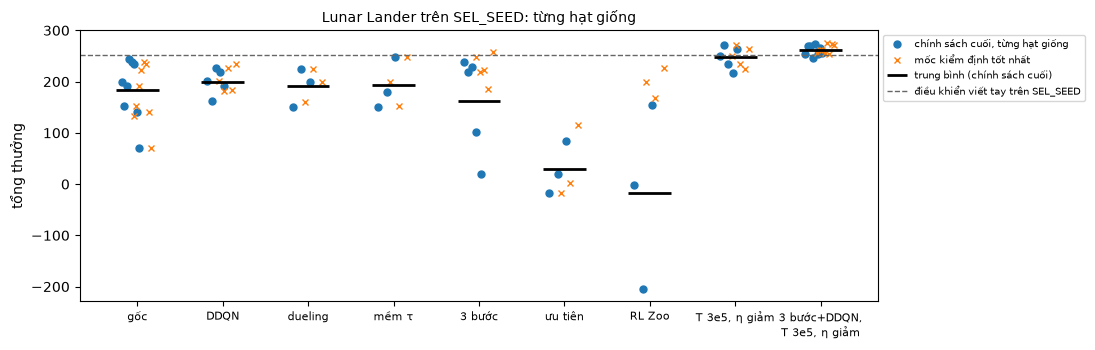

In [35]:
env_id = "LunarLander-v3"
show_sel(env_id, ["base", "ddqn", "duel", "huberclip", "soft", "nstep3", "per", "w256", "zoo", "lrdecay"],
         "Thay đổi đơn lẻ, T = 100 000")
show_sel(env_id, ["base", "n3_ddqn", "n3_duel", "n3_ddqn_duel", "ddqn_lrdecay", "n3_lrdecay", "n3_ddqn_lrdecay"],
         "Tổ hợp, T = 100 000")
show_sel(env_id, ["base", "T300k", "T300k_lrdecay", "n3_T300k_lrdecay", "n3_ddqn_T300k_lrdecay"],
         "Ngân sách T = 300 000 (cấu hình gốc dùng T = 100 000)")
print(f"Chính sách tham chiếu trên SEL_SEED: điều khiển viết tay {REF_SEL['LunarLander-v3/heuristic'][0]:.1f} ± "
      f"{REF_SEL['LunarLander-v3/heuristic'][1]:.1f}, ngẫu nhiên {REF_SEL['LunarLander-v3/random'][0]:.1f}")
plot_sel(env_id, ["base", "ddqn", "duel", "soft", "nstep3", "per", "zoo", "T300k_lrdecay", "n3_ddqn_T300k_lrdecay"],
         "Lunar Lander trên SEL_SEED: từng hạt giống", ref=("điều khiển viết tay", REF_SEL["LunarLander-v3/heuristic"][0]))

**Đọc kết quả.** Với cùng ngân sách $10^5$ bước, chỉ phát lại ưu tiên cho chính sách cuối khác cấu hình gốc vượt ngưỡng không hiệu chỉnh ($t=-4{,}60$); không hiệu nào vượt ngưỡng Bonferroni của mục 15.3. Double DQN cho $200{,}0$ trên năm hạt giống; trên đúng năm hạt giống đó cấu hình gốc đạt $205{,}4$, nên hiệu ghép cặp là $-5{,}4$ ($t=-0{,}38$). Trung bình $184{,}3$ của cấu hình gốc ở dòng đầu tính trên tám hạt giống. Dueling, Huber kèm cắt gradient và cập nhật mềm cho trung bình cao hơn cấu hình gốc từ $0{,}6$ tới $11{,}4$ trên ba hạt giống ($\lvert t\rvert<0{,}4$, chưa phân biệt được ở mức $5\%$). Năm kết quả âm; trong đó chỉ phát lại ưu tiên vượt ngưỡng không hiệu chỉnh, các hiệu còn lại chưa phân biệt được ở mức $5\%$:

- **Kết quả trên ba hạt giống đầu không bền khi thêm hạt giống.** Lợi tức $3$ bước cho $239{,}2$; $217{,}8$; $228{,}6$ ở hạt giống $1$–$3$ (hiệu ghép cặp $+47{,}3$, $t=5{,}26>4{,}303$). Hai hạt giống thêm vào cho $101{,}3$ và $19{,}2$, nên trung bình năm hạt giống là $161{,}2$, thấp hơn cấu hình gốc. Mốc kiểm định tốt nhất của cùng các lần chạy vẫn đạt $226{,}5$, nên chính sách tốt đã xuất hiện trong lúc huấn luyện rồi mất đi trước $t=T$.
- **Phát lại ưu tiên** cho trung bình $29{,}2$ ($t=-4{,}60$ với $\mathrm{df}=2$; không vượt ngưỡng Bonferroni của mục 15.3). Kết quả này nói về phát lại ưu tiên với tốc độ học của cấu hình gốc (mục 15.2).
- **Hai tầng ẩn $256$ nút**, như ba cấu hình của mục 15.1, cho $158{,}7$ và chạy lâu hơn ($502$ so với $281$ giây).
- **Cấu hình RL Zoo** dựng lại trong mã này ($256$ nút, Huber, cắt chuẩn $10$) cho chính sách cuối từ $-205{,}0$ tới $154{,}9$, trong khi mốc tốt nhất đạt $197{,}8$. Hai khác biệt còn lại so với RL Zoo (bốn bước gradient sau mỗi bốn bước môi trường thay cho một bước sau mỗi bước, và bắt đầu tối ưu từ đầu thay cho $N_{\mathrm{start}}=128$) không được thử riêng.
- **Tốc độ học giảm dần** về $\eta/10$ trong $10^5$ bước cho trung bình thấp hơn ($61{,}3$ trên ba hạt giống, $t=-2{,}06$, chưa phân biệt được ở mức $5\%$); với $T=3\cdot10^5$, kết quả theo chiều ngược lại (bảng thứ ba).

Với $T=3\cdot10^5$, trên đúng ba hạt giống chung, tốc độ học giảm dần cho trung bình $251{,}6$ so với $215{,}6$ khi giữ $\eta$ cố định. Hiệu ghép cặp là $+36{,}0$, $\mathrm{SE}=20{,}1$, $t=1{,}79<4{,}303$ với $\mathrm{df}=2$, nên chưa phân biệt được. Thêm lợi tức $3$ bước và Double DQN cho $261{,}1\pm3{,}5$ trên tám hạt giống, với mọi hạt giống từ $245{,}7$ trở lên. Hiệu ghép cặp với cấu hình gốc là $+76{,}9$ ($t=3{,}51$, $\mathrm{df}=7$). Hai cấu hình này khác nhau ở năm yếu tố cùng lúc: ngân sách $T$ gấp ba; lịch $\epsilon_{\mathrm{exp}}$ dài gấp ba (giảm trong $\rho T$ bước); tốc độ học giảm dần; lợi tức $3$ bước; Double DQN. Hiệu vì vậy gộp tác dụng của cả năm. Cấu hình chọn cho Lunar Lander là cấu hình cuối cùng này.

In [36]:
def show_test(env_id, chosen, ref_names, unit_key=0):
    # Kết quả một lần trên TEST_SEED: cấu hình gốc và cấu hình chọn, 8 hạt giống; hiệu ghép cặp với cấu hình gốc
    A, B = TEST_RESULTS[(env_id, chosen)], TEST_RESULTS[(env_id, "base")]
    s = sorted(A)
    for kind, j in [("chính sách cuối", 0), ("mốc kiểm định tốt nhất", 1)]:
        va, vb = np.array([A[k][j] for k in s]), np.array([B[k][j] for k in s])
        d = va - vb; se = d.std(ddof=1) / np.sqrt(len(d))
        print(f"{kind:<24} chọn {va.mean():7.2f} ± {va.std(ddof=1) / np.sqrt(len(va)):5.2f} | gốc {vb.mean():7.2f} ± "
              f"{vb.std(ddof=1) / np.sqrt(len(vb)):5.2f} | hiệu ghép cặp {d.mean():+7.2f} ± {se:5.2f}, t = {d.mean() / se:5.2f}, df = {len(d) - 1}")
        print(f"{'':<24} từng hạt giống, chọn: {np.round(va, 1).tolist()}")
    print(f"tỉ lệ lượt bị cắt ngắn của chính sách cuối: chọn {[A[k][2] for k in s]} (TB {np.mean([A[k][2] for k in s]):.2f}); "
          f"gốc {[B[k][2] for k in s]} (TB {np.mean([B[k][2] for k in s]):.2f})")
    for ref in ref_names:
        p = PAIRED_REF[(env_id, ref)]
        print(f"chọn − {ref}, từng hạt giống (trung bình ± 1,96 SE trên 100 lượt): "
              + ", ".join(f"{p[k][0]:+.1f} ± {p[k][1]:.1f}" for k in sorted(p)))


show_test("LunarLander-v3", "n3_ddqn_T300k_lrdecay", ["điều khiển viết tay"])

chính sách cuối          chọn  258.05 ±  3.59 | gốc  187.32 ± 21.55 | hiệu ghép cặp  +70.73 ± 23.82, t =  2.97, df = 7
                         từng hạt giống, chọn: [259.2, 263.0, 269.8, 241.8, 246.1, 256.9, 270.3, 257.4]
mốc kiểm định tốt nhất   chọn  265.83 ±  4.02 | gốc  179.69 ± 20.57 | hiệu ghép cặp  +86.14 ± 21.80, t =  3.95, df = 7
                         từng hạt giống, chọn: [251.9, 261.7, 263.2, 256.6, 282.2, 256.9, 278.1, 276.0]
tỉ lệ lượt bị cắt ngắn của chính sách cuối: chọn [0.04, 0.03, 0.04, 0.11, 0.03, 0.06, 0.01, 0.03] (TB 0.04); gốc [0.13, 0.34, 0.14, 0.1, 0.01, 0.07, 0.05, 0.39] (TB 0.15)
chọn − điều khiển viết tay, từng hạt giống (trung bình ± 1,96 SE trên 100 lượt): +22.3 ± 19.4, +26.1 ± 25.3, +32.9 ± 19.6, +4.9 ± 28.6, +9.2 ± 30.1, +20.0 ± 23.5, +33.4 ± 18.3, +20.5 ± 24.3


**Đọc kết quả trên `TEST_SEED`.** Cấu hình chọn đạt $258{,}1\pm3{,}6$ trên tám hạt giống, cấu hình gốc $187{,}3\pm21{,}6$; hiệu ghép cặp $+70{,}7\pm23{,}8$, $t=2{,}97$, vượt cả ngưỡng $2{,}365$ lẫn ngưỡng $2{,}84$ cho hai lần xem (mục 15.3).

So với bộ điều khiển viết tay ($236{,}9$ trên `TEST_SEED`), hiệu ghép cặp của từng hạt giống trên $100$ lượt dương ở cả tám hạt giống, từ $+4{,}9$ tới $+33{,}4$, với nửa độ rộng khoảng tin cậy $95\%$ từ $18$ tới $30$. Khoảng này không chứa $0$ ở hạt giống $1$, $2$, $3$, $7$ và chứa $0$ ở hạt giống $4$, $5$, $6$, $8$. Hai cách gộp tám hạt giống cho hai kết luận có phạm vi khác nhau.

- Coi tám hiệu là tám mẫu: trung bình $+21{,}2$, $t=5{,}89$ ($\mathrm{df}=7$). Phép kiểm này coi điểm trung bình của bộ điều khiển trên $100$ lượt `TEST_SEED` là hằng số, vì cả tám hiệu dùng chung $100$ lượt đó; kết luận chỉ đúng có điều kiện trên đúng $100$ lượt này.
- Lấy hiệu theo từng lượt, trung bình trên tám hạt giống rồi trên $100$ lượt: $+21{,}2$, $\mathrm{SE}=10{,}5$, $t=2{,}02$ ($p\approx0{,}05$), vừa vượt ngưỡng $1{,}984$ ($\mathrm{df}=99$). Phép kiểm này có điều kiện trên đúng tám mạng đã huấn luyện. Khi tính thêm độ biến thiên giữa các hạt giống, $t$ còn khoảng $1{,}95$–$1{,}98$: cộng hai nguồn nhiễu cho $\mathrm{SE}=10{,}7$, $t=1{,}98$; phân tích phương sai hai chiều (hạt giống × lượt) cho $\mathrm{SE}=10{,}8$, $t=1{,}95$, $p\approx0{,}05$. Giá trị này nằm sát ngưỡng, nên chưa đủ để kết luận về hiệu với bộ điều khiển viết tay như một phát biểu về môi trường.

Trên `SEL_SEED`, khoảng cách còn nhỏ hơn: $261{,}1$ so với $252{,}8$ của bộ điều khiển, hiệu $+8{,}3$. Trung bình của cấu hình chọn trên `TEST_SEED` thấp hơn trên tập chọn $3{,}1$ đơn vị, nhưng chênh lệch này không đo được thiên lệch chọn cấu hình, vì chính bộ điều khiển viết tay cũng khác nhau $16$ đơn vị giữa hai tập ($252{,}8$ và $236{,}9$).

**Chạy trực tiếp (tùy chọn).** Đặt `RUN_LUNAR_LONG = True` để huấn luyện cấu hình chọn với hạt giống `AGENT_SEED` (khoảng $11$ phút trên CPU hai luồng khi soạn), vẽ đường học, đánh giá trên `TEST_SEED` và mở trình phát. Khi để mặc định `False`, ô mã chỉ in cấu hình; các kết luận ở trên dựa trên bảng tám hạt giống.

In [37]:
RUN_LUNAR_LONG = False
CFG_LUNAR_EXT = dict(CFG["LunarLander-v3"], T=300_000, n_step=3, double=True, lr_end=6.3e-5)
print("Cấu hình chọn cho Lunar Lander:", {k: CFG_LUNAR_EXT[k] for k in ["T", "n_step", "double", "lr", "lr_end", "C", "b", "F"]})
if RUN_LUNAR_LONG:
    q_ll2, log_ll2, q_ll2_best = train_dqn_ext("LunarLander-v3", CFG_LUNAR_EXT)
    print(f"{log_ll2['train_secs']:.0f} giây | k_opt = {log_ll2['k_opt']} | mốc tốt nhất t = {log_ll2['best_t']}")
    plot_learning(log_ll2, f"Lunar Lander, 3 bước + Double DQN, T = {CFG_LUNAR_EXT['T']}")
    learned_ll2 = {"DQN mục 8": q_ll, "biến thể, cuối": q_ll2}
    if log_ll2["best_t"] != CFG_LUNAR_EXT["T"]:                 # mốc tốt nhất khác mốc cuối
        learned_ll2["biến thể, mốc tốt nhất"] = q_ll2_best
    res_ll2 = final_report("LunarLander-v3", learned_ll2)
    ep_ll2 = {"biến thể": record_episode(envs["LunarLander-v3"], net_policy(q_ll2), TEST_SEED, "lunar"),
              "DQN mục 8": ep_ll["DQN"], "điều khiển viết tay": episodes_ref["LunarLander-v3"]["điều khiển viết tay"]}
    display(player(ep_ll2))

Cấu hình chọn cho Lunar Lander: {'T': 300000, 'n_step': 3, 'double': True, 'lr': 0.00063, 'lr_end': 6.3e-05, 'C': 250, 'b': 128, 'F': 1}


### 15.5. Flappy Bird

Cấu hình gốc là cấu hình của mục 9 ($T=3\cdot10^5$, $F=4$, $C=250$, $b=64$, $\eta=5\cdot10^{-4}$, $\epsilon_{\mathrm{exp}}$ từ $0{,}1$ xuống $0{,}001$). Bảng đầu là các thay đổi đơn lẻ, bảng thứ hai là các tổ hợp quanh lợi tức $3$ bước.

Thay đổi đơn lẻ (ống, SEL_SEED)
  cấu hình                                      n            cuối  mốc tốt nhất  gốc (chung)        Δ      t  df           q max  giây
  cấu hình gốc (mục 9)                          8      26.0 ± 5.0          37.0                                      từ 8 đến 11   263
  Double DQN                                    3      39.8 ± 1.2          41.7         31.5     +8.3   0.76   2     từ 8 đến 10   304
  dueling                                       3      17.8 ± 7.8          31.1         31.5    -13.7  -0.78   2     từ 6 đến 10   278
  Huber + cắt chuẩn 10                          3      16.6 ± 6.5          22.0         31.5    -14.9  -2.94   2    từ 11 đến 11   299
  cập nhật mềm τ = 0,004                        3      39.3 ± 1.4          36.9         31.5     +7.8   0.90   2    từ 10 đến 11   276
  3 bước                                        5      43.6 ± 3.2          43.9         29.4    +14.2   2.36   4    từ 11 đến 12   272
  5 bước               

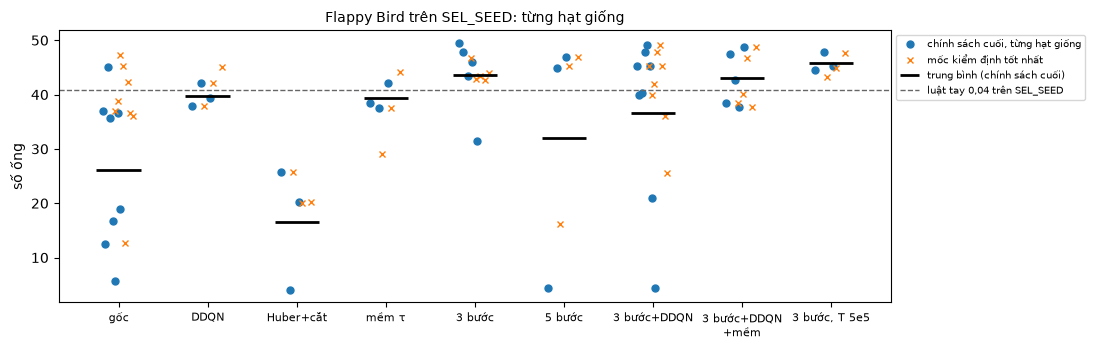

In [38]:
env_id = "FlappyBird-v0"
show_sel(env_id, ["base", "ddqn", "duel", "huberclip", "soft", "nstep3", "nstep5", "per", "C1000", "lrdecay", "T500k"],
         "Thay đổi đơn lẻ")
show_sel(env_id, ["base", "n3_ddqn", "n3_ddqn_soft", "n3_soft", "n3_lrdecay", "n3_T500k"], "Tổ hợp quanh lợi tức 3 bước")
print(f"Luật tay trên SEL_SEED: ngưỡng 0,02: {REF_SEL['FlappyBird-v0/rule_thr0.02'][0]:.1f} ống, "
      f"ngưỡng 0,04: {REF_SEL['FlappyBird-v0/rule_thr0.04'][0]:.1f} ống")
plot_sel(env_id, ["base", "ddqn", "huberclip", "soft", "nstep3", "nstep5", "n3_ddqn", "n3_ddqn_soft", "n3_T500k"],
         "Flappy Bird trên SEL_SEED: từng hạt giống", ref=("luật tay 0,04", REF_SEL["FlappyBird-v0/rule_thr0.04"][0]))

**Đọc kết quả.** Lợi tức $3$ bước là thay đổi đơn lẻ có trung bình cao nhất: $43{,}6\pm3{,}2$ ống trên năm hạt giống. Trên đúng năm hạt giống đó cấu hình gốc đạt $29{,}4$; hiệu ghép cặp là $+14{,}2$ với $t=2{,}36<2{,}776$, chưa phân biệt được ở mức $5\%$. Các thay đổi đơn lẻ khác cho trung bình như sau.

- Huber kèm cắt gradient: $16{,}6$ trên ba hạt giống ($t=-2{,}94$, chưa phân biệt được ở mức $5\%$). Huber giảm trọng số của các mẫu có $\lvert\delta_i\rvert>1$ so với các mẫu có sai số nhỏ, còn cắt chuẩn gradient giới hạn độ lớn của cả bước; với Adam, hệ số $\tfrac12$ của Huber ở vùng sai số nhỏ gần như không đổi bước tham số (mục 15.2). Notebook không đo phân bố của $\delta_i$, nên không tách được phần nào của hiệu đến từ mỗi cơ chế.
- Double DQN ($39{,}8$, $t=0{,}76$) và cập nhật mềm ($39{,}3$, $t=0{,}90$) cho trung bình cao hơn, dueling ($17{,}8$, $t=-0{,}78$) cho trung bình thấp hơn cấu hình gốc trên ba hạt giống; không hiệu nào phân biệt được ở mức $5\%$.
- $5$ bước, phát lại ưu tiên, $C=1000$ và tốc độ học giảm dần: từ $24{,}0$ tới $32{,}1$, quanh mức của cấu hình gốc.
- $T=5\cdot10^5$: chính sách cuối $22{,}1$, dù mốc tốt nhất đạt $46{,}3$. Lợi tức $3$ bước với $T=5\cdot10^5$ cho $45{,}8\pm1{,}0$ trên ba hạt giống ($t=1{,}34$, chưa phân biệt được ở mức $5\%$). Cả hai cấu hình này kéo dài lịch $\epsilon_{\mathrm{exp}}$ theo $T$, nên hiệu gộp tác dụng của ngân sách và của lịch thăm dò.

**Cấu hình chọn** là lợi tức $3$ bước kèm Double DQN. Lựa chọn được chốt khi các ứng viên có năm hạt giống: trên hạt giống $1$–$5$, cấu hình này có trung bình cao nhất và SE nhỏ nhất ($44{,}5\pm1{,}9$, so với $43{,}6\pm3{,}2$ của lợi tức $3$ bước và $43{,}0\pm2{,}3$ của lợi tức $3$ bước kèm Double DQN và cập nhật mềm, với $t=1{,}67$ so với cấu hình gốc, chưa phân biệt được ở mức $5\%$). Ba hạt giống thêm vào sau đó cho $45{,}3$; $21{,}0$; $4{,}4$, nên trung bình tám hạt giống là $36{,}6\pm5{,}6$. Mức này thấp hơn hai ứng viên kia, vốn chỉ có năm hạt giống. Lựa chọn được giữ nguyên để không đổi tiêu chí sau khi đã thấy kết quả. Ở Flappy Bird, chính sách cuối của một lần chạy vẫn có thể sụt nhiều trước $t=T$, kể cả với cấu hình chọn.

In [39]:
show_test("FlappyBird-v0", "n3_ddqn", ["luật tay 0,02", "luật tay 0,04"])

chính sách cuối          chọn   37.02 ±  5.11 | gốc   26.33 ±  5.19 | hiệu ghép cặp  +10.69 ±  7.01, t =  1.53, df = 7
                         từng hạt giống, chọn: [44.8, 42.0, 41.6, 46.3, 46.6, 43.3, 26.4, 5.0]
mốc kiểm định tốt nhất   chọn   40.95 ±  2.27 | gốc   37.17 ±  3.64 | hiệu ghép cặp   +3.78 ±  4.68, t =  0.81, df = 7
                         từng hạt giống, chọn: [44.8, 42.0, 41.5, 46.3, 46.6, 43.3, 35.2, 27.8]
tỉ lệ lượt bị cắt ngắn của chính sách cuối: chọn [0.81, 0.76, 0.74, 0.85, 0.92, 0.76, 0.16, 0.03] (TB 0.63); gốc [0.58, 0.17, 0.86, 0.42, 0.08, 0.0, 0.56, 0.1] (TB 0.35)
chọn − luật tay 0,02, từng hạt giống (trung bình ± 1,96 SE trên 100 lượt): +10.5 ± 3.0, +7.8 ± 3.8, +7.3 ± 3.8, +12.0 ± 2.9, +12.3 ± 3.0, +9.0 ± 3.5, -7.9 ± 5.1, -29.3 ± 3.2
chọn − luật tay 0,04, từng hạt giống (trung bình ± 1,96 SE trên 100 lượt): +2.3 ± 3.2, -0.4 ± 3.7, -0.9 ± 3.6, +3.8 ± 2.9, +4.1 ± 3.1, +0.8 ± 3.2, -16.1 ± 4.4, -37.5 ± 2.8


**Đọc kết quả trên `TEST_SEED`.** Chính sách cuối của cấu hình chọn đạt $37{,}0\pm5{,}1$ ống trên tám hạt giống, cấu hình gốc $26{,}3\pm5{,}2$. Hiệu ghép cặp là $+10{,}7\pm7{,}0$ với $t=1{,}53<2{,}365$, chưa phân biệt được ở mức $5\%$. Tỉ lệ trung bình các lượt đạt $50$ ống của chính sách cuối là $0{,}63$ so với $0{,}35$ của cấu hình gốc (dòng in ở trên). Vì điểm bị chặn ở $50$, trung bình số ống đánh giá thấp chính sách tốt. Với mốc kiểm định tốt nhất, hai cấu hình đạt $41{,}0$ và $37{,}2$ (hiệu $+3{,}8$, $t=0{,}81$). So với luật tay ngưỡng $0{,}04$ ($42{,}5$ ống), sáu hạt giống có hiệu từ $-0{,}9$ tới $+4{,}1$, còn hai hạt giống thấp hơn $16$ và $37$ ống, nên cấu hình chọn chưa vượt luật tay tốt nhất của mục 3. Các kết luận của mục 15.5 dựa trên bảng tám hạt giống này.

**Chạy trực tiếp.** Ô mã dưới huấn luyện cấu hình chọn với `AGENT_SEED`, khoảng $3$–$3{,}5$ phút trên CPU hai luồng khi soạn. Sau đó ô mã đánh giá trên `TEST_SEED` chính sách cuối và mốc kiểm định tốt nhất, cùng với mạng của mục 9, luật tay ngưỡng $0{,}02$ (tên "luật tay" trong bảng của `final_report`) và luật tay ngưỡng $0{,}04$.

157 giây | k_opt = 74751 | mốc kiểm định tốt nhất t = 270000


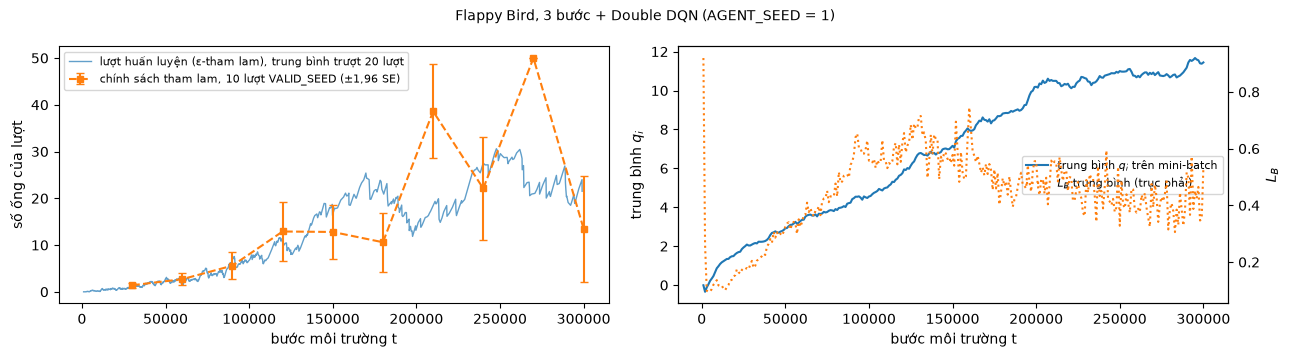

FlappyBird-v0: 100 lượt TEST_SEED, trung bình ± SE
ngẫu nhiên p=0,08          ống     0.03 ±  0.02 (sd   0.17) | G_0    3.11 | dài     49 | cắt ngắn   0%
luật tay                   ống    34.30 ±  1.30 (sd  12.95) | G_0   11.56 | dài   1334 | cắt ngắn  23%
DQN mục 9                  ống    35.64 ±  1.63 (sd  16.31) | G_0   11.37 | dài   1372 | cắt ngắn  44%
3 bước + DDQN, cuối        ống    14.29 ±  1.72 (sd  17.24) | G_0    9.12 | dài    584 | cắt ngắn  14%
3 bước + DDQN, mốc tốt nhất ống    47.65 ±  1.01 (sd  10.06) | G_0   11.27 | dài   1819 | cắt ngắn  94%
  DQN mục 9 - ngẫu nhiên p=0,08:    35.61 ±   3.19 (khoảng 95%, ghép cặp, số ống)
  DQN mục 9 - luật tay:     1.34 ±   3.72 (khoảng 95%, ghép cặp, số ống)
  3 bước + DDQN, cuối - ngẫu nhiên p=0,08:    14.26 ±   3.38 (khoảng 95%, ghép cặp, số ống)
  3 bước + DDQN, cuối - luật tay:   -20.01 ±   4.60 (khoảng 95%, ghép cặp, số ống)
  3 bước + DDQN, mốc tốt nhất - ngẫu nhiên p=0,08:    47.62 ±   1.97 (khoảng 95%, ghép cặp, số ống)
  3

luật tay 0,04              ống    42.48 ±  1.13 (sd  11.28) | G_0   11.56 | dài   1635 | cắt ngắn  51%
  DQN mục 9 - luật tay 0,04:   -6.84 ±  3.29 (khoảng 95%, ghép cặp, số ống)
  3 bước + DDQN, cuối - luật tay 0,04:  -28.19 ±  4.16 (khoảng 95%, ghép cặp, số ống)
  3 bước + DDQN, mốc tốt nhất - luật tay 0,04:    5.17 ±  2.98 (khoảng 95%, ghép cặp, số ống)


In [40]:
CFG_FLAPPY_EXT = dict(CFG["FlappyBird-v0"], T=300_000, n_step=3, double=True)
q_fb2, log_fb2, q_fb2_best = train_dqn_ext("FlappyBird-v0", CFG_FLAPPY_EXT)
print(f"{log_fb2['train_secs']:.0f} giây | k_opt = {log_fb2['k_opt']} | mốc kiểm định tốt nhất t = {log_fb2['best_t']}")
plot_learning(log_fb2, "Flappy Bird, 3 bước + Double DQN (AGENT_SEED = 1)", flappy=True)
learned_fb2 = {"DQN mục 9": q_fb, "3 bước + DDQN, cuối": q_fb2}
if log_fb2["best_t"] != CFG_FLAPPY_EXT["T"]:
    learned_fb2["3 bước + DDQN, mốc tốt nhất"] = q_fb2_best
res_fb2 = final_report("FlappyBird-v0", learned_fb2)
# Luật tay ngưỡng 0,04: mốc mạnh nhất của mục 3, đánh giá trên cùng 100 lượt TEST_SEED
res_r04 = evaluate_policy(envs["FlappyBird-v0"], lambda o, rng: flappy_rule(o, rng, 0.04), N_TEST, TEST_SEED)
summarize("luật tay 0,04", res_r04, flappy=True)
for name in learned_fb2:
    m, h = paired_difference(res_fb2[name], res_r04, "score")
    print(f"  {name} - luật tay 0,04: {m:7.2f} ± {h:5.2f} (khoảng 95%, ghép cặp, số ống)")

DQN mục 9                     1755 bước, va chạm, 45 ống
3 bước + DDQN, cuối             94 bước, va chạm, 1 ống
3 bước + DDQN, mốc tốt nhất   1906 bước, đạt 50 ống
Trình phát: 3 lượt, HTML nhúng 115 kB; vẽ mỗi 2 bước để hiển thị trọn lượt dài 1906 bước


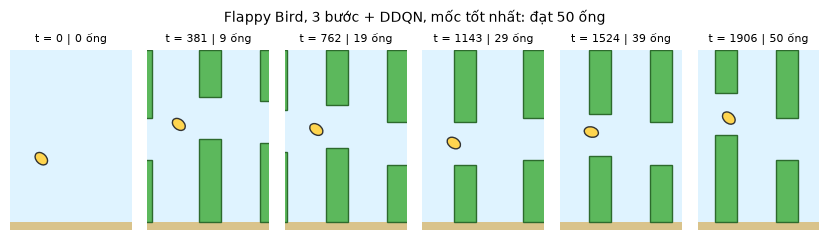

In [41]:
ep_fb2 = {name: record_episode(envs["FlappyBird-v0"], net_policy(net), TEST_SEED, "flappy") for name, net in learned_fb2.items()}
for name, ep in ep_fb2.items():
    print(f"{name:<28} {len(ep['actions']):5d} bước, {end_reason(ep)}")
display(player(ep_fb2))
name_last = list(ep_fb2)[-1]
filmstrip(ep_fb2[name_last], 6, f"Flappy Bird, {name_last}: {end_reason(ep_fb2[name_last])}"); plt.show()

**Đọc kết quả của lần chạy trực tiếp.** Khi soạn, lần chạy này cho kết quả sau trên `TEST_SEED`.

- Chính sách cuối đạt $14{,}3$ ống, kém mạng của mục 9 ($35{,}6$ ống). Đây là chiều ngược với bảng tám hạt giống.
- Mốc kiểm định tốt nhất, ở $t=270\,000$, đạt $47{,}6$ ống, với $94\%$ lượt đạt $50$ ống.
- So với luật tay ngưỡng $0{,}04$ trên cùng $100$ lượt, mốc tốt nhất có hiệu ghép cặp $+5{,}2\pm3{,}0$ ống (khoảng $95\%$ không chứa $0$), còn chính sách cuối có hiệu $-28{,}2\pm4{,}2$ ống. Đây là một lần chạy, nên hiệu dương của mốc tốt nhất không thay được bảng tám hạt giống, nơi trung bình của mốc tốt nhất ($41{,}0$) thấp hơn luật tay này.

Lần chạy hai luồng của cùng hạt giống ở giai đoạn chọn cấu hình cũng cho $14{,}3$ ống, nhưng trên `SEL_SEED`. Hai con số trùng nhau là ngẫu nhiên, vì hai tập lượt khác nhau.

Đường kiểm định ở hình trái cho cùng kết luận: mốc $t=270\,000$ đạt $50$ ống trên $10$ lượt `VALID_SEED`, còn mốc cuối chỉ còn khoảng $13$. Ở hình phải, trung bình $q_i$ tăng đều tới khoảng $11{,}5$ và không tăng không chặn. Mức này cùng cỡ với lợi tức chiết khấu $G_0=11{,}6$ của luật tay ở mục 3. Chính sách tham lam dao động theo $t$ trong khi giá trị vẫn bị chặn: theo phân biệt của Nhận xét 07.39, đây là chính sách kém ở một số mốc, không phải dấu hiệu phân kỳ, và Nhận xét 08.21 không loại trừ hiện tượng này. Lần chạy này minh họa rằng chọn mốc kiểm định có ích ở môi trường này.

### 15.6. Tổng kết mục 15

Trên hai môi trường, với tối đa tám hạt giống mỗi cấu hình, các con số cho bốn kết quả.

- **Lunar Lander, cùng ngân sách $10^5$ bước:** chỉ phát lại ưu tiên cho hiệu với cấu hình gốc vượt ngưỡng không hiệu chỉnh (trung bình thấp hơn, $t=-4{,}60$), và không hiệu nào vượt ngưỡng Bonferroni. Cấu hình của mục 8 vẫn dùng được ở ngân sách này.
- **Lunar Lander, ngân sách $3\cdot10^5$ bước:** tốc độ học giảm dần về $\eta/10$ cho trung bình cao hơn $\eta$ cố định trên ba hạt giống chung ($251{,}6$ so với $215{,}6$; $t=1{,}79$, chưa phân biệt được ở mức $5\%$). Thêm lợi tức $3$ bước và Double DQN cho $261{,}1\pm3{,}5$ trên tập chọn và $258{,}1\pm3{,}6$ trên `TEST_SEED`, cao hơn cấu hình gốc một cách phân biệt được ($t=2{,}97$). So với bộ điều khiển viết tay, hiệu trên `TEST_SEED` là $+21{,}2$. Hiệu này phân biệt được khi coi $100$ lượt `TEST_SEED` là cố định ($t=5{,}89$), nhưng chưa đủ để kết luận như một phát biểu về môi trường ($t\approx1{,}98$ khi tính cả nhiễu theo lượt và giữa các hạt giống, sát ngưỡng $5\%$); trên `SEL_SEED`, hiệu chỉ là $+8{,}3$. Cùng thay đổi tốc độ học cho trung bình thấp hơn ở ngân sách $10^5$ bước ($t=-2{,}06$, chưa phân biệt được ở mức $5\%$).
- **Flappy Bird, ngân sách $3\cdot10^5$ bước:** lợi tức $3$ bước, riêng hoặc kèm Double DQN, cho trung bình cao hơn cấu hình gốc trên mọi tập đã đo, nhưng không hiệu nào phân biệt được ở mức $5\%$ ($t=1{,}53$ trên `TEST_SEED` với tám hạt giống). Cấu hình chọn chưa vượt luật tay với ngưỡng $0{,}04$.
- **Các thay đổi không cho hiệu phân biệt được với cấu hình gốc** (trừ phát lại ưu tiên ở ngưỡng không hiệu chỉnh): phát lại ưu tiên với tốc độ học của cấu hình gốc và mạng rộng hơn trên Lunar Lander cho trung bình thấp hơn; Huber kèm cắt gradient trên Flappy Bird cho trung bình thấp hơn ($t=-2{,}94$); dueling và cập nhật mềm cho hiệu từ $-13{,}7$ tới $+11{,}4$ trên hai môi trường, nhỏ so với độ phân tán giữa các hạt giống.

Bằng chứng trên có giới hạn rõ. Mỗi phép so dùng ba tới tám hạt giống, và nhiều phép so được thực hiện mà không hiệu chỉnh. Lần chạy hai luồng của cùng một hạt giống cho số liệu khác lần chạy một luồng. Ba hạt giống đầu của lợi tức $3$ bước trên Lunar Lander ở $10^5$ bước, và năm hạt giống đầu của cấu hình chọn trên Flappy Bird, đều cho trung bình cao hơn trung bình sau khi thêm hạt giống. Các kết luận trên gắn với hai môi trường, các ngân sách và các siêu tham số đã thử, và theo Nhận xét 08.21, Thuật toán 08.13 cùng các biến thể của nó không có bảo đảm hội tụ tổng quát.

Chính sách tham lam dao động theo $t$, nên chính sách cuối và mốc kiểm định tốt nhất khác nhau nhiều ở Flappy Bird. Trong khi đó, giá trị lớn nhất của trung bình $q_i$ vẫn bị chặn ở mọi cấu hình đã thử (từ $5$ tới $12$ trên Flappy Bird; không quá $116$ trên Lunar Lander). Theo tiêu chí của Nhận xét 07.39, giá trị bị chặn cùng chính sách kém ở một số mốc là hiện tượng khác với phân kỳ. Cả hai cấu hình chọn dùng Double DQN và mục tiêu $3$ bước, nằm ngoài phạm vi của Mệnh đề 08.8 (mục 15.2).

In [42]:
print(f"Tổng thời gian chạy notebook, tính cả mục 15: {time.time() - T_START:.0f} giây ({(time.time() - T_START) / 60:.1f} phút)")

Tổng thời gian chạy notebook, tính cả mục 15: 777 giây (12.9 phút)


### Tài liệu tham khảo

**Tài liệu của học phần**

- Tạ Việt Cường, *Bài giảng 8: Deep Q-Learning*, bài giảng gốc học kỳ 2 năm học 2025–2026: tr. 14–17, 20–21 (mạng giá trị hành động, mục tiêu hồi quy), tr. 18–20, 30, 32 (bộ nhớ phát lại), tr. 21 (giả mã DQN), tr. 29–34 (bất ổn và mạng mục tiêu).
- Ghi chú Bài 07: Định nghĩa 07.38, Nhận xét 07.39.
- Ghi chú Bài 08: Định nghĩa 08.1, 08.3, 08.4, 08.6, 08.7, 08.10, 08.12, 08.17, 08.18; Thuật toán 08.13; Mệnh đề 08.8; Nhận xét 08.2, 08.9, 08.14, 08.19–08.21; Ví dụ 08.5, 08.7, 08.8, 08.10, 08.13–08.15, 08.24; Bài tập 08.1, 08.3.
- Ghi chú Bài 09: mục "Sai lệch cực đại và ví dụ Rademacher", mục "Đích Double DQN" và ví dụ "Đối chiếu hai đích" (mục 15.2 của notebook này gọi đại lượng đó là mục tiêu).
- Các notebook thực hành Bài 04 (CartPole) và Bài 07 (Lunar Lander, Flappy Bird): chính sách tham chiếu, cách đánh giá và trình phát.

**Bài báo và sách** (theo năm)

- R. S. Sutton, "Learning to predict by the methods of temporal differences", *Machine Learning* 3, 1988, 9–44.
- D. P. Kingma, J. Ba, "Adam: A Method for Stochastic Optimization", *ICLR*, 2015.
- V. Mnih và cộng sự, "Human-level control through deep reinforcement learning", *Nature* 518, 2015, 529–533: mục Methods, Extended Data Table 1 và 3.
- H. van Hasselt, A. Guez, D. Silver, "Deep Reinforcement Learning with Double Q-learning", *AAAI*, 2016, arXiv:1509.06461.
- Z. Wang, T. Schaul, M. Hessel, H. van Hasselt, M. Lanctot, N. de Freitas, "Dueling Network Architectures for Deep Reinforcement Learning", *ICML*, 2016, arXiv:1511.06581 (phương trình 9).
- T. Schaul, J. Quan, I. Antonoglou, D. Silver, "Prioritized Experience Replay", *ICLR*, 2016, arXiv:1511.05952.
- T. P. Lillicrap và cộng sự, "Continuous control with deep reinforcement learning", *ICLR*, 2016 (cập nhật mềm).
- M. Hessel và cộng sự, "Rainbow: Combining Improvements in Deep Reinforcement Learning", *AAAI*, 2018, arXiv:1710.02298 (lợi tức $n$ bước trong DQN, thí nghiệm loại bỏ).
- F. Pardo, A. Tavakoli, V. Levdik, P. Kormushev, "Time Limits in Reinforcement Learning", *ICML*, 2018.
- R. S. Sutton, A. G. Barto, *Reinforcement Learning: An Introduction*, ấn bản 2, MIT Press, 2018: §6.7, chương 7 (§7.1, lợi tức $n$ bước), §11.2–11.3, §16.5.

**Phần mềm, cấu hình và mã nguồn**

- Tài liệu và mã nguồn `CartPole-v1`, `LunarLander-v3` (Gymnasium 1.x); tài liệu `torch.nn`, `torch.optim.Adam`, `torch.nn.utils.clip_grad_norm_` của PyTorch.
- `flappy-bird-gymnasium` 0.4.0, commit `e7eb59e2a8`: https://github.com/markub3327/flappy-bird-gymnasium/blob/e7eb59e2a8/flappy_bird_gymnasium/envs/flappy_bird_env.py.
- A. Raffin và cộng sự, *RL Baselines3 Zoo*, commit `b8a11d6e0e`: https://github.com/DLR-RM/rl-baselines3-zoo/blob/b8a11d6e0e/hyperparams/dqn.yml (dòng 58–71, mục `LunarLander-v3`; cấu hình xuất phát cho Lunar Lander ở mục 7) và https://github.com/DLR-RM/rl-baselines3-zoo/blob/b8a11d6e0e/benchmark.md (mục 15.1).
- Stable-Baselines3, commit `b2878f4b83` (phiên bản 2.9.2a0): https://github.com/DLR-RM/stable-baselines3/blob/b2878f4b83/stable_baselines3/dqn/dqn.py (Huber `smooth_l1_loss`, `max_grad_norm = 10`); bản phát hành 2.9.0 trên PyPI có cùng hai thiết lập.
- Thẻ mô hình: https://huggingface.co/sb3/dqn-LunarLander-v2, https://huggingface.co/araffin/dqn-LunarLander-v2, https://huggingface.co/OpenDILabCommunity/LunarLander-v2-DQN.
- DI-engine, commit `d0b21d065b`: https://github.com/opendilab/DI-engine/blob/d0b21d065b/dizoo/box2d/lunarlander/config/lunarlander_dqn_config.py.
- CleanRL, commit `fe8d8a03c4`: https://github.com/vwxyzjn/cleanrl/blob/fe8d8a03c4/cleanrl/dqn.py.
- Các kho đã kiểm cho Flappy Bird (mục 15.1): https://github.com/johnnycode8/dqn_pytorch/tree/24ccb030ed, https://github.com/yenchenlin/DeepLearningFlappyBird, https://github.com/chncyhn/flappybird-qlearning-bot, https://github.com/samiuls25/rl_dqn_flappybird.